<a href="https://colab.research.google.com/github/mingahkim-bit/2020-2026/blob/main/Salinan_dari_skripsi_hybrid_sarima_gru_20_26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Peramalan ND Harian dengan Hybrid SARIMA–GRU

**Data:** ND harian, 1 Januari 2019 – 31 Oktober 2026  |  **Target:** forecast 1–30 November 2026  
**Pendekatan:** hybrid residual (SARIMA + GRU), evaluasi one-step-ahead, pembagian data 70 / 15 / 15

---

## Tahap 1 — Persiapan dan Pemeriksaan Data

Tahap ini memastikan lingkungan kerja dapat diulang (*reproducible*) dan data layak dianalisis.

| Langkah | Isi |
|:--|:--|
| 1.1 | Konfigurasi, seed, dan tema visual |
| 1.2 | Pemuatan data dan validasi struktur |
| 1.3 | Pemeriksaan kualitas data (duplikat, tanggal hilang, nilai tidak wajar) |
| 1.4 | Penanganan nilai hilang |
| 1.5 | Statistik deskriptif |
| 1.6 | Ringkasan visual data |
| 1.7 | Penyimpanan data bersih |

> Tahap ini **tidak** melakukan normalisasi atau pembagian data, agar tidak terjadi kebocoran informasi (*data leakage*).

## 1.1 Konfigurasi, Seed, dan Tema Visual

Semua parameter penelitian dikumpulkan di satu tempat. **Ubah hanya sel ini** jika ada perubahan pengaturan.

In [40]:
import importlib.util
import os
import platform
import random
import warnings
from dataclasses import dataclass
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import FuncFormatter
from scipy import stats

warnings.filterwarnings("ignore")


@dataclass(frozen=True)
class Config:
    # --- data ---
    data_path: str = "https://raw.githubusercontent.com/rifahannabilah11-art/data/main/NESO_ND_Harian_2019_2026_Bersih.csv"   # lokasi file CSV
    date_col: str = "Date"
    target_col: str = "ND"
    start_date: str = "2020-01-01"            # rentang waktu analisis dimulai dari 2020-01-01
    end_date: str = "2026-10-31"         # tanggal akhir yang diharapkan
    # --- pemodelan (dipakai pada tahap berikutnya) ---
    seasonal_period: int = 7             # musiman mingguan
    fourier_k: int = 3                   # harmonik musiman tahunan
    split: tuple = (0.70, 0.15, 0.15)    # train, validasi, test
    horizon: int = 30                    # 1-30 November 2026
    # --- kontrol kualitas ---
    max_missing_pct: float = 1.0         # batas imputasi otomatis (%)
    outlier_z: float = 4.0
    # --- kalender (data NESO = Inggris/Great Britain) ---
    negara_libur: str = "UK"             # kode negara untuk pustaka `holidays`
    wilayah_libur: str = "ENG"           # England & Wales (hari libur bank)
    # --- reproduksibilitas & output ---
    seed: int = 42
    processed_dir: str = "data_2020/processed"
    figure_dir: str = "results_2020/figures"
    table_dir: str = "results_2020/tables"


CFG = Config()
for folder in (CFG.processed_dir, CFG.figure_dir, CFG.table_dir):
    Path(folder).mkdir(parents=True, exist_ok=True)

# --- seed ---
os.environ["PYTHONHASHSEED"] = str(CFG.seed)
random.seed(CFG.seed)
np.random.seed(CFG.seed)
if importlib.util.find_spec("tensorflow") is not None:
    import tensorflow as tf
    tf.random.set_seed(CFG.seed)
    TF_VERSION = tf.__version__
else:
    TF_VERSION = "belum terpasang (dibutuhkan pada tahap GRU)"

# --- versi lingkungan (untuk dicantumkan di skripsi) ---
env = pd.DataFrame(
    {
        "Komponen": ["Python", "pandas", "numpy", "scipy", "matplotlib", "tensorflow"],
        "Versi": [
            platform.python_version(), pd.__version__, np.__version__,
            __import__("scipy").__version__, matplotlib.__version__, TF_VERSION,
        ],
    }
).set_index("Komponen")
print(f"Seed global: {CFG.seed}")
display(env)

Seed global: 42


,Versi
Komponen,
Python,3.13.18
pandas,2.2.3
numpy,2.4.6
scipy,1.16.3
matplotlib,3.10.0
tensorflow,2.21.0


In [41]:
# ------------------------- Tema visual (konsisten di seluruh notebook) -------------------------
PALETTE = {
    "primary":   "#1F4E79",   # biru tua   : seri utama
    "secondary": "#4F81BD",   # biru       : seri pendukung
    "light":     "#BFD3E6",   # biru muda  : data mentah
    "accent":    "#C0504D",   # merah      : sorotan / forecast
    "warning":   "#E69F00",   # oranye     : titik imputasi / peringatan
    "neutral":   "#6B7280",   # abu        : teks sekunder
    "grid":      "#E5E7EB",
    "text":      "#1F2937",
}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 220, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.edgecolor": PALETTE["grid"], "axes.labelcolor": PALETTE["text"],
    "axes.titleweight": "bold", "axes.titlesize": 11.5, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": PALETTE["grid"], "grid.linewidth": 0.8,
    "xtick.color": PALETTE["neutral"], "ytick.color": PALETTE["neutral"],
    "legend.frameon": False, "legend.fontsize": 9,
})

ribuan = FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", "."))   # 35.000 (format Indonesia)


def angka(x, desimal=0):
    """Format angka gaya Indonesia: 35.041,38"""
    s = f"{x:,.{desimal}f}"
    return s.replace(",", "X").replace(".", ",").replace("X", ".")


BULAN = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]


def tgl(ts):
    """Format tanggal berbahasa Indonesia: 01 Jan 2019"""
    return f"{ts.day:02d} {BULAN[ts.month - 1]} {ts.year}"


def judul_figur(fig, judul, subjudul=None):
    tinggi = fig.get_figheight()   # posisi dihitung dalam inci agar tidak tumpang tindih di figur pendek
    fig.text(0.012, 1 - 0.06 / tinggi, judul, fontsize=15, fontweight="bold", color=PALETTE["text"], ha="left", va="top")
    if subjudul:
        fig.text(0.012, 1 - 0.40 / tinggi, subjudul, fontsize=10, color=PALETTE["neutral"], ha="left", va="top")


def simpan_figur(fig, nama):
    path = Path(CFG.figure_dir) / f"{nama}.png"
    fig.savefig(path)
    print(f"Figur disimpan: {path}")

## 1.2 Pemuatan Data dan Validasi Struktur

Data dibaca, kolom diperiksa, lalu tanggal dan nilai ND diubah ke tipe yang benar. Nilai yang gagal dikonversi **ditandai**, tidak dibuang diam-diam.

In [42]:
raw = pd.read_csv(CFG.data_path)
raw[CFG.date_col] = pd.to_datetime(raw[CFG.date_col], errors="coerce")
raw = raw[raw[CFG.date_col] >= pd.Timestamp(CFG.start_date)]

kolom_wajib = {CFG.date_col, CFG.target_col}
hilang = kolom_wajib - set(raw.columns)
assert not hilang, f"Kolom tidak ditemukan: {hilang}. Kolom tersedia: {list(raw.columns)}"

raw = raw[[CFG.date_col, CFG.target_col]].copy()
n_baris_mentah = len(raw)

raw[CFG.target_col] = pd.to_numeric(raw[CFG.target_col], errors="coerce")

n_tanggal_invalid = int(raw[CFG.date_col].isna().sum())
n_nilai_invalid = int(raw[CFG.target_col].isna().sum())
raw = raw.dropna(subset=[CFG.date_col])

print(f"Baris terbaca (>= {CFG.start_date}) : {n_baris_mentah:,}".replace(",", "."))
print(f"Tanggal tidak valid                 : {n_tanggal_invalid}")
print(f"Nilai ND non-numerik                : {n_nilai_invalid}")
display(raw.head(5))

Baris terbaca (>= 2020-01-01) : 2.496
Tanggal tidak valid                 : 0
Nilai ND non-numerik                : 0


,Date,ND
365,2020-01-01,28966.416667
366,2020-01-02,30905.062500
367,2020-01-03,31908.145833
368,2020-01-04,29747.312500
369,2020-01-05,29390.104167


## 1.3 Pemeriksaan Kualitas Data

Pemeriksaan dilakukan sebelum perbaikan apa pun, supaya semua masalah tercatat dan dapat dilaporkan di Bab 3.

In [43]:
# --- duplikat tanggal ---
n_duplikat = int(raw[CFG.date_col].duplicated().sum())
if n_duplikat:
    print(f"Ditemukan {n_duplikat} tanggal duplikat -> dirata-ratakan per tanggal.")
    raw = raw.groupby(CFG.date_col, as_index=False)[CFG.target_col].mean()

raw = raw.sort_values(CFG.date_col).set_index(CFG.date_col)

# --- paksa frekuensi harian: tanggal yang hilang muncul sebagai NaN ---
indeks_penuh = pd.date_range(raw.index.min(), raw.index.max(), freq="D")
y_raw = raw[CFG.target_col].reindex(indeks_penuh)
y_raw.index.name = CFG.date_col

n_hari_seharusnya = len(indeks_penuh)
n_missing = int(y_raw.isna().sum())
pct_missing = 100 * n_missing / n_hari_seharusnya
n_nonpositif = int((y_raw <= 0).sum())

awal_ok = y_raw.index.min() == pd.Timestamp(CFG.start_date)
akhir_ok = y_raw.index.max() == pd.Timestamp(CFG.end_date)


def status(ok):
    return "OK" if ok else "PERIKSA"


laporan = pd.DataFrame(
    [
        ("Tanggal pertama", y_raw.index.min().date(), status(awal_ok)),
        ("Tanggal terakhir", y_raw.index.max().date(), status(akhir_ok)),
        ("Jumlah hari seharusnya", f"{n_hari_seharusnya:,}".replace(",", "."), "OK"),
        ("Baris data mentah", f"{n_baris_mentah:,}".replace(",", "."), "OK"),
        ("Tanggal duplikat", n_duplikat, status(n_duplikat == 0)),
        ("Tanggal tidak valid", n_tanggal_invalid, status(n_tanggal_invalid == 0)),
        ("Nilai hilang (termasuk tanggal yang hilang)", f"{n_missing} ({pct_missing:.2f}%)", status(n_missing == 0)),
        ("Nilai nol atau negatif", n_nonpositif, status(n_nonpositif == 0)),
    ],
    columns=["Pemeriksaan", "Hasil", "Status"],
).set_index("Pemeriksaan")

display(laporan)
laporan.to_csv(Path(CFG.table_dir) / "01_laporan_kualitas_data.csv")

if not (awal_ok and akhir_ok):
    print("PERHATIAN: rentang tanggal tidak sama dengan konfigurasi. "
          "Pastikan baris terakhir data benar-benar 31 Oktober 2026, "
          "karena forecast dimulai dari hari setelah data terakhir.")

,Hasil,Status
Pemeriksaan,,
Tanggal pertama,2020-01-01,OK
Tanggal terakhir,2026-10-31,OK
Jumlah hari seharusnya,2.496,OK
Baris data mentah,2.496,OK
Tanggal duplikat,0,OK
Tanggal tidak valid,0,OK
Nilai hilang (termasuk tanggal yang hilang),0 (0.00%),OK
Nilai nol atau negatif,0,OK


## 1.4 Penanganan Nilai Hilang

Aturan keputusan:

- **Tidak ada nilai hilang** → tidak ada tindakan.
- **Hilang ≤ batas (`max_missing_pct`)** → interpolasi berbasis waktu; titik yang diisi **dicatat** agar bisa dilaporkan dan ditandai pada grafik.
- **Hilang > batas** → proses dihentikan. Keputusan penanganan harus diambil secara sadar dan dijelaskan di skripsi.

In [44]:
imputed_mask = y_raw.isna()

if n_missing == 0:
    print("Tidak ada nilai hilang. Imputasi tidak diperlukan.")
    y = y_raw.copy()
elif pct_missing <= CFG.max_missing_pct:
    y = y_raw.interpolate(method="time", limit_direction="both")
    print(f"{n_missing} nilai hilang ({pct_missing:.2f}%) diisi dengan interpolasi waktu.")
    display(pd.DataFrame({"Tanggal": y_raw.index[imputed_mask].date,
                          "Nilai hasil imputasi": y[imputed_mask].round(2).values}).set_index("Tanggal"))
else:
    raise ValueError(
        f"Nilai hilang {pct_missing:.2f}% melebihi batas {CFG.max_missing_pct}%. "
        "Tentukan strategi penanganan secara manual dan dokumentasikan alasannya."
    )

y.name = CFG.target_col
y = y.asfreq("D")
assert y.isna().sum() == 0 and y.index.is_monotonic_increasing and y.index.freq is not None
print(f"Deret siap pakai: {len(y):,} hari, {y.index[0].date()} s.d. {y.index[-1].date()}".replace(",", "."))

Tidak ada nilai hilang. Imputasi tidak diperlukan.
Deret siap pakai: 2.496 hari. 2020-01-01 s.d. 2026-10-31


## 1.5 Statistik Deskriptif

Tabel ini langsung dapat dipakai di Bab 4 (gambaran umum data).

In [45]:
desc = y.describe(percentiles=[0.25, 0.5, 0.75])
ringkas = pd.Series(
    {
        "Jumlah data (hari)": int(desc["count"]),
        "Rata-rata": desc["mean"],
        "Simpangan baku": desc["std"],
        "Koefisien variasi (%)": 100 * desc["std"] / desc["mean"],
        "Minimum": desc["min"],
        "Kuartil 1 (Q1)": desc["25%"],
        "Median": desc["50%"],
        "Kuartil 3 (Q3)": desc["75%"],
        "Maksimum": desc["max"],
        "Skewness": stats.skew(y),
        "Kurtosis (excess)": stats.kurtosis(y),
    },
    name="ND",
)
tabel_desc = ringkas.round(2).to_frame()
display(tabel_desc)
tabel_desc.to_csv(Path(CFG.table_dir) / "02_statistik_deskriptif.csv")

# ringkasan per tahun
per_tahun = (
    y.groupby(y.index.year)
    .agg(["count", "mean", "std", "min", "max"])
    .rename(columns={"count": "Hari", "mean": "Rata-rata", "std": "Simpangan baku", "min": "Min", "max": "Maks"})
    .round(1)
)
per_tahun.index.name = "Tahun"
display(per_tahun)
per_tahun.to_csv(Path(CFG.table_dir) / "03_ringkasan_per_tahun.csv")

# kandidat outlier (hanya ditandai; keputusan diambil di Tahap 2 setelah dekomposisi STL)
z = (y - y.mean()) / y.std()
print(f"Titik dengan |z| > {CFG.outlier_z}: {(z.abs() > CFG.outlier_z).sum()} "
      "(indikasi awal saja; pemeriksaan outlier yang lebih tepat memakai residual STL pada tahap EDA)")

,ND
Jumlah data (hari),2496.00
Rata-rata,26592.68
Simpangan baku,4305.79
Koefisien variasi (%),16.19
Minimum,16486.54
Kuartil 1 (Q1),23364.39
Median,25915.36
Kuartil 3 (Q3),29571.98
Maksimum,37982.96
Skewness,0.39


,Hari,Rata-rata,Simpangan baku,Min,Maks
Tahun,,,,,
2020,366,27156.4,4585.4,17560.2,36608.9
2021,365,28345.2,3744.2,21274.8,37519.4
2022,365,26622.5,4171.4,18293.3,37587.2
2023,365,26051.9,4068.4,17714.7,36019.1
2024,366,26286.7,4070.5,18114.6,37011.6
2025,365,26157.6,4560.0,16486.5,37983.0
2026,304,25313.9,4283.4,17873.3,37647.9


Titik dengan |z| > 4.0: 0 (indikasi awal saja; pemeriksaan outlier yang lebih tepat memakai residual STL pada tahap EDA)


## 1.6 Ringkasan Visual Data

Tiga panel: **(a)** perjalanan deret waktu beserta rata-rata bergerak, **(b)** sebaran nilai ND, **(c)** sebaran per tahun.

Figur disimpan: results_2020/figures/01_ringkasan_data.png


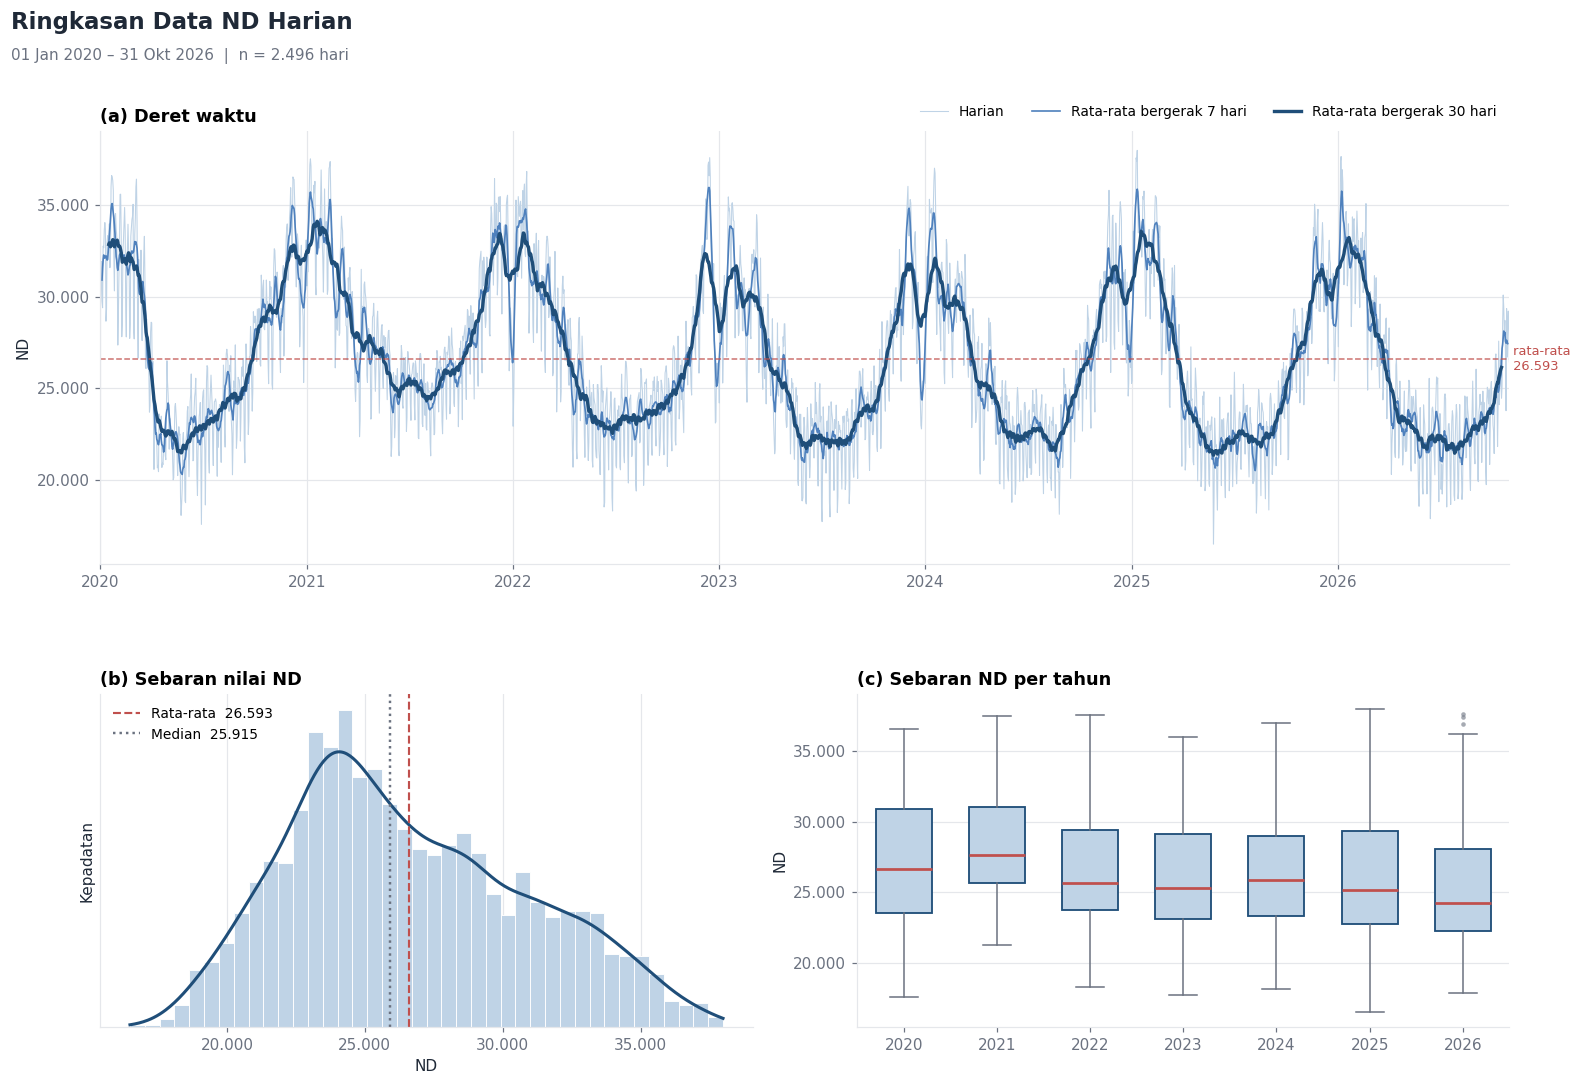

In [46]:
fig = plt.figure(figsize=(14, 10))
gs = GridSpec(2, 2, figure=fig, height_ratios=[1.3, 1], hspace=0.34, wspace=0.16,
              left=0.07, right=0.985, top=0.885, bottom=0.07)
judul_figur(
    fig,
    "Ringkasan Data ND Harian",
    f"{tgl(y.index[0])} – {tgl(y.index[-1])}  |  n = {len(y):,} hari".replace(",", "."),
)

# (a) deret waktu
ax1 = fig.add_subplot(gs[0, :])
ax1.plot(y.index, y, color=PALETTE["light"], lw=0.7, label="Harian")
ax1.plot(y.rolling(7, center=True).mean(), color=PALETTE["secondary"], lw=1.1, label="Rata-rata bergerak 7 hari")
ax1.plot(y.rolling(30, center=True).mean(), color=PALETTE["primary"], lw=2.2, label="Rata-rata bergerak 30 hari")
if imputed_mask.any():
    ax1.scatter(y.index[imputed_mask], y[imputed_mask], s=28, color=PALETTE["warning"],
                zorder=5, label="Nilai hasil imputasi")
ax1.axhline(y.mean(), color=PALETTE["accent"], ls="--", lw=1, alpha=0.8)
ax1.text(y.index[-1], y.mean(), f" rata-rata\n {angka(y.mean())}", color=PALETTE["accent"],
         fontsize=8.5, va="center", ha="left")
ax1.set_title("(a) Deret waktu")
ax1.set_ylabel("ND")
ax1.yaxis.set_major_formatter(ribuan)
ax1.set_xlim(y.index[0], y.index[-1])
ax1.legend(loc="lower right", ncol=4, bbox_to_anchor=(1.0, 1.0))

# (b) histogram + KDE
ax2 = fig.add_subplot(gs[1, 0])
ax2.hist(y, bins=40, density=True, color=PALETTE["light"], edgecolor="white", linewidth=0.6)
xs = np.linspace(y.min(), y.max(), 400)
ax2.plot(xs, stats.gaussian_kde(y)(xs), color=PALETTE["primary"], lw=2)
ax2.axvline(y.mean(), color=PALETTE["accent"], ls="--", lw=1.4, label=f"Rata-rata  {angka(y.mean())}")
ax2.axvline(y.median(), color=PALETTE["neutral"], ls=":", lw=1.6, label=f"Median  {angka(y.median())}")
ax2.set_title("(b) Sebaran nilai ND")
ax2.set_xlabel("ND")
ax2.set_ylabel("Kepadatan")
ax2.xaxis.set_major_formatter(ribuan)
ax2.set_yticks([])
ax2.legend(loc="upper left")

# (c) boxplot per tahun
ax3 = fig.add_subplot(gs[1, 1])
tahun = sorted(y.index.year.unique())
bp = ax3.boxplot([y[y.index.year == t].values for t in tahun], patch_artist=True, widths=0.6,
                 medianprops=dict(color=PALETTE["accent"], lw=1.8),
                 whiskerprops=dict(color=PALETTE["neutral"]), capprops=dict(color=PALETTE["neutral"]),
                 flierprops=dict(marker="o", markersize=3, markerfacecolor=PALETTE["neutral"],
                                 markeredgecolor="none", alpha=0.6))
for box in bp["boxes"]:
    box.set(facecolor=PALETTE["light"], edgecolor=PALETTE["primary"], linewidth=1.2)
ax3.set_xticks(range(1, len(tahun) + 1))
ax3.set_xticklabels(tahun)
ax3.set_title("(c) Sebaran ND per tahun")
ax3.set_ylabel("ND")
ax3.yaxis.set_major_formatter(ribuan)
ax3.grid(axis="x", visible=False)

simpan_figur(fig, "01_ringkasan_data")
plt.show()

## 1.7 Penyimpanan Data Bersih

Data bersih disimpan beserta penanda imputasi. Tahap berikutnya cukup memuat file ini.

In [47]:
data_bersih = pd.DataFrame({CFG.target_col: y, "diimputasi": imputed_mask.reindex(y.index).fillna(False).astype(int)})
data_bersih.index.name = CFG.date_col
path_bersih = Path(CFG.processed_dir) / "nd_clean.csv"
data_bersih.to_csv(path_bersih)

ringkasan = pd.DataFrame(
    [
        ("Berkas data bersih", str(path_bersih)),
        ("Periode", f"{y.index[0].date()} s.d. {y.index[-1].date()}"),
        ("Jumlah hari", f"{len(y):,}".replace(",", ".")),
        ("Nilai diimputasi", int(imputed_mask.sum())),
        ("Frekuensi", "harian (D)"),
        ("Periode musiman", f"{CFG.seasonal_period} (mingguan) + Fourier K={CFG.fourier_k} (tahunan)"),
        ("Rencana pembagian", " / ".join(f"{int(r*100)}" for r in CFG.split) + " (train / validasi / test)"),
        ("Horizon forecast", f"{CFG.horizon} hari (mulai {(y.index[-1] + pd.Timedelta(days=1)).date()})"),
    ],
    columns=["Item", "Nilai"],
).set_index("Item")
display(ringkasan)
print("\nTahap 1 selesai. Lanjut ke Tahap 2: EDA (STL, ACF/PACF, outlier).")

,Nilai
Item,
Berkas data bersih,data_2020/processed/nd_clean.csv
Periode,2020-01-01 s.d. 2026-10-31
Jumlah hari,2.496
Nilai diimputasi,0
Frekuensi,harian (D)
Periode musiman,7 (mingguan) + Fourier K=3 (tahunan)
Rencana pembagian,70 / 15 / 15 (train / validasi / test)
Horizon forecast,30 hari (mulai 2026-11-01)



Tahap 1 selesai. Lanjut ke Tahap 2: EDA (STL, ACF/PACF, outlier).


---

## Tahap 2 — Analisis Eksplorasi Data (EDA)

Tujuan: memahami pola data **sebelum** memilih model. Hasil tahap ini menjadi dasar untuk memilih periode musiman, differencing, dan membenarkan penggunaan suku Fourier.

| Langkah | Isi |
|:--|:--|
| 2.1 | Dekomposisi STL multi-musiman (mingguan dan tahunan) |
| 2.2 | Pemeriksaan outlier pada residual dekomposisi |
| 2.3 | Pola musiman: per hari, per tahun, per bulan |
| 2.4 | ACF dan PACF |
| 2.5 | Ringkasan temuan EDA |

> EDA bersifat **deskriptif**. Tidak ada data yang diubah atau dibuang pada tahap ini.

## 2.1 Dekomposisi STL Multi-Musiman

Data harian umumnya memiliki dua pola musiman: **mingguan (7)** dan **tahunan (365)**. Dekomposisi memakai MSTL (perluasan STL untuk lebih dari satu periode musiman) yang memisahkan data menjadi:

`ND = tren + musiman tahunan + musiman mingguan + residual`

Kekuatan komponen dihitung dengan ukuran Wang, Smith & Hyndman: nilai mendekati 1 berarti komponen dominan, di atas **0,64** dianggap kuat.

In [48]:
import statsmodels
from statsmodels.tsa.seasonal import MSTL
from statsmodels.tsa.stattools import acf, pacf

assert "y" in globals(), "Jalankan Tahap 1 terlebih dahulu (variabel y belum ada)."
print(f"statsmodels {statsmodels.__version__}")

HARI = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]

mstl = MSTL(y, periods=(CFG.seasonal_period, 365), stl_kwargs={"robust": True}).fit()
tren = mstl.trend
s_mingguan = mstl.seasonal[f"seasonal_{CFG.seasonal_period}"]
s_tahunan = mstl.seasonal["seasonal_365"]
resid_stl = mstl.resid


def kekuatan(komponen, resid):
    """Ukuran kekuatan komponen (0-1): 1 - Var(resid) / Var(resid + komponen)."""
    return max(0.0, 1 - resid.var() / (resid + komponen).var())


kuat = pd.DataFrame(
    {
        "Komponen": ["Tren", "Musiman mingguan (7)", "Musiman tahunan (365)"],
        "Kekuatan": [kekuatan(tren, resid_stl), kekuatan(s_mingguan, resid_stl), kekuatan(s_tahunan, resid_stl)],
    }
).set_index("Komponen")
kuat["Kategori"] = np.where(kuat["Kekuatan"] > 0.64, "Kuat", np.where(kuat["Kekuatan"] > 0.3, "Sedang", "Lemah"))
kuat["Kekuatan"] = kuat["Kekuatan"].round(3)
display(kuat)
kuat.to_csv(Path(CFG.table_dir) / "04_kekuatan_komponen_stl.csv")

statsmodels 0.15.0


,Kekuatan,Kategori
Komponen,,
Tren,0.219,Lemah
Musiman mingguan (7),0.487,Sedang
Musiman tahunan (365),0.855,Kuat


Figur disimpan: results_2020/figures/02_dekomposisi_stl.png


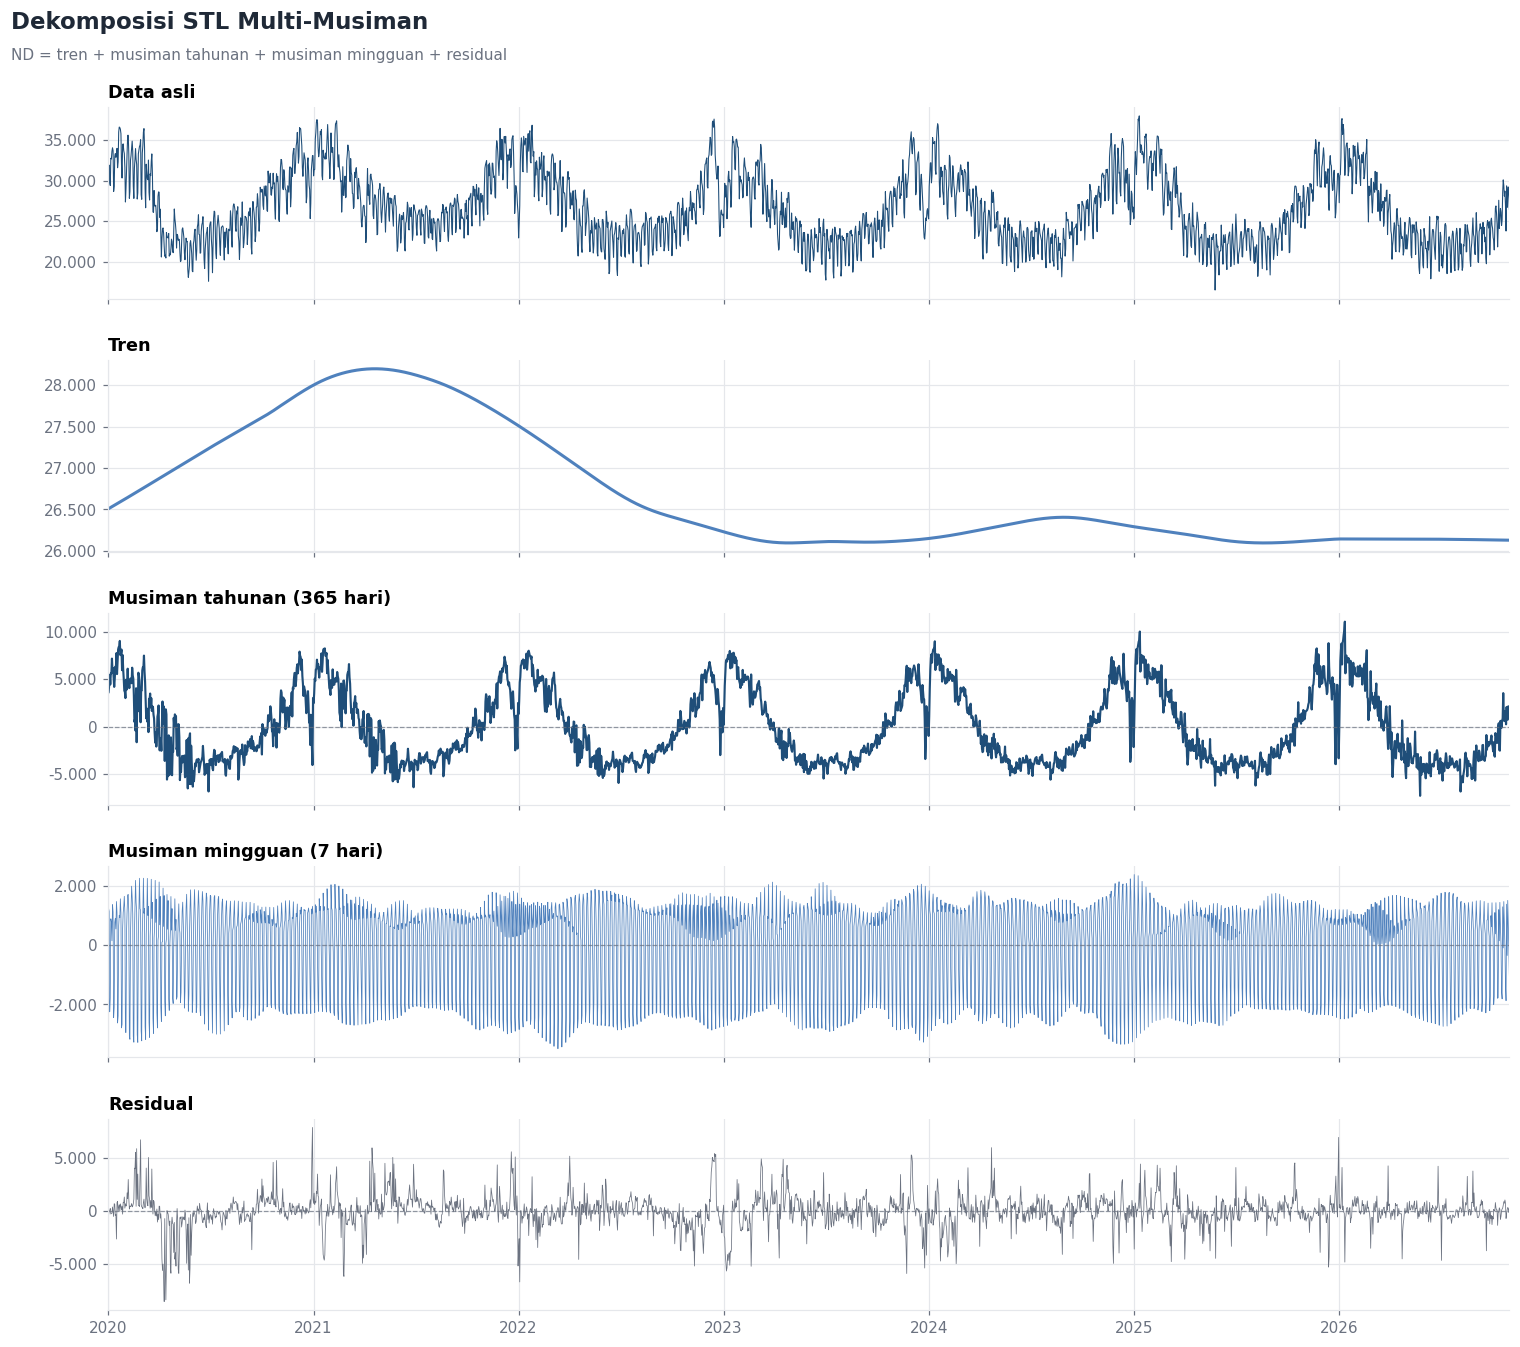

In [49]:
fig, axes = plt.subplots(5, 1, figsize=(14, 12.5), sharex=True, gridspec_kw={"hspace": 0.32})
judul_figur(fig, "Dekomposisi STL Multi-Musiman",
            "ND = tren + musiman tahunan + musiman mingguan + residual")
fig.subplots_adjust(left=0.075, right=0.985, top=0.925, bottom=0.05)

paneles = [
    ("Data asli", y, PALETTE["primary"], 0.7),
    ("Tren", tren, PALETTE["secondary"], 2.0),
    ("Musiman tahunan (365 hari)", s_tahunan, PALETTE["primary"], 1.4),
    (f"Musiman mingguan ({CFG.seasonal_period} hari)", s_mingguan, PALETTE["secondary"], 0.5),
    ("Residual", resid_stl, PALETTE["neutral"], 0.5),
]
for ax, (nama, seri, warna, lw) in zip(axes, paneles):
    ax.plot(seri.index, seri, color=warna, lw=lw)
    ax.set_title(nama)
    ax.yaxis.set_major_formatter(ribuan)
    ax.set_xlim(y.index[0], y.index[-1])
    if nama != "Data asli" and nama != "Tren":
        ax.axhline(0, color=PALETTE["neutral"], lw=0.8, ls="--", alpha=0.7)

simpan_figur(fig, "02_dekomposisi_stl")
plt.show()

## 2.2 Pemeriksaan Outlier

Outlier dicari pada **residual STL** (bukan pada data mentah), karena pola musiman dan tren yang wajar sudah dihilangkan. Titik ditandai bila |z| melebihi batas (`CFG.outlier_z`, default 4).

> **Titik yang ditandai tidak dihapus otomatis.** Periksa satu per satu: apakah hari libur nasional, kejadian khusus, atau kesalahan pencatatan? Keputusan dan alasannya dicatat di skripsi.

In [50]:
z_res = (resid_stl - resid_stl.mean()) / resid_stl.std()
tandai = z_res.abs() > CFG.outlier_z
perhatian = z_res.abs() > 3

print(f"Residual STL | rata-rata = {angka(resid_stl.mean(), 1)}, simpangan baku = {angka(resid_stl.std(), 1)}")
print(f"|z| > 3 (perlu diperhatikan): {int(perhatian.sum())} titik")
print(f"|z| > {CFG.outlier_z:g} (ditandai sebagai outlier): {int(tandai.sum())} titik")

top = z_res.abs().sort_values(ascending=False).head(10).index.sort_values()
tabel_outlier = pd.DataFrame(
    {
        "Hari": [HARI[d.dayofweek] for d in top],
        "ND": y.loc[top].round(1).values,
        "Residual": resid_stl.loc[top].round(1).values,
        "z": z_res.loc[top].round(2).values,
        "Ditandai": np.where(tandai.loc[top], "Ya", "Tidak"),
    },
    index=pd.Index([d.date() for d in top], name="Tanggal"),
)
print("\n10 titik dengan |z| terbesar:")
display(tabel_outlier)
tabel_outlier.to_csv(Path(CFG.table_dir) / "05_kandidat_outlier.csv")

Residual STL | rata-rata = -4,1, simpangan baku = 1.506,5
|z| > 3 (perlu diperhatikan): 71 titik
|z| > 4 (ditandai sebagai outlier): 9 titik

10 titik dengan |z| terbesar:


,Hari,ND,Residual,z,Ditandai
Tanggal,,,,,
2020-02-28,Jumat,35039.7,6663.7,4.43,Ya
2020-04-09,Kamis,23442.4,-6235.0,-4.14,Ya
2020-04-10,Jumat,21891.0,-8524.3,-5.66,Ya
2020-04-13,Senin,20440.3,-8352.8,-5.54,Ya
2020-05-25,Senin,19537.0,-6799.4,-4.51,Ya
2020-12-30,Rabu,33076.6,7822.6,5.20,Ya
2021-02-24,Rabu,28164.4,-6160.2,-4.09,Ya
2022-01-03,Senin,26873.8,-6678.0,-4.43,Ya
2024-04-22,Senin,28830.9,5928.0,3.94,Tidak


Figur disimpan: results_2020/figures/03_outlier_residual_stl.png


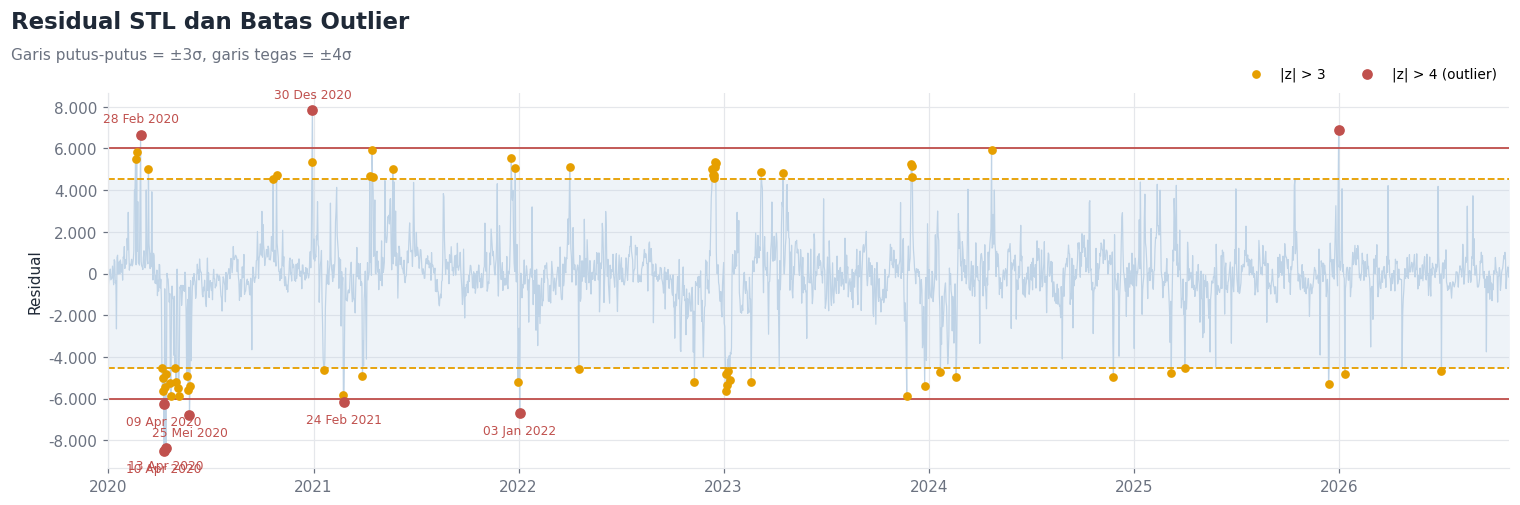

In [51]:
fig, ax = plt.subplots(figsize=(14, 4.8))
judul_figur(fig, "Residual STL dan Batas Outlier", "Garis putus-putus = ±3σ, garis tegas = ±" + f"{CFG.outlier_z:g}σ")
fig.subplots_adjust(left=0.075, right=0.985, top=0.83, bottom=0.12)

sd, mu = resid_stl.std(), resid_stl.mean()
ax.plot(resid_stl.index, resid_stl, color=PALETTE["light"], lw=0.8)
ax.fill_between(resid_stl.index, mu - 3 * sd, mu + 3 * sd, color=PALETTE["light"], alpha=0.25, lw=0)
for k, ls in ((3, "--"), (CFG.outlier_z, "-")):
    for sign in (-1, 1):
        ax.axhline(mu + sign * k * sd, color=PALETTE["accent"] if k == CFG.outlier_z else PALETTE["warning"],
                   ls=ls, lw=1.2)
ax.scatter(resid_stl.index[perhatian & ~tandai], resid_stl[perhatian & ~tandai], s=22,
           color=PALETTE["warning"], zorder=4, label="|z| > 3")
ax.scatter(resid_stl.index[tandai], resid_stl[tandai], s=36, color=PALETTE["accent"], zorder=5,
           label=f"|z| > {CFG.outlier_z:g} (outlier)")
for d in resid_stl.index[tandai][:8]:
    ax.annotate(tgl(d), (d, resid_stl[d]), xytext=(0, 8 if resid_stl[d] > 0 else -14),
                textcoords="offset points", ha="center", fontsize=8, color=PALETTE["accent"])
ax.set_ylabel("Residual")
ax.yaxis.set_major_formatter(ribuan)
ax.set_xlim(resid_stl.index[0], resid_stl.index[-1])
ax.legend(loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=2)
simpan_figur(fig, "03_outlier_residual_stl")
plt.show()

## 2.3 Pola Musiman

Tiga sudut pandang: **(a)** profil rata-rata per hari dalam seminggu, **(b)** pola tahunan tiap tahun ditumpuk (menunjukkan apakah pola berulang dan adanya pergeseran level), **(c)** peta panas rata-rata bulanan.

Figur disimpan: results_2020/figures/04_pola_musiman.png


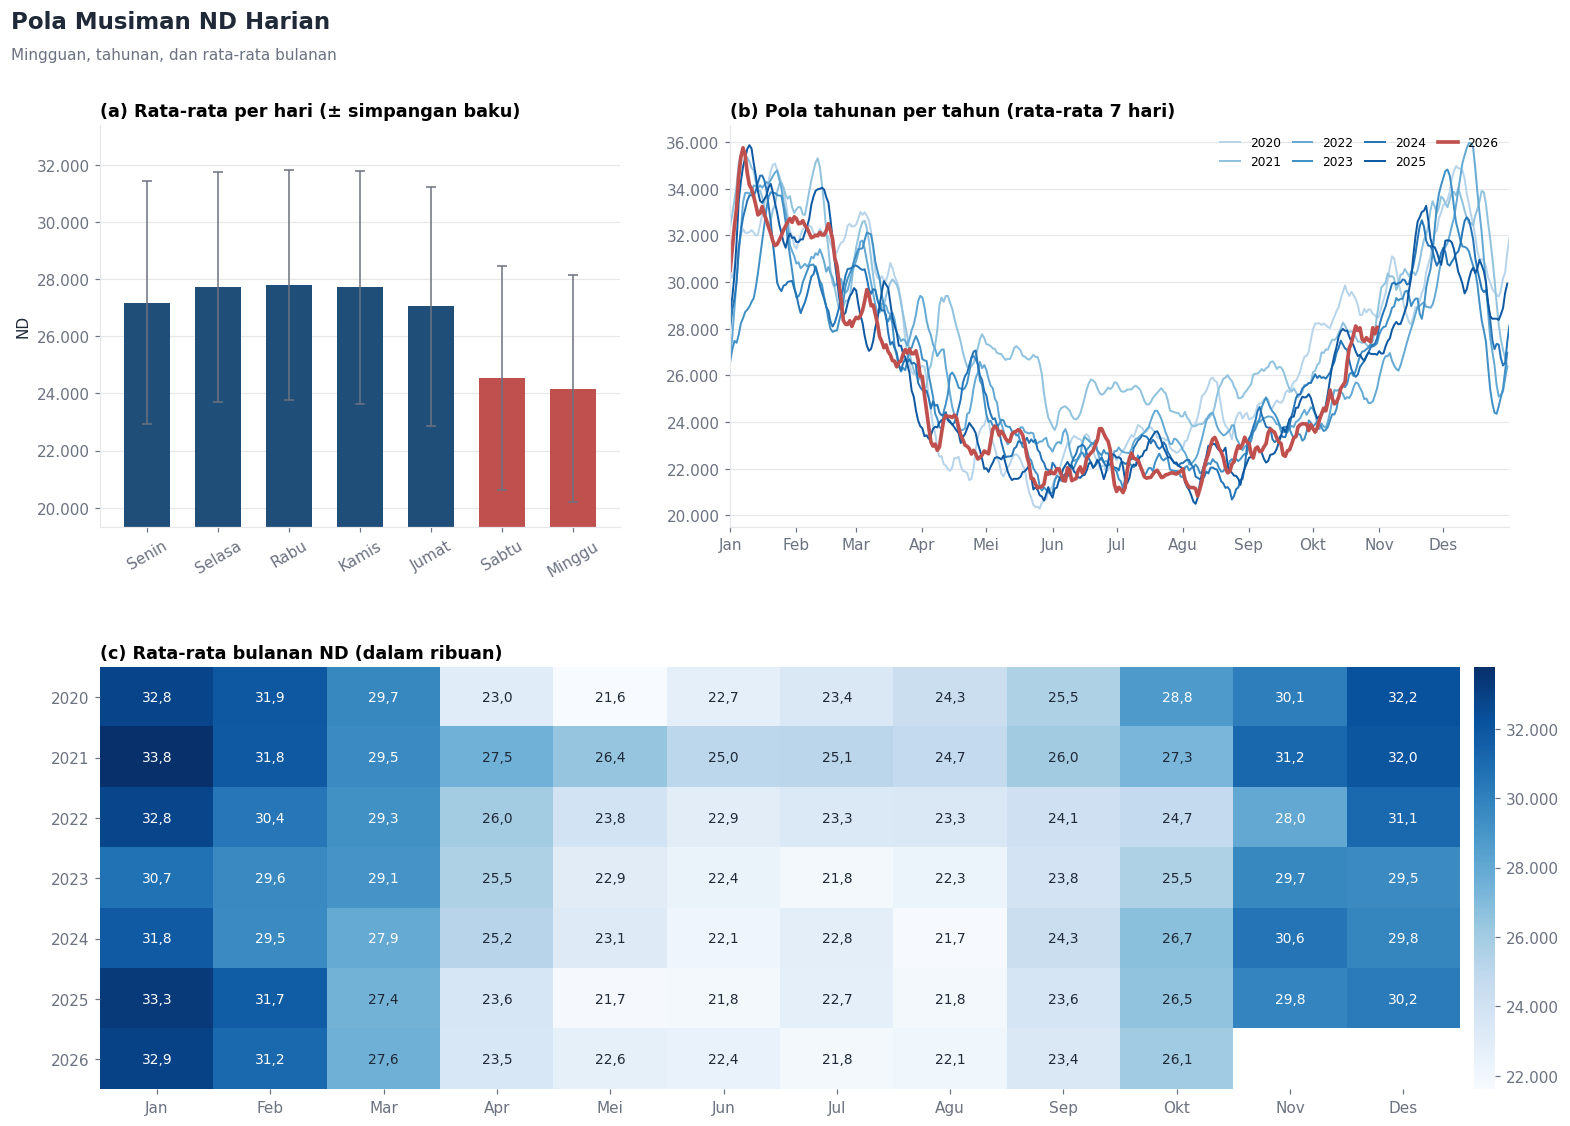

In [52]:
fig = plt.figure(figsize=(14, 10.5))
gs = GridSpec(2, 2, figure=fig, height_ratios=[1, 1.05], width_ratios=[1, 1.5], hspace=0.34, wspace=0.17,
              left=0.07, right=0.985, top=0.895, bottom=0.06)
judul_figur(fig, "Pola Musiman ND Harian", "Mingguan, tahunan, dan rata-rata bulanan")

# (a) profil per hari
ax1 = fig.add_subplot(gs[0, 0])
per_hari = y.groupby(y.index.dayofweek).agg(["mean", "std"])
warna_bar = [PALETTE["accent"] if i >= 5 else PALETTE["primary"] for i in range(7)]
ax1.bar(HARI, per_hari["mean"], color=warna_bar, width=0.65, yerr=per_hari["std"], capsize=3,
        error_kw=dict(ecolor=PALETTE["neutral"], lw=1))
ax1.set_ylim(per_hari["mean"].min() * 0.8, None)
ax1.set_title("(a) Rata-rata per hari (± simpangan baku)")
ax1.set_ylabel("ND")
ax1.yaxis.set_major_formatter(ribuan)
ax1.tick_params(axis="x", rotation=30)
ax1.grid(axis="x", visible=False)

# (b) pola tahunan bertumpuk
ax2 = fig.add_subplot(gs[0, 1])
rata7 = y.rolling(7, center=True, min_periods=4).mean()
tahun = sorted(y.index.year.unique())
cmap = plt.get_cmap("Blues")
for i, t in enumerate(tahun):
    s = rata7[rata7.index.year == t]
    terakhir = t == tahun[-1]
    ax2.plot(s.index.dayofyear, s.values, lw=2.4 if terakhir else 1.3, label=str(t),
             color=PALETTE["accent"] if terakhir else cmap(0.3 + 0.65 * i / max(1, len(tahun) - 1)))
awal_bulan = [1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335]
ax2.set_xticks(awal_bulan)
ax2.set_xticklabels(BULAN)
ax2.set_xlim(1, 366)
ax2.set_title("(b) Pola tahunan per tahun (rata-rata 7 hari)")
ax2.yaxis.set_major_formatter(ribuan)
ax2.legend(ncol=4, loc="upper right", fontsize=8, columnspacing=1.0, handlelength=1.6)
ax2.grid(axis="x", visible=False)

# (c) peta panas tahun x bulan
ax3 = fig.add_subplot(gs[1, :])
pivot = y.groupby([y.index.year, y.index.month]).mean().unstack().reindex(columns=range(1, 13))
im = ax3.imshow(pivot.values, aspect="auto", cmap="Blues")
ax3.set_xticks(range(12))
ax3.set_xticklabels(BULAN)
ax3.set_yticks(range(len(pivot)))
ax3.set_yticklabels(pivot.index)
batas = (np.nanmin(pivot.values) + np.nanmax(pivot.values)) / 2
for i in range(pivot.shape[0]):
    for j in range(12):
        v = pivot.values[i, j]
        if not np.isnan(v):
            ax3.text(j, i, angka(v / 1000, 1), ha="center", va="center", fontsize=9,
                     color="white" if v > batas else PALETTE["text"])
ax3.set_title("(c) Rata-rata bulanan ND (dalam ribuan)")
ax3.grid(False)
for sp in ax3.spines.values():
    sp.set_visible(False)
cb = fig.colorbar(im, ax=ax3, pad=0.01, fraction=0.025)
cb.ax.yaxis.set_major_formatter(ribuan)
cb.outline.set_visible(False)

simpan_figur(fig, "04_pola_musiman")
plt.show()

## 2.4 ACF dan PACF

Dihitung pada data asli sampai lag 60. Lag kelipatan 7 (oranye/merah) disorot untuk memeriksa **musiman mingguan**. Pita biru = batas kepercayaan 95% (±1,96/√n); batang di luar pita signifikan.

Data asli yang memiliki tren/pola tahunan akan menunjukkan ACF yang turun sangat lambat. Itu wajar dan menjadi alasan differencing pada Tahap 3.

Figur disimpan: results_2020/figures/05_acf_pacf.png


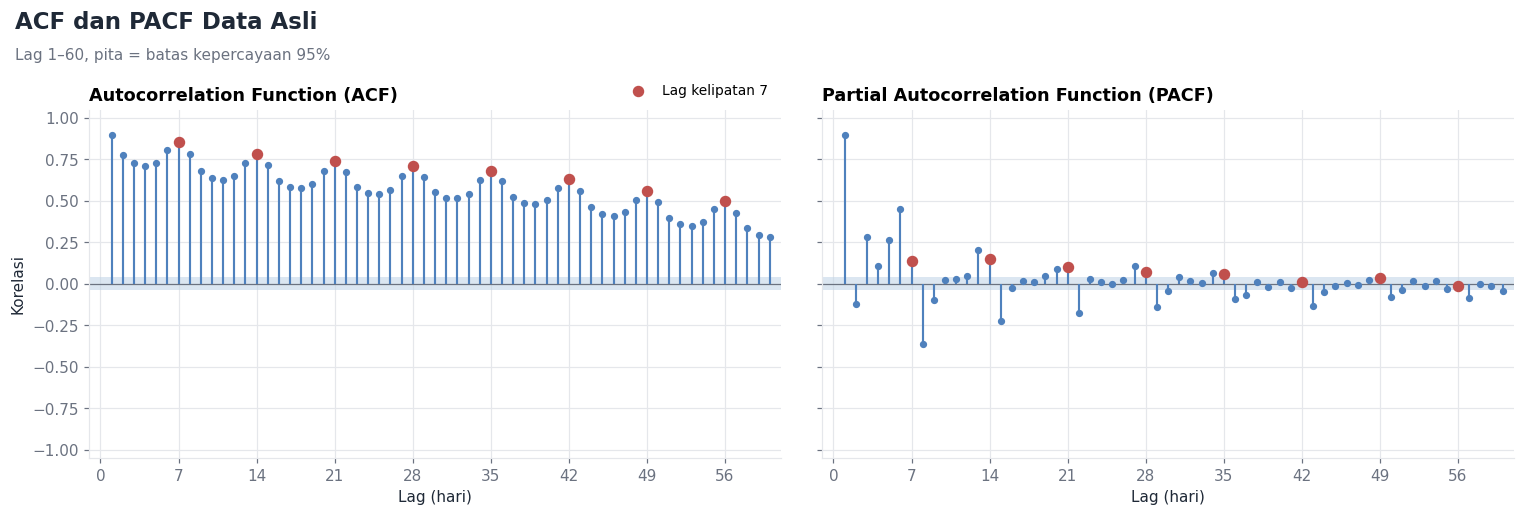

,ACF
Lag,
1,0.895
7,0.857
14,0.786
21,0.740
28,0.711
365,0.653


In [53]:
NLAGS = 60
ac = acf(y, nlags=NLAGS, fft=True)
pc = pacf(y, nlags=NLAGS, method="ywm")
batas_ci = 1.96 / np.sqrt(len(y))


def gambar_stem(ax, nilai, judul):
    lags = np.arange(len(nilai))
    musiman = (lags % CFG.seasonal_period == 0) & (lags > 0)
    ax.axhspan(-batas_ci, batas_ci, color=PALETTE["light"], alpha=0.55, lw=0)
    ax.axhline(0, color=PALETTE["neutral"], lw=0.8)
    ax.vlines(lags[1:], 0, nilai[1:], color=PALETTE["secondary"], lw=1.4)
    ax.scatter(lags[1:][~musiman[1:]], nilai[1:][~musiman[1:]], s=14, color=PALETTE["secondary"], zorder=3)
    ax.scatter(lags[musiman], nilai[musiman], s=42, color=PALETTE["accent"], zorder=4,
               label=f"Lag kelipatan {CFG.seasonal_period}")
    ax.set_xticks(np.arange(0, len(nilai), CFG.seasonal_period))
    ax.set_xlim(-1, len(nilai))
    ax.set_ylim(-1.05, 1.05)
    ax.set_xlabel("Lag (hari)")
    ax.set_title(judul)


fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
judul_figur(fig, "ACF dan PACF Data Asli", f"Lag 1–{NLAGS}, pita = batas kepercayaan 95%")
fig.subplots_adjust(left=0.06, right=0.985, top=0.80, bottom=0.14, wspace=0.06)
gambar_stem(a1, ac, "Autocorrelation Function (ACF)")
gambar_stem(a2, pc, "Partial Autocorrelation Function (PACF)")
a1.set_ylabel("Korelasi")
a1.legend(loc="lower right", bbox_to_anchor=(1.0, 1.0))
simpan_figur(fig, "05_acf_pacf")
plt.show()

ac_panjang = acf(y, nlags=365, fft=True)
tabel_acf = pd.DataFrame({"Lag": [1, 7, 14, 21, 28, 365], "ACF": [ac_panjang[k] for k in (1, 7, 14, 21, 28, 365)]})
tabel_acf["ACF"] = tabel_acf["ACF"].round(3)
display(tabel_acf.set_index("Lag"))

## 2.5 Ringkasan Temuan EDA

Tabel ini merangkum angka-angka kunci untuk Bab 4 dan menjadi pegangan keputusan pada Tahap 3.

In [54]:
rata_hari = y.groupby(y.index.dayofweek).mean()
rata_bulan = y.groupby(y.index.month).mean()
tahun_penuh = [t for t in sorted(y.index.year.unique()) if (y.index.year == t).sum() >= 365]
rata_tahun = y.groupby(y.index.year).mean()
perubahan = 100 * (rata_tahun[tahun_penuh[-1]] / rata_tahun[tahun_penuh[0]] - 1)

temuan = pd.DataFrame(
    [
        ("Kekuatan tren", f"{kuat.loc['Tren', 'Kekuatan']:.3f} ({kuat.loc['Tren', 'Kategori']})"),
        ("Kekuatan musiman mingguan", f"{kuat.loc['Musiman mingguan (7)', 'Kekuatan']:.3f} ({kuat.loc['Musiman mingguan (7)', 'Kategori']})"),
        ("Kekuatan musiman tahunan", f"{kuat.loc['Musiman tahunan (365)', 'Kekuatan']:.3f} ({kuat.loc['Musiman tahunan (365)', 'Kategori']})"),
        ("Hari rata-rata tertinggi", f"{HARI[int(rata_hari.idxmax())]} ({angka(rata_hari.max())})"),
        ("Hari rata-rata terendah", f"{HARI[int(rata_hari.idxmin())]} ({angka(rata_hari.min())})"),
        ("Bulan rata-rata tertinggi", f"{BULAN[int(rata_bulan.idxmax()) - 1]} ({angka(rata_bulan.max())})"),
        ("Bulan rata-rata terendah", f"{BULAN[int(rata_bulan.idxmin()) - 1]} ({angka(rata_bulan.min())})"),
        (f"Perubahan rata-rata tahunan {tahun_penuh[0]} → {tahun_penuh[-1]}", f"{angka(perubahan, 1)}%"),
        ("ACF lag 7", f"{ac[7]:.3f}"),
        ("Titik outlier (|z| > %g)" % CFG.outlier_z, int(tandai.sum())),
    ],
    columns=["Temuan", "Nilai"],
).set_index("Temuan")
display(temuan)
temuan.to_csv(Path(CFG.table_dir) / "06_ringkasan_temuan_eda.csv")
print("\nTahap 2 selesai. Lanjut ke Tahap 3: pembagian data (train / validasi / test).")

,Nilai
Temuan,
Kekuatan tren,0.219 (Lemah)
Kekuatan musiman mingguan,0.487 (Sedang)
Kekuatan musiman tahunan,0.855 (Kuat)
Hari rata-rata tertinggi,Rabu (27.786)
Hari rata-rata terendah,Minggu (24.165)
Bulan rata-rata tertinggi,Jan (32.579)
Bulan rata-rata terendah,Jun (22.761)
Perubahan rata-rata tahunan 2020 → 2025,"-3,7%"
ACF lag 7,0.857



Tahap 2 selesai. Lanjut ke Tahap 3: pembagian data (train / validasi / test).


### Catatan peristiwa yang mungkin memengaruhi data

Isi sendiri setelah melihat grafik di atas (pada sel markdown ini):

- Penurunan atau lonjakan tidak biasa pada 2020 (misalnya dampak COVID-19)?
- Titik outlier jatuh pada hari libur nasional atau kejadian khusus tertentu?
- Perubahan level atau tren jangka panjang pada tahun tertentu?

Catatan ini dipakai di Bab 4 (pembahasan) dan di bagian keterbatasan penelitian.

---

## Tahap 3 — Pembagian Data (Train / Validasi / Test)

Tujuan: membagi data **berurutan waktu** tanpa kebocoran informasi, dan **membuktikan secara empiris** bahwa skema pembagian yang dipilih layak.

| Langkah | Isi |
|:--|:--|
| 3.1 | Laporan perbandingan beberapa skema pembagian |
| 3.2 | Visualisasi skema pembagian |
| 3.3 | Pemilihan skema dan pembentukan `y_train`, `y_val`, `y_test` |
| 3.4 | Pemeriksaan keabsahan (urutan waktu, tanpa tumpang tindih) dan penyimpanan |

Prinsip yang tidak boleh dilanggar:

1. Data dibagi **berurutan waktu**, bukan acak.
2. **Train**: melatih SARIMA dan GRU. **Validasi**: memilih hyperparameter GRU dan early stopping. **Test**: hanya untuk evaluasi akhir.
3. Semua keputusan pemodelan (orde SARIMA, scaler, hyperparameter) hanya boleh memakai train dan validasi.

## 3.1 Laporan Perbandingan Skema Pembagian

Setiap skema dinilai dengan kriteria yang dapat diperiksa:

| Kriteria | Alasan |
|:--|:--|
| Train ≥ 3 tahun | Pola tahunan perlu beberapa siklus agar terpelajari |
| Validasi dan test mencakup **12 bulan** | Semua musim terwakili, evaluasi tidak bias ke musim tertentu |
| Validasi dan test ≥ 180 hari | Jumlah sampel cukup untuk menghitung metrik yang stabil |
| Uji KS dan Levene terhadap train | Informasi seberapa berbeda distribusi dan varians segmen dari train (**bukan** syarat lulus/gagal) |
| RMSE seasonal naive | Tolok ukur tingkat kesulitan tiap segmen |

> Perbedaan distribusi yang nyata (p kecil) biasanya akibat tren turun atau patahan struktural (misalnya COVID-19), bukan berarti pembagian salah. Namun perlu dibahas sebagai risiko generalisasi.

In [55]:
from statsmodels.tsa.stattools import adfuller

SKEMA = {                       # (train, validasi, test)
    "80/20":    (0.80, 0.00, 0.20),
    "70/30":    (0.70, 0.00, 0.30),
    "80/10/10": (0.80, 0.10, 0.10),
    "70/15/15": (0.70, 0.15, 0.15),
    "60/20/20": (0.60, 0.20, 0.20),
}
WARNA_SEG = {"Train": PALETTE["primary"], "Validasi": PALETTE["warning"], "Test": PALETTE["accent"]}


def batas_split(n, rasio):
    """Indeks akhir train dan akhir validasi (pembagian berurutan waktu)."""
    n_tr = int(n * rasio[0])
    n_va = int(n * rasio[1])
    return n_tr, n_tr + n_va


def potong(seri, rasio):
    a, b = batas_split(len(seri), rasio)
    return {"Train": seri.iloc[:a], "Validasi": seri.iloc[a:b], "Test": seri.iloc[b:]}


baris = []
for nama, rasio in SKEMA.items():
    seg = potong(y, rasio)
    for bagian, s in seg.items():
        if len(s) == 0:
            continue
        naive = (s - y.shift(CFG.seasonal_period).loc[s.index]).dropna()
        baris.append({
            "Skema": nama, "Bagian": bagian, "n": len(s), "Tahun": round(len(s) / 365.25, 2),
            "Mulai": s.index[0].date(), "Selesai": s.index[-1].date(),
            "Rata-rata": round(s.mean()), "Simpangan baku": round(s.std()),
            "Bulan tercakup": s.index.month.nunique(),
            "ADF p": round(adfuller(s, autolag="AIC")[1], 3),
            "KS p vs train": round(stats.ks_2samp(seg["Train"], s).pvalue, 4) if bagian != "Train" else np.nan,
            "Levene p vs train": round(stats.levene(seg["Train"], s).pvalue, 4) if bagian != "Train" else np.nan,
            "RMSE naive-7": round(np.sqrt((naive ** 2).mean())) if bagian != "Train" else np.nan,
        })

laporan_split = pd.DataFrame(baris).set_index(["Skema", "Bagian"])
display(laporan_split)
laporan_split.to_csv(Path(CFG.table_dir) / "07_laporan_pembagian_data.csv")

n  Tahun       Mulai     Selesai  Rata-rata  \
Skema    Bagian                                                     
80/20    Train     1996   5.46  2020-01-01  2025-06-18      26891   
         Test       500   1.37  2025-06-19  2026-10-31      25403   
70/30    Train     1747   4.78  2020-01-01  2024-10-12      26776   
         Test       749   2.05  2024-10-13  2026-10-31      26164   
80/10/10 Train     1996   5.46  2020-01-01  2025-06-18      26891   
         Validasi   249   0.68  2025-06-19  2026-02-22      27010   
         Test       251   0.69  2026-02-23  2026-10-31      23809   
70/15/15 Train     1747   4.78  2020-01-01  2024-10-12      26776   
         Validasi   374   1.02  2024-10-13  2025-10-21      26202   
         Test       375   1.03  2025-10-22  2026-10-31      26126   
60/20/20 Train     1497   4.10  2020-01-01  2024-02-05      27146   
         Validasi   499   1.37  2024-02-06  2025-06-18      26125   
         Test       500   1.37  2025-06-19  2026-10-31      25403   

                   Simpangan baku  Bulan tercakup  ADF p  KS p vs train  \
Skema    Bagian                                                           
80/20    Train               4294              12  0.065            NaN   
         Test                4147              12  0.626         0.0000   
70/30    Train               4224              12  0.007            NaN   
         Test                4465              12  0.561         0.0000   
80/10/10 Train               4294              12  0.065            NaN   
         Validasi            4635               9  0.754         0.0925   
         Test                2810               9  0.326         0.0000   
70/15/15 Train               4224              12  0.007            NaN   
         Validasi            4574              12  0.601         0.0004   
         Test                4360              12  0.726         0.0011   
60/20/20 Train               4261              12  0.022            NaN   
         Validasi            4306              12  0.485         0.0000   
         Test                4147              12  0.626         0.0000   

                   Levene p vs train  RMSE naive-7  
Skema    Bagian                                     
80/20    Train                   NaN           NaN  
         Test                 0.0377        2166.0  
70/30    Train                   NaN           NaN  
         Test                 0.0238        2337.0  
80/10/10 Train                   NaN           NaN  
         Validasi             0.0045        2279.0  
         Test                 0.0000        2047.0  
70/15/15 Train                   NaN           NaN  
         Validasi             0.0193        2399.0  
         Test                 0.2525        2274.0  
60/20/20 Train                   NaN           NaN  
         Validasi             0.7128        2252.0  
         Test                 0.0764        2166.0

In [56]:
# ------------------ Penilaian otomatis tiap skema ------------------
penilaian = []
for nama, rasio in SKEMA.items():
    sub = laporan_split.loc[nama]
    ada_val = "Validasi" in sub.index
    catatan = []
    if sub.loc["Train", "Tahun"] < 3:
        catatan.append("train < 3 tahun")
    for bagian in [b for b in ("Validasi", "Test") if b in sub.index]:
        if sub.loc[bagian, "Bulan tercakup"] < 12:
            catatan.append(f"{bagian.lower()} < 12 bulan")
        if sub.loc[bagian, "n"] < 180:
            catatan.append(f"{bagian.lower()} < 180 hari")
    if not ada_val:
        catatan.append("tidak ada data validasi")
    penilaian.append({
        "Skema": nama, "Punya validasi": "Ya" if ada_val else "Tidak",
        "Train (tahun)": sub.loc["Train", "Tahun"],
        "Validasi (tahun)": sub.loc["Validasi", "Tahun"] if ada_val else np.nan,
        "Test (tahun)": sub.loc["Test", "Tahun"],
        "Kelayakan": "Layak" if not catatan else "Tidak layak",
        "Catatan": "; ".join(catatan) if catatan else "-",
        "_ntrain": sub.loc["Train", "n"],
    })

tabel_nilai = pd.DataFrame(penilaian).set_index("Skema")
display(tabel_nilai.drop(columns="_ntrain"))
tabel_nilai.drop(columns="_ntrain").to_csv(Path(CFG.table_dir) / "08_penilaian_skema_split.csv")

layak = tabel_nilai[tabel_nilai["Kelayakan"] == "Layak"]
if len(layak):
    rekomendasi = layak["_ntrain"].idxmax()     # di antara yang layak, pilih train terpanjang
    print(f"Skema yang memenuhi semua kriteria: {', '.join(layak.index)}")
    print(f"Rekomendasi otomatis (train terpanjang di antara yang layak): {rekomendasi}")
else:
    rekomendasi = None
    print("Tidak ada skema yang memenuhi semua kriteria. Tinjau ulang rasio atau periode data.")

,Punya validasi,Train (tahun),Validasi (tahun),Test (tahun),Kelayakan,Catatan
Skema,,,,,,
80/20,Tidak,5.46,NaN,1.37,Tidak layak,tidak ada data validasi
70/30,Tidak,4.78,NaN,2.05,Tidak layak,tidak ada data validasi
80/10/10,Ya,5.46,0.68,0.69,Tidak layak,validasi < 12 bulan; test < 12 bulan
70/15/15,Ya,4.78,1.02,1.03,Layak,-
60/20/20,Ya,4.10,1.37,1.37,Layak,-


Skema yang memenuhi semua kriteria: 70/15/15, 60/20/20
Rekomendasi otomatis (train terpanjang di antara yang layak): 70/15/15


## 3.2 Visualisasi Skema Pembagian

Panel atas: deret waktu dengan pembagian terpilih. Panel bawah: perbandingan semua skema (tanda ★ = skema terpilih pada konfigurasi).

Figur disimpan: results_2020/figures/06_skema_pembagian_data.png


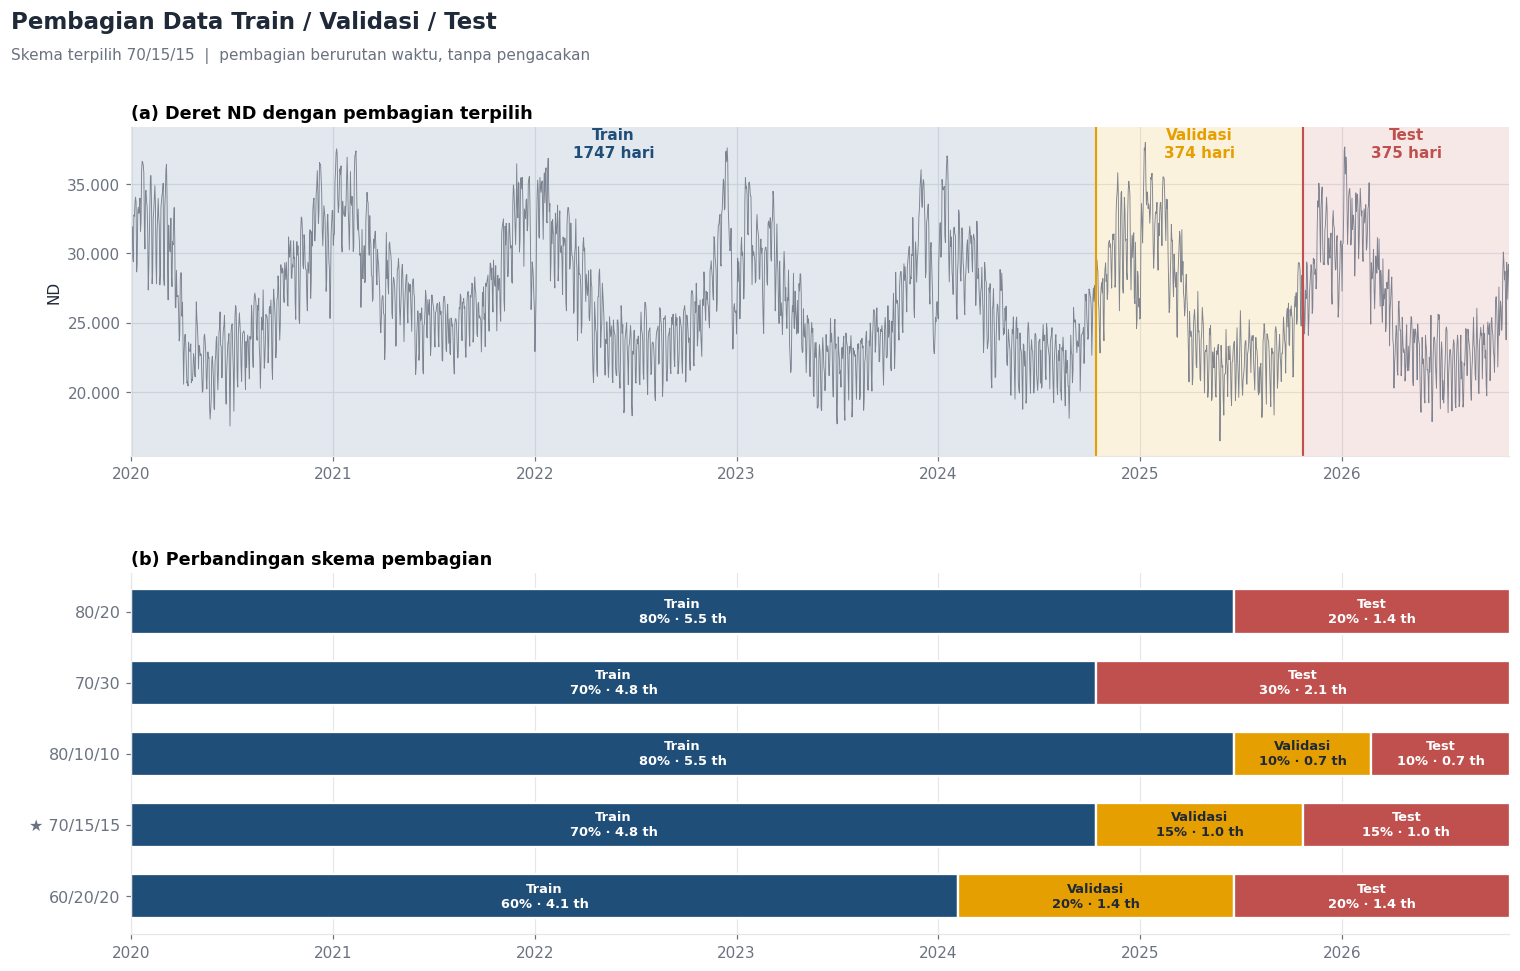

In [57]:
NAMA_PILIHAN = "/".join(str(int(round(v * 100))) for v in CFG.split if v > 0)
assert NAMA_PILIHAN in SKEMA, f"Skema {NAMA_PILIHAN} tidak ada di SKEMA; ubah CFG.split atau tambahkan skema."
seg_pilih = potong(y, CFG.split)

import matplotlib.dates as mdates

fig = plt.figure(figsize=(14, 9))
gs = GridSpec(2, 1, figure=fig, height_ratios=[1, 1.1], hspace=0.34, left=0.09, right=0.985, top=0.875, bottom=0.06)
judul_figur(fig, "Pembagian Data Train / Validasi / Test",
            f"Skema terpilih {NAMA_PILIHAN}  |  pembagian berurutan waktu, tanpa pengacakan")

# --- panel atas: deret + blok warna ---
ax1 = fig.add_subplot(gs[0])
ax1.plot(y.index, y, color=PALETTE["neutral"], lw=0.6, alpha=0.85)
for bagian, s in seg_pilih.items():
    ax1.axvspan(s.index[0], s.index[-1], color=WARNA_SEG[bagian], alpha=0.13, lw=0)
    ax1.axvline(s.index[0], color=WARNA_SEG[bagian], lw=1.4)
    ax1.text(s.index[0] + (s.index[-1] - s.index[0]) / 2, ax1.get_ylim()[1], f"{bagian}\n{len(s)} hari",
             ha="center", va="top", color=WARNA_SEG[bagian], fontsize=10, fontweight="bold")
ax1.set_title("(a) Deret ND dengan pembagian terpilih")
ax1.set_ylabel("ND")
ax1.yaxis.set_major_formatter(ribuan)
ax1.set_xlim(y.index[0], y.index[-1])

# --- panel bawah: perbandingan skema ---
ax2 = fig.add_subplot(gs[1])
nama_list = list(SKEMA)
for i, nama in enumerate(nama_list):
    for bagian, s in potong(y, SKEMA[nama]).items():
        if len(s) == 0:
            continue
        kiri = mdates.date2num(s.index[0])
        ax2.barh(i, len(s), left=kiri, height=0.62, color=WARNA_SEG[bagian], edgecolor="white", linewidth=1.5)
        ax2.text(kiri + len(s) / 2, i, f"{bagian}\n{100 * len(s) / len(y):.0f}% · {len(s) / 365.25:.1f} th",
                 ha="center", va="center", fontsize=8.5, fontweight="bold",
                 color=PALETTE["text"] if bagian == "Validasi" else "white")
ax2.set_yticks(range(len(nama_list)))
ax2.set_yticklabels([("★ " if n == NAMA_PILIHAN else "") + n for n in nama_list], fontsize=10.5)
ax2.invert_yaxis()
ax2.xaxis_date()
ax2.xaxis.set_major_locator(mdates.YearLocator())
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax2.set_xlim(mdates.date2num(y.index[0]), mdates.date2num(y.index[-1]))
ax2.grid(axis="y", visible=False)
ax2.set_title("(b) Perbandingan skema pembagian")

simpan_figur(fig, "06_skema_pembagian_data")
plt.show()

Figur disimpan: results_2020/figures/07_kesetaraan_segmen.png


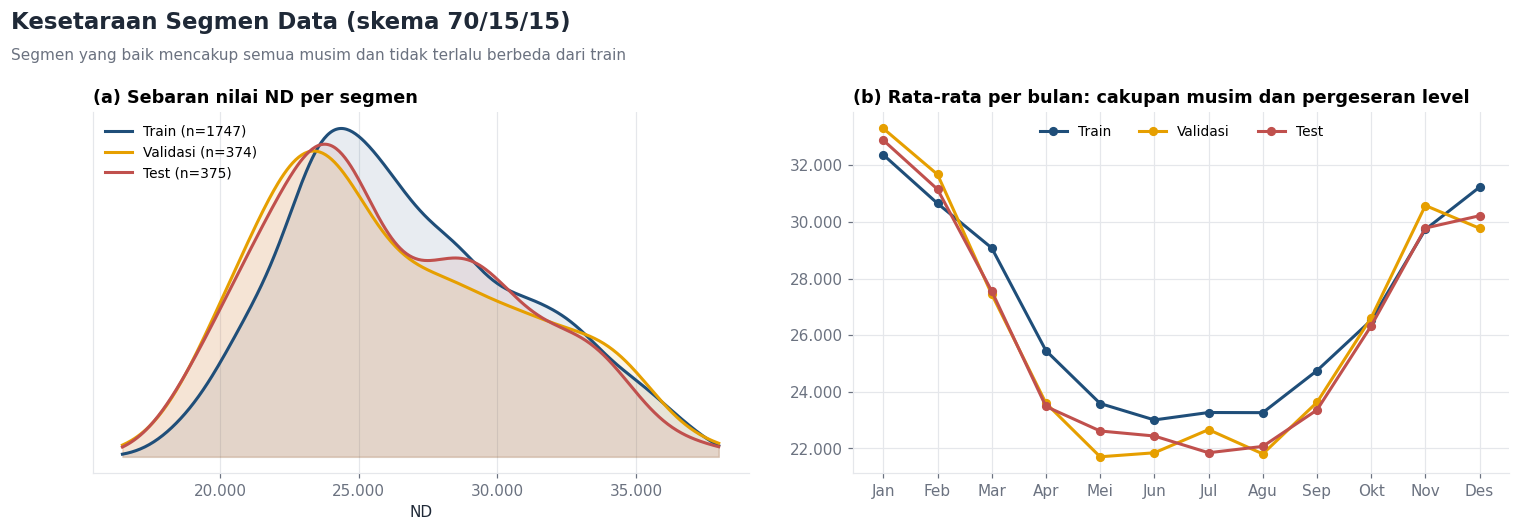

In [58]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.9))
judul_figur(fig, f"Kesetaraan Segmen Data (skema {NAMA_PILIHAN})",
            "Segmen yang baik mencakup semua musim dan tidak terlalu berbeda dari train")
fig.subplots_adjust(left=0.065, right=0.985, top=0.80, bottom=0.13, wspace=0.16)

xs = np.linspace(y.min(), y.max(), 400)
for bagian, s in seg_pilih.items():
    dens = stats.gaussian_kde(s)(xs)
    ax1.plot(xs, dens, color=WARNA_SEG[bagian], lw=2, label=f"{bagian} (n={len(s)})")
    ax1.fill_between(xs, dens, color=WARNA_SEG[bagian], alpha=0.10)
ax1.set_title("(a) Sebaran nilai ND per segmen")
ax1.set_xlabel("ND")
ax1.xaxis.set_major_formatter(ribuan)
ax1.set_yticks([])
ax1.legend(loc="upper left")

for bagian, s in seg_pilih.items():
    rata_bulan = s.groupby(s.index.month).mean().reindex(range(1, 13))
    ax2.plot(range(1, 13), rata_bulan.values, marker="o", ms=5, lw=2, color=WARNA_SEG[bagian], label=bagian)
ax2.set_xticks(range(1, 13))
ax2.set_xticklabels(BULAN)
ax2.set_title("(b) Rata-rata per bulan: cakupan musim dan pergeseran level")
ax2.yaxis.set_major_formatter(ribuan)
ax2.legend(loc="upper center", ncol=3)

simpan_figur(fig, "07_kesetaraan_segmen")
plt.show()

## 3.3 Pemilihan Skema dan Pembentukan Segmen

Skema yang dipakai ditentukan oleh `CFG.split` di sel konfigurasi (default 70 / 15 / 15). Pilih skema yang **Layak** pada tabel penilaian di atas. Jika ada beberapa yang layak, pilih yang train-nya paling panjang karena train yang lebih panjang membuat estimasi pola tahunan lebih stabil.

In [59]:
if rekomendasi is not None and rekomendasi != NAMA_PILIHAN:
    print(f"CATATAN: skema terpilih di konfigurasi ({NAMA_PILIHAN}) berbeda dari rekomendasi otomatis ({rekomendasi}). "
          "Pastikan alasan pemilihan Anda dapat dijelaskan di skripsi.")
assert CFG.split[1] > 0, "Skema harus memiliki data validasi (untuk tuning dan early stopping GRU)."
if tabel_nilai.loc[NAMA_PILIHAN, "Kelayakan"] != "Layak":
    print(f"PERINGATAN: skema {NAMA_PILIHAN} tidak memenuhi semua kriteria -> {tabel_nilai.loc[NAMA_PILIHAN, 'Catatan']}")

n_train, n_val_end = batas_split(len(y), CFG.split)
y_train = y.iloc[:n_train]
y_val = y.iloc[n_train:n_val_end]
y_test = y.iloc[n_val_end:]

hasil_split = pd.DataFrame(
    {
        "Bagian": ["Train", "Validasi", "Test", "Total"],
        "Mulai": [s.index[0].date() for s in (y_train, y_val, y_test, y)],
        "Selesai": [s.index[-1].date() for s in (y_train, y_val, y_test, y)],
        "Jumlah hari": [len(s) for s in (y_train, y_val, y_test, y)],
        "Proporsi (%)": [round(100 * len(s) / len(y), 1) for s in (y_train, y_val, y_test, y)],
        "Rata-rata ND": [round(s.mean()) for s in (y_train, y_val, y_test, y)],
        "Fungsi": ["Melatih SARIMA dan GRU", "Tuning hyperparameter, early stopping", "Evaluasi akhir", "-"],
    }
).set_index("Bagian")
display(hasil_split)
hasil_split.to_csv(Path(CFG.table_dir) / "09_pembagian_terpilih.csv")

,Mulai,Selesai,Jumlah hari,Proporsi (%),Rata-rata ND,Fungsi
Bagian,,,,,,
Train,2020-01-01,2024-10-12,1747,70.0,26776,Melatih SARIMA dan GRU
Validasi,2024-10-13,2025-10-21,374,15.0,26202,"Tuning hyperparameter, early stopping"
Test,2025-10-22,2026-10-31,375,15.0,26126,Evaluasi akhir
Total,2020-01-01,2026-10-31,2496,100.0,26593,-


## 3.4 Pemeriksaan Keabsahan dan Penyimpanan

Pemeriksaan otomatis memastikan tidak ada kebocoran: urutan waktu benar, tidak ada tumpang tindih, tidak ada tanggal yang hilang, dan test berakhir tepat di data terakhir (sehingga forecast dimulai 1 November 2026).

In [60]:
cek = [
    ("Urutan waktu: train < validasi < test", y_train.index[-1] < y_val.index[0] and y_val.index[-1] < y_test.index[0]),
    ("Tidak ada tumpang tindih tanggal", len(set(y_train.index) & set(y_val.index)) == 0
                                          and len(set(y_val.index) & set(y_test.index)) == 0
                                          and len(set(y_train.index) & set(y_test.index)) == 0),
    ("Tidak ada tanggal yang hilang antar segmen",
     (y_val.index[0] - y_train.index[-1]).days == 1 and (y_test.index[0] - y_val.index[-1]).days == 1),
    ("Jumlah segmen = total data", len(y_train) + len(y_val) + len(y_test) == len(y)),
    ("Test berakhir di data terakhir", y_test.index[-1] == y.index[-1]),
    ("Validasi dan test mencakup 12 bulan", y_val.index.month.nunique() == 12 and y_test.index.month.nunique() == 12),
    ("Train memuat >= 3 tahun", len(y_train) / 365.25 >= 3),
]
tabel_cek = pd.DataFrame([(n, "OK" if ok else "PERIKSA") for n, ok in cek], columns=["Pemeriksaan", "Status"]).set_index("Pemeriksaan")
display(tabel_cek)
assert all(ok for _, ok in cek[:5]), "Pembagian tidak valid (urutan/tumpang tindih). Periksa kembali."

for nama, s in (("train", y_train), ("validasi", y_val), ("test", y_test)):
    s.rename(CFG.target_col).to_csv(Path(CFG.processed_dir) / f"{nama}.csv", index_label=CFG.date_col)
print(f"Tersimpan di {CFG.processed_dir}/: train.csv, validasi.csv, test.csv")
print(f"\nForecast akan dimulai pada {(y.index[-1] + pd.Timedelta(days=1)).date()} ({CFG.horizon} hari).")
print("Tahap 3 selesai. Lanjut ke Tahap 4: uji stasioneritas dan penentuan d dan D (hanya data train).")

,Status
Pemeriksaan,
Urutan waktu: train < validasi < test,OK
Tidak ada tumpang tindih tanggal,OK
Tidak ada tanggal yang hilang antar segmen,OK
Jumlah segmen = total data,OK
Test berakhir di data terakhir,OK
Validasi dan test mencakup 12 bulan,OK
Train memuat >= 3 tahun,OK


Tersimpan di data_2020/processed/: train.csv, validasi.csv, test.csv

Forecast akan dimulai pada 2026-11-01 (30 hari).
Tahap 3 selesai. Lanjut ke Tahap 4: uji stasioneritas dan penentuan d dan D (hanya data train).


---

## Tahap 4 — Uji Stasioneritas dan Penentuan d dan D

Tujuan: menentukan banyaknya differencing biasa (**d**) dan musiman (**D**) untuk SARIMA. **Seluruh analisis hanya memakai data train** (`y_train`).

| Langkah | Isi |
|:--|:--|
| 4.1 | Komponen tahunan (suku Fourier) dan kekuatan musiman pada data train |
| 4.2 | Uji ADF dan KPSS untuk semua kombinasi (d, D), pada dua versi data |
| 4.3 | Aturan keputusan dan pemilihan d, D |
| 4.4 | Visualisasi transformasi dan diagnostik differencing |
| 4.5 | Pemeriksaan perlunya transformasi (log / Box-Cox) |

**Mengapa dua versi data?** Model akhir adalah SARIMAX: `ND = β·Fourier + galat SARIMA`. Suku Fourier **tidak** di-differencing, hanya galatnya. Karena itu kebutuhan differencing yang relevan dihitung pada data **setelah komponen Fourier dikeluarkan**. Versi data asli dihitung sebagai pembanding (apa yang dibutuhkan SARIMA tanpa Fourier).

**Aturan membaca uji:**

| Uji | H0 | Stasioner jika |
|:--|:--|:--|
| ADF | Ada akar unit (tidak stasioner) | p ≤ 0,05 (H0 ditolak) |
| KPSS | Deret stasioner | p ≥ 0,05 (H0 tidak ditolak) |

Dua uji dipakai bersamaan karena hipotesis nolnya berlawanan. Nilai p KPSS dibatasi pustaka pada rentang 0,01–0,10.

## 4.1 Komponen Tahunan (Fourier) dan Kekuatan Musiman pada Data Train

In [61]:
import statsmodels.api as sm
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import kpss


def fourier_terms(index, K=CFG.fourier_k, period=365.25, origin=CFG.start_date):
    """Suku Fourier tahunan. Titik asal tetap (awal data) agar tanggal masa depan konsisten."""
    t = (index - pd.Timestamp(origin)).days.values.astype(float)
    kolom = {}
    for k in range(1, K + 1):
        kolom[f"sin{k}"] = np.sin(2 * np.pi * k * t / period)
        kolom[f"cos{k}"] = np.cos(2 * np.pi * k * t / period)
    return pd.DataFrame(kolom, index=index)


F_train = fourier_terms(y_train.index)
ols = sm.OLS(y_train, sm.add_constant(F_train)).fit()
fourier_fit = ols.fittedvalues                 # komponen tahunan hasil regresi (hanya train)
y_train_adj = ols.resid.rename("ND_setelah_fourier")   # data setelah komponen Fourier dikeluarkan

print(f"Fourier K = {CFG.fourier_k} ({2 * CFG.fourier_k} variabel). "
      f"R² regresi pada train = {ols.rsquared:.3f} "
      f"-> {100 * ols.rsquared:.1f}% variasi ND dijelaskan oleh pola tahunan.")
print("(K final dipilih di Tahap 5 lewat AIC/BIC; di sini K awal hanya untuk menentukan d dan D.)\n")


def kekuatan_musiman(seri, periode):
    s = STL(seri, period=periode, robust=True).fit()
    return max(0.0, 1 - s.resid.var() / (s.resid + s.seasonal).var())


fs = pd.DataFrame(
    {"Versi data": ["Data asli (train)", "Setelah Fourier (train)"],
     "Kekuatan musiman mingguan": [kekuatan_musiman(y_train, CFG.seasonal_period),
                                   kekuatan_musiman(y_train_adj, CFG.seasonal_period)]}
).set_index("Versi data")
fs["Kekuatan musiman mingguan"] = fs["Kekuatan musiman mingguan"].round(3)
fs["Kategori (batas 0,64)"] = np.where(fs["Kekuatan musiman mingguan"] > 0.64, "Kuat", "Di bawah batas")
display(fs)
print("Kekuatan musiman hanya petunjuk awal. Keputusan D diambil dari uji pada langkah 4.2-4.3.")

Fourier K = 3 (6 variabel). R² regresi pada train = 0.641 -> 64.1% variasi ND dijelaskan oleh pola tahunan.
(K final dipilih di Tahap 5 lewat AIC/BIC; di sini K awal hanya untuk menentukan d dan D.)



,Kekuatan musiman mingguan,"Kategori (batas 0,64)"
Versi data,,
Data asli (train),0.692,Kuat
Setelah Fourier (train),0.694,Kuat


Kekuatan musiman hanya petunjuk awal. Keputusan D diambil dari uji pada langkah 4.2-4.3.


## 4.2 Uji ADF dan KPSS untuk Semua Kombinasi (d, D)

Setiap kombinasi diuji pada kedua versi data. Kolom tambahan:

- **Varians**: differencing berlebihan (*over-differencing*) menaikkan varians.
- **ACF lag-1**: nilai di bawah **−0,5** adalah tanda over-differencing (struktur MA(1) palsu).

In [62]:
M = CFG.seasonal_period


def bedakan(seri, d, D, m=M):
    z = seri.copy()
    if D:
        z = z.diff(m)          # differencing musiman (lag 7)
    for _ in range(d):
        z = z.diff()           # differencing biasa
    return z.dropna()


def uji_stasioner(seri):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")          # p-value KPSS dibatasi 0,01-0,10 (peringatan interpolasi diabaikan)
        adf_p = adfuller(seri, autolag="AIC")[1]
        kpss_p = kpss(seri, regression="c", nlags="auto")[1]
    return adf_p, kpss_p


def tabel_diff(seri, nama):
    baris = []
    for D in (0, 1):
        for d in (0, 1, 2):
            z = bedakan(seri, d, D)
            adf_p, kpss_p = uji_stasioner(z)
            acf1 = acf(z, nlags=1, fft=True)[1]
            stasioner = (adf_p <= 0.05) and (kpss_p >= 0.05)
            over = acf1 < -0.5
            keputusan = "Stasioner" if stasioner else "Belum stasioner"
            if over:
                keputusan += " | over-differencing"
            baris.append({"Versi data": nama, "d": d, "D": D, "n": len(z), "Varians": z.var(),
                          "ADF p": round(adf_p, 4), "KPSS p": round(kpss_p, 3),
                          "ACF lag-1": round(acf1, 3), "Keputusan": keputusan})
    return pd.DataFrame(baris)


tab_asli = tabel_diff(y_train, "Data asli")
tab_adj = tabel_diff(y_train_adj, "Setelah Fourier")
tab_all = pd.concat([tab_asli, tab_adj], ignore_index=True)

tampil = tab_all.copy()
tampil["Varians"] = tampil["Varians"].map(lambda v: angka(v))
display(tampil.set_index(["Versi data", "d", "D"]))
tab_all.to_csv(Path(CFG.table_dir) / "10_uji_stasioneritas_d_D.csv", index=False)

n     Varians   ADF p  KPSS p  ACF lag-1  \
Versi data      d D                                                
Data asli       0 0  1747  17.838.872  0.0071   0.031      0.891   
                1 0  1746   3.876.913  0.0000   0.100      0.077   
                2 0  1745   7.157.606  0.0000   0.100     -0.280   
                0 1  1740   5.142.437  0.0000   0.100      0.718   
                1 1  1739   2.885.545  0.0000   0.100     -0.155   
                2 1  1738   6.669.388  0.0000   0.100     -0.520   
Setelah Fourier 0 0  1747   6.403.254  0.0000   0.010      0.697   
                1 0  1746   3.873.405  0.0000   0.100      0.076   
                2 0  1745   7.157.603  0.0000   0.100     -0.280   
                0 1  1740   4.960.478  0.0000   0.100      0.708   
                1 1  1739   2.885.404  0.0000   0.100     -0.155   
                2 1  1738   6.669.389  0.0000   0.100     -0.520   

                                         Keputusan  
Versi data      d D                                 
Data asli       0 0                Belum stasioner  
                1 0                      Stasioner  
                2 0                      Stasioner  
                0 1                      Stasioner  
                1 1                      Stasioner  
                2 1  Stasioner | over-differencing  
Setelah Fourier 0 0                Belum stasioner  
                1 0                      Stasioner  
                2 0                      Stasioner  
                0 1                      Stasioner  
                1 1                      Stasioner  
                2 1  Stasioner | over-differencing

## 4.3 Aturan Keputusan dan Pemilihan d dan D

Aturan (berurutan, berhenti pada aturan pertama yang menghasilkan kandidat):

1. Kombinasi **stasioner menurut ADF dan KPSS** dan **tanpa over-differencing** (ACF lag-1 > −0,5). Dari kandidat, pilih differencing total (d + D) **paling kecil**, lalu varians terkecil.
2. Jika KPSS menolak di semua kombinasi (sering terjadi pada data panjang), pakai **ADF** saja dengan syarat tanpa over-differencing.
3. Jika tidak ada yang lolos, pilih varians terkecil tanpa over-differencing, lalu jelaskan keterbatasannya.

Prinsipnya: **differencing seminimal mungkin** agar tidak membuang informasi dan tidak menimbulkan struktur palsu.

In [63]:
def pilih_diff(tab):
    t = tab.copy()
    t["total"] = t["d"] + t["D"]
    ok_adf = t["ADF p"] <= 0.05
    ok_kpss = t["KPSS p"] >= 0.05
    ok_acf = t["ACF lag-1"] > -0.5

    kandidat = t[ok_adf & ok_kpss & ok_acf]
    aturan = "Aturan 1: stasioner menurut ADF dan KPSS, tanpa over-differencing"
    urut = ["total", "Varians"]
    if kandidat.empty:
        kandidat = t[ok_adf & ok_acf]
        aturan = "Aturan 2: stasioner menurut ADF saja (KPSS menolak), tanpa over-differencing"
    if kandidat.empty:
        kandidat = t[ok_acf]
        aturan = "Aturan 3: tidak ada kombinasi lolos uji; dipilih varians terkecil"
        urut = ["Varians"]
    return kandidat.sort_values(urut).iloc[0], aturan


pilih_asli, aturan_asli = pilih_diff(tab_asli)
pilih_adj, aturan_adj = pilih_diff(tab_adj)

ringkas_pilihan = pd.DataFrame(
    {
        "Versi data": ["Data asli (SARIMA tanpa Fourier)", "Setelah Fourier (SARIMAX, dipakai)"],
        "d": [int(pilih_asli["d"]), int(pilih_adj["d"])],
        "D": [int(pilih_asli["D"]), int(pilih_adj["D"])],
        "ADF p": [pilih_asli["ADF p"], pilih_adj["ADF p"]],
        "KPSS p": [pilih_asli["KPSS p"], pilih_adj["KPSS p"]],
        "Dasar keputusan": [aturan_asli, aturan_adj],
    }
).set_index("Versi data")
display(ringkas_pilihan)
ringkas_pilihan.to_csv(Path(CFG.table_dir) / "11_pilihan_d_D.csv")

# --- nilai yang dipakai pada Tahap 5 (ubah manual hanya jika ada alasan yang dapat dijelaskan) ---
D_MANUAL = None     # contoh: 1
d_MANUAL = None     # contoh: 0
d_SARIMA = int(pilih_adj["d"]) if d_MANUAL is None else d_MANUAL
D_SARIMA = int(pilih_adj["D"]) if D_MANUAL is None else D_MANUAL
print(f"\n>>> Dipakai pada SARIMAX: d = {d_SARIMA}, D = {D_SARIMA}, m = {M}, Fourier K awal = {CFG.fourier_k}")

# ------------------------------------------------------------------------------------------
# Uji ADF/KPSS menilai kestasioneran total, BUKAN akar unit musiman. Karena itu aturan "differencing
# seminimal mungkin" dapat mengabaikan bukti musiman. Tiga aturan lazim dipertemukan di sini, dan semua
# kandidat (d, D) yang lolos dibawa ke Tahap 5 untuk diputuskan lewat kinerja pada data VALIDASI.
# ------------------------------------------------------------------------------------------
fs_adj = float(fs.loc["Setelah Fourier (train)", "Kekuatan musiman mingguan"])
t_ = tab_adj.copy()
t_["total"] = t_["d"] + t_["D"]
lolos = t_[(t_["ADF p"] <= 0.05) & (t_["KPSS p"] >= 0.05) & (t_["ACF lag-1"] > -0.5)]

# Indikator akar unit musiman: pada data yang hanya di-differencing biasa (d = 1), ACF di lag kelipatan 7
# yang TIDAK meluruh (ACF lag 14 ~ ACF lag 7) menandakan pola mingguan masih non-stasioner -> D = 1 diperlukan.
ac_d1 = acf(bedakan(y_train_adj, 1, 0), nlags=2 * M, fft=True)
rasio_musiman = ac_d1[2 * M] / ac_d1[M] if ac_d1[M] > 0.3 else np.nan
persisten = bool(ac_d1[M] > 0.3 and rasio_musiman > 0.8)
print(f"ACF musiman pada data d=1: lag {M} = {ac_d1[M]:.3f}, lag {2 * M} = {ac_d1[2 * M]:.3f}, "
      f"rasio = {rasio_musiman:.2f} -> {'PERSISTEN (indikasi D = 1)' if persisten else 'meluruh (D = 0 masih mungkin)'}")

aturan_kandidat = {}
if len(lolos):
    aturan_kandidat["A. Parsimoni (d + D terkecil)"] = lolos.sort_values(["total", "Varians"]).iloc[0]
    aturan_kandidat["B. Varians terkecil (Box-Jenkins)"] = lolos.sort_values("Varians").iloc[0]
    if (fs_adj > 0.64 or persisten) and (lolos["D"] == 1).any():
        aturan_kandidat["C. Musiman kuat / ACF musiman persisten (D = 1)"] = lolos[lolos["D"] == 1].sort_values(["total", "Varians"]).iloc[0]
else:
    aturan_kandidat["Cadangan (pilihan 4.3)"] = pilih_adj

tabel_kandidat = pd.DataFrame(
    [{"Aturan": k, "d": int(v["d"]), "D": int(v["D"]), "Varians": angka(v["Varians"]), "ACF lag-1": v["ACF lag-1"]}
     for k, v in aturan_kandidat.items()]
).set_index("Aturan")
display(tabel_kandidat)
tabel_kandidat.to_csv(Path(CFG.table_dir) / "12_kandidat_differencing.csv")

KANDIDAT_DIFF = sorted({(int(v["d"]), int(v["D"])) for v in aturan_kandidat.values()})
print(f"Kekuatan musiman mingguan (setelah Fourier) = {fs_adj:.3f}")
print(f"Kandidat (d, D) yang dibawa ke Tahap 5: {KANDIDAT_DIFF}")

,d,D,ADF p,KPSS p,Dasar keputusan
Versi data,,,,,
Data asli (SARIMA tanpa Fourier),1,0,0.0,0.1,"Aturan 1: stasioner menurut ADF dan KPSS, tanp..."
"Setelah Fourier (SARIMAX, dipakai)",1,0,0.0,0.1,"Aturan 1: stasioner menurut ADF dan KPSS, tanp..."



>>> Dipakai pada SARIMAX: d = 1, D = 0, m = 7, Fourier K awal = 3
ACF musiman pada data d=1: lag 7 = 0.626, lag 14 = 0.642, rasio = 1.03 -> PERSISTEN (indikasi D = 1)


,d,D,Varians,ACF lag-1
Aturan,,,,
A. Parsimoni (d + D terkecil),1,0,3.873.405,0.076
B. Varians terkecil (Box-Jenkins),1,1,2.885.404,-0.155
C. Musiman kuat / ACF musiman persisten (D = 1),0,1,4.960.478,0.708


Kekuatan musiman mingguan (setelah Fourier) = 0.694
Kandidat (d, D) yang dibawa ke Tahap 5: [(0, 1), (1, 0), (1, 1)]


## 4.4 Visualisasi Transformasi dan Diagnostik Differencing

Figur disimpan: results_2020/figures/08_transformasi_stasioner.png


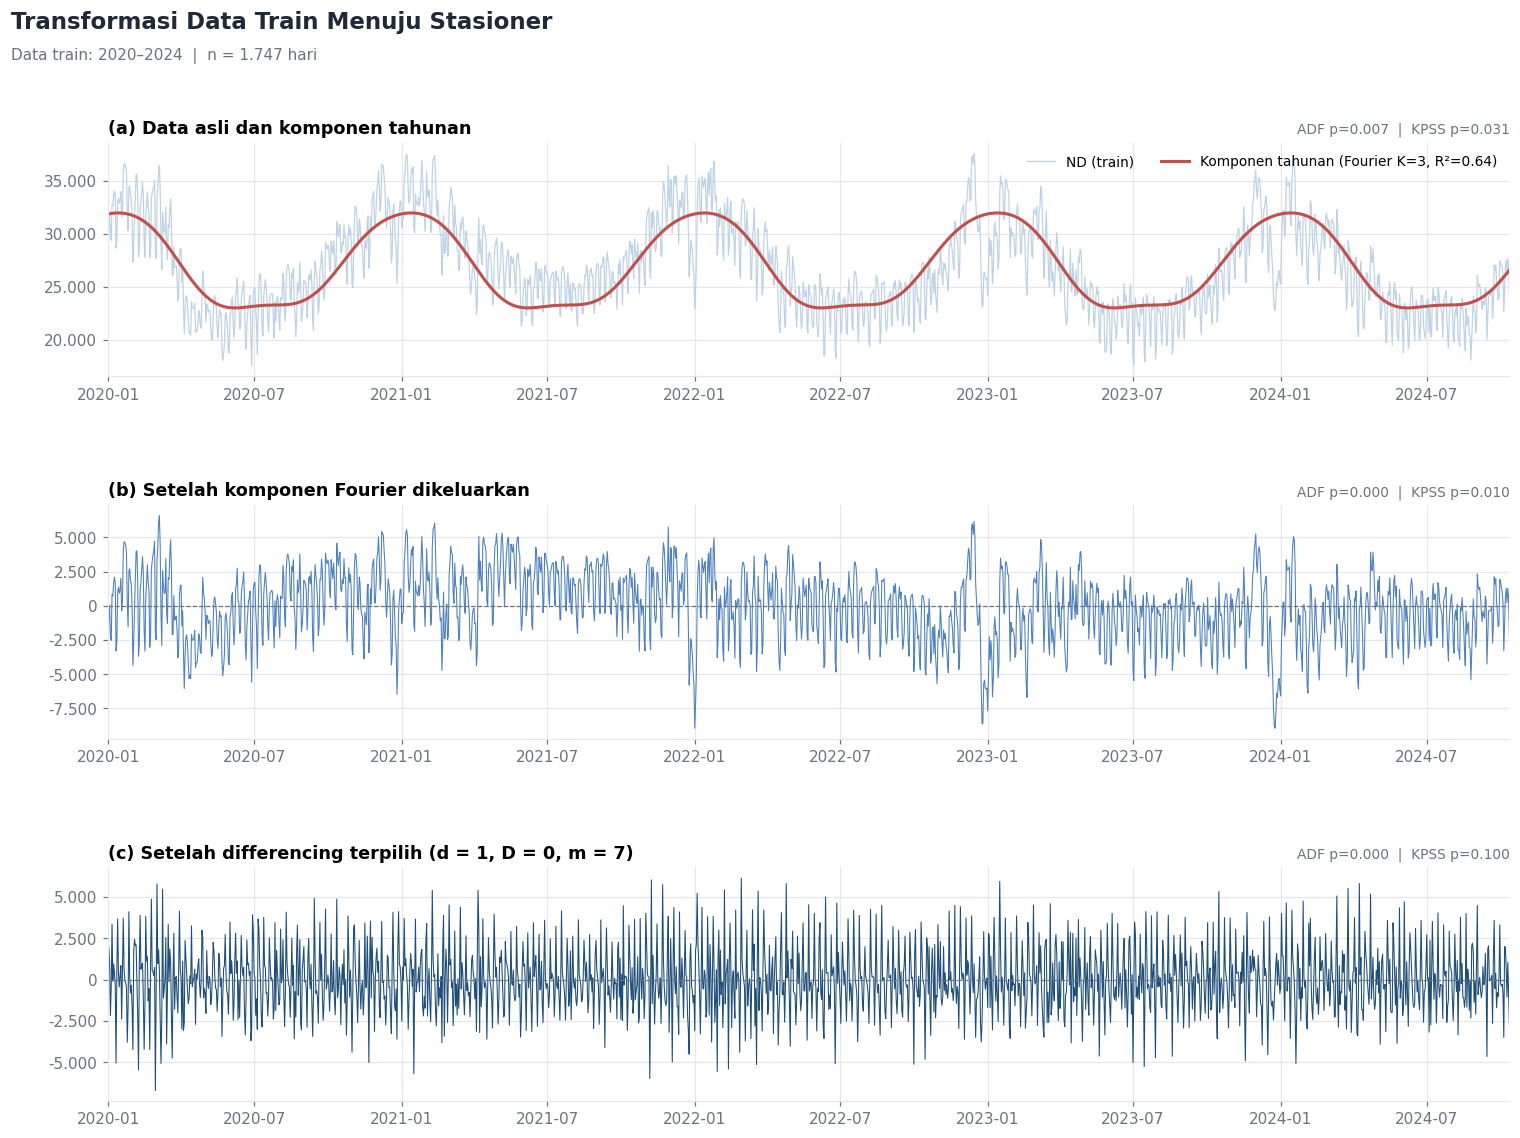

In [64]:
z_pilih = bedakan(y_train_adj, d_SARIMA, D_SARIMA)
adf_a, kpss_a = uji_stasioner(y_train)
adf_b, kpss_b = uji_stasioner(y_train_adj)
adf_c, kpss_c = uji_stasioner(z_pilih)

fig, axes = plt.subplots(3, 1, figsize=(14, 10.5), gridspec_kw={"hspace": 0.55})
judul_figur(fig, "Transformasi Data Train Menuju Stasioner",
            f"Data train: {y_train.index[0].strftime('%Y')}–{y_train.index[-1].strftime('%Y')}  |  n = {len(y_train):,} hari".replace(",", "."))
fig.subplots_adjust(left=0.075, right=0.985, top=0.88, bottom=0.05)

axes[0].plot(y_train.index, y_train, color=PALETTE["light"], lw=0.8, label="ND (train)")
axes[0].plot(fourier_fit.index, fourier_fit, color=PALETTE["accent"], lw=2, label=f"Komponen tahunan (Fourier K={CFG.fourier_k}, R²={ols.rsquared:.2f})")
axes[0].legend(loc="upper right", ncol=2)
axes[0].set_title("(a) Data asli dan komponen tahunan")
axes[0].yaxis.set_major_formatter(ribuan)
axes[0].text(1.0, 1.04, f"ADF p={adf_a:.3f}  |  KPSS p={kpss_a:.3f}", transform=axes[0].transAxes,
             ha="right", fontsize=9, color=PALETTE["neutral"])

axes[1].plot(y_train_adj.index, y_train_adj, color=PALETTE["secondary"], lw=0.7)
axes[1].axhline(0, color=PALETTE["neutral"], lw=0.8, ls="--")
axes[1].set_title("(b) Setelah komponen Fourier dikeluarkan")
axes[1].yaxis.set_major_formatter(ribuan)
axes[1].text(1.0, 1.04, f"ADF p={adf_b:.3f}  |  KPSS p={kpss_b:.3f}", transform=axes[1].transAxes,
             ha="right", fontsize=9, color=PALETTE["neutral"])

axes[2].plot(z_pilih.index, z_pilih, color=PALETTE["primary"], lw=0.7)
axes[2].axhline(0, color=PALETTE["neutral"], lw=0.8, ls="--")
axes[2].set_title(f"(c) Setelah differencing terpilih (d = {d_SARIMA}, D = {D_SARIMA}, m = {M})")
axes[2].yaxis.set_major_formatter(ribuan)
axes[2].text(1.0, 1.04, f"ADF p={adf_c:.3f}  |  KPSS p={kpss_c:.3f}", transform=axes[2].transAxes,
             ha="right", fontsize=9, color=PALETTE["neutral"])
for ax in axes:
    ax.set_xlim(y_train.index[0], y_train.index[-1])

simpan_figur(fig, "08_transformasi_stasioner")
plt.show()

Figur disimpan: results_2020/figures/09_diagnostik_differencing.png


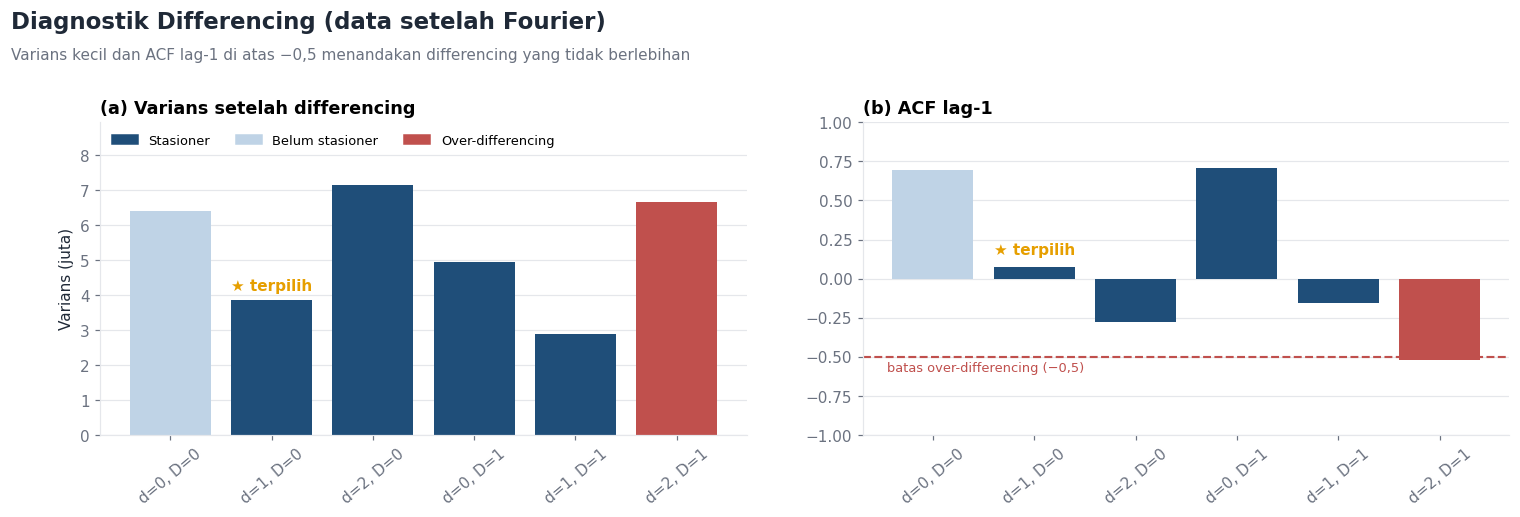

In [65]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.9))
judul_figur(fig, "Diagnostik Differencing (data setelah Fourier)",
            "Varians kecil dan ACF lag-1 di atas −0,5 menandakan differencing yang tidak berlebihan")
fig.subplots_adjust(left=0.07, right=0.985, top=0.78, bottom=0.2, wspace=0.18)

t = tab_adj.copy()
label = [f"d={r.d}, D={r.D}" for r in t.itertuples()]
warna = [PALETTE["primary"] if "Stasioner" in k and "over" not in k else
         (PALETTE["accent"] if "over" in k else PALETTE["light"]) for k in t["Keputusan"]]
terpilih = [(r.d == d_SARIMA) and (r.D == D_SARIMA) for r in t.itertuples()]

ax1.bar(label, t["Varians"] / 1e6, color=warna)
ax1.set_title("(a) Varians setelah differencing")
ax1.set_ylabel("Varians (juta)")
ax1.set_ylim(0, (t["Varians"] / 1e6).max() * 1.25)
for i, (v, sel) in enumerate(zip(t["Varians"] / 1e6, terpilih)):
    if sel:
        ax1.annotate("★ terpilih", (i, v), xytext=(0, 6), textcoords="offset points", ha="center",
                     color=PALETTE["warning"], fontsize=10, fontweight="bold")
ax1.tick_params(axis="x", rotation=40)
ax1.grid(axis="x", visible=False)

ax2.bar(label, t["ACF lag-1"], color=warna)
ax2.axhline(-0.5, color=PALETTE["accent"], ls="--", lw=1.4)
ax2.text(-0.45, -0.53, "batas over-differencing (−0,5)", color=PALETTE["accent"], fontsize=8.5, va="top", ha="left")
for i, (v, sel) in enumerate(zip(t["ACF lag-1"], terpilih)):
    if sel:
        ax2.annotate("★ terpilih", (i, v), xytext=(0, 8 if v >= 0 else -16), textcoords="offset points",
                     ha="center", color=PALETTE["warning"], fontsize=10, fontweight="bold")
ax2.set_title("(b) ACF lag-1")
ax2.set_ylim(-1, 1)
ax2.tick_params(axis="x", rotation=40)
ax2.grid(axis="x", visible=False)

from matplotlib.patches import Patch
ax1.legend(handles=[Patch(color=PALETTE["primary"], label="Stasioner"),
                    Patch(color=PALETTE["light"], label="Belum stasioner"),
                    Patch(color=PALETTE["accent"], label="Over-differencing")],
           loc="upper left", fontsize=8.5, ncol=3)
simpan_figur(fig, "09_diagnostik_differencing")
plt.show()

## 4.5 Perlukah Transformasi (log / Box-Cox)?

Transformasi diperlukan bila **varians membesar seiring naiknya level** (heteroskedastisitas multiplikatif). Pemeriksaan: korelasi antara rata-rata bulanan dan simpangan baku bulanan pada data train. Bila |r| < 0,5 dan tidak signifikan, tidak ada bukti hubungan level–varians sehingga data **tidak ditransformasi** (lebih sederhana dan hasil tetap dalam satuan asli).

Korelasi rata-rata bulanan vs simpangan baku bulanan: r = 0.664 (p = 0.0000), n = 58 bulan
Figur disimpan: results_2020/figures/10_level_vs_varians.png


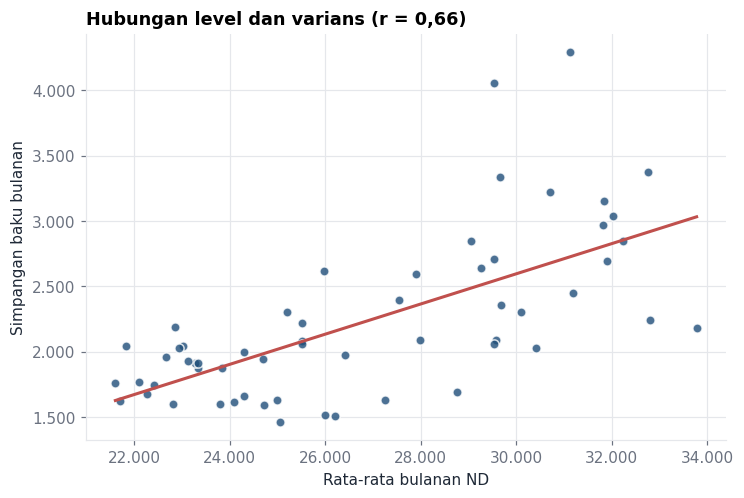

Keputusan: pertimbangkan transformasi log atau Box-Cox, lalu bandingkan hasil di Tahap 5.

RINGKASAN TAHAP 4  ->  SARIMAX (p,1,q)(P,0,Q,7) + Fourier K=3
Tahap 4 selesai. Lanjut ke Tahap 5: identifikasi (ACF/PACF) dan seleksi orde SARIMA pada data train.


In [66]:
agregat = y_train.groupby([y_train.index.year, y_train.index.month]).agg(["mean", "std"])
r_ls, p_ls = stats.pearsonr(agregat["mean"], agregat["std"])
print(f"Korelasi rata-rata bulanan vs simpangan baku bulanan: r = {r_ls:.3f} (p = {p_ls:.4f}), n = {len(agregat)} bulan")

fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.scatter(agregat["mean"], agregat["std"], s=36, color=PALETTE["primary"], alpha=0.8, edgecolor="white")
koef = np.polyfit(agregat["mean"], agregat["std"], 1)
xs = np.linspace(agregat["mean"].min(), agregat["mean"].max(), 50)
ax.plot(xs, np.polyval(koef, xs), color=PALETTE["accent"], lw=2)
ax.set_xlabel("Rata-rata bulanan ND")
ax.set_ylabel("Simpangan baku bulanan")
ax.xaxis.set_major_formatter(ribuan)
ax.yaxis.set_major_formatter(ribuan)
ax.set_title(f"Hubungan level dan varians (r = {angka(r_ls, 2)})")
simpan_figur(fig, "10_level_vs_varians")
plt.show()

if abs(r_ls) < 0.5 or p_ls > 0.05:
    print("Keputusan: TIDAK perlu transformasi (tidak ada hubungan level-varians yang kuat).")
    TRANSFORMASI = None
else:
    print("Keputusan: pertimbangkan transformasi log atau Box-Cox, lalu bandingkan hasil di Tahap 5.")
    TRANSFORMASI = "log"

print("\n" + "=" * 70)
print(f"RINGKASAN TAHAP 4  ->  SARIMAX (p,{d_SARIMA},q)(P,{D_SARIMA},Q,{M}) + Fourier K={CFG.fourier_k}")
print("=" * 70)
print("Tahap 4 selesai. Lanjut ke Tahap 5: identifikasi (ACF/PACF) dan seleksi orde SARIMA pada data train.")

---

## Tahap 5 — Identifikasi dan Seleksi Model SARIMAX

Tujuan: memilih spesifikasi SARIMAX terbaik **hanya dari data train dan validasi**. Data test **tidak disentuh**.

Spesifikasi umum: `ND (atau log ND) = β·Fourier(K) [+ β·kalender] [+ β·dummy hari] + galat SARIMA(p,d,q)(P,D,Q)₇`

| Langkah | Keputusan yang diambil | Kriteria |
|:--|:--|:--|
| 5.1 | Gambaran awal orde dari ACF/PACF | Visual |
| 5.2 | Penanganan pola mingguan (differencing musiman atau dummy hari), d, D, kalender, transformasi | **RMSE forecast 30 hari** pada validasi |
| 5.3 | Jumlah harmonik Fourier K | **RMSE forecast 30 hari** pada validasi |
| 5.4 | Orde p, q, P, Q | AIC dengan aturan parsimoni |
| 5.5 | Diagnostik residual dan uji nonlinearitas (BDS) | Ljung–Box, Jarque–Bera, ARCH, BDS |
| 5.6 | Koefisien dan kinerja pada train dan validasi | RMSE, MAE, MAPE, sMAPE |

**Komponen deterministik (regresor eksogen):**

| Regresor | Isi | Alasan |
|:--|:--|:--|
| **Fourier (K harmonik)** | sin dan cos periode 365,25 hari | Pola tahunan |
| **Kalender** | hari libur resmi (England & Wales), periode Natal–Tahun Baru (24 Des–2 Jan), periode lockdown COVID-19 (23 Mar–30 Jun 2020) | Hari libur menurunkan permintaan secara tajam dan berulang setiap tahun; tanpa ini kejadian tersebut menjadi autokorelasi di residual |
| **Dummy hari** (opsional) | 6 variabel Senin–Minggu | Pola mingguan yang stabil lebih tepat dimodelkan sebagai dummy daripada differencing musiman, yang dapat menjadi *over-differencing* (tanda: MA musiman ≈ −1) |

**Dua kriteria, dua jenis keputusan:**

- Keputusan **struktural** (d, D, dummy hari, kalender, transformasi, K) memakai *RMSE forecast 30 hari bergulir* pada data validasi, sesuai tujuan penelitian (forecast November). Ukuran satu langkah tidak cukup karena model dengan komponen level yang bebas bergeser tampak bagus satu langkah ke depan, tetapi belum tentu membawa pola tahunan dan mingguan ke depan.
- Keputusan **halus** (orde p, q, P, Q) memakai **AIC**, yang sebanding karena data dan struktur sudah sama.

> Pelaporan akhir tetap **one-step-ahead** (train, validasi, test). Forecast 30 hari bergulir pada validasi hanya dipakai untuk memilih struktur model.

In [67]:
import importlib.util
import itertools
import json
import subprocess
import sys
import time

if importlib.util.find_spec("holidays") is None:          # pustaka hari libur (otomatis dipasang di Colab)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "holidays"])
import holidays
import statsmodels.api as sm
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.stattools import bds
from statsmodels.tsa.statespace.sarimax import SARIMAX

assert "KANDIDAT_DIFF" in globals(), "Jalankan ulang Tahap 4 (sel 4.3 versi terbaru) terlebih dahulu."
TRANSFORMASI = globals().get("TRANSFORMASI")      # "log" atau None (dari Tahap 4.5)
BURN = 30                                          # residual awal dibuang (inisialisasi state-space)
H = CFG.horizon                                    # 30 hari

# ------------------------------- regresor eksogen -------------------------------
_libur = holidays.country_holidays(CFG.negara_libur, subdiv=CFG.wilayah_libur, years=range(2019, 2031))
TGL_LIBUR = {pd.Timestamp(d) for d in _libur}


def kalender_terms(index):
    libur = np.array([d in TGL_LIBUR for d in index], dtype=float)
    natal = np.array([(((d.month == 12 and d.day >= 24) or (d.month == 1 and d.day <= 2)) and d not in TGL_LIBUR)
                      for d in index], dtype=float)
    return pd.DataFrame({"libur": libur, "natal": natal}, index=index)


def covid_terms(index):
    aktif = (index >= "2020-03-23") & (index <= "2020-06-30")     # lockdown pertama Inggris
    return pd.DataFrame({"covid": aktif.astype(float)}, index=index)


def hari_terms(index):
    return pd.DataFrame({f"hari{k}": (index.dayofweek == k).astype(float) for k in range(1, 7)}, index=index)


def regresor(index, K, dow=False, kal=True):
    bagian = [fourier_terms(index, K)]
    if kal:
        bagian += [kalender_terms(index), covid_terms(index)]
    if dow:
        bagian.append(hari_terms(index))
    return pd.concat(bagian, axis=1)


# --------------------------------- utilitas model ---------------------------------
def ukuran(aktual, prediksi):
    a, f = np.asarray(aktual, float), np.asarray(prediksi, float)
    return {
        "RMSE": float(np.sqrt(np.mean((a - f) ** 2))),
        "MAE": float(np.mean(np.abs(a - f))),
        "MAPE": float(np.mean(np.abs((a - f) / a)) * 100),
        "sMAPE": float(np.mean(2 * np.abs(a - f) / (np.abs(a) + np.abs(f))) * 100),
    }


def ke_skala(seri, mode):                 # data asli -> skala pemodelan
    return np.log(seri) if mode == "log" else seri


def ke_asli(seri, mode):                  # skala pemodelan -> satuan ND asli
    return np.exp(seri) if mode == "log" else seri


def deskripsi(spek):
    teks = f"SARIMAX{tuple(spek['order'])}x{tuple(spek['sorder'])} + Fourier K={spek['K']}"
    if spek["kal"]:
        teks += " + kalender"
    if spek["dow"]:
        teks += " + dummy hari"
    return teks + f", transformasi {spek['mode']}"


def fit_sarimax(spek):
    """Fit SARIMAX hanya pada data TRAIN. `spek`: mode, K, order, sorder, dow, kal."""
    trend = "c" if (spek["order"][1] == 0 and spek["sorder"][1] == 0) else None
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        model = SARIMAX(ke_skala(y_train, spek["mode"]),
                        exog=regresor(y_train.index, spek["K"], spek["dow"], spek["kal"]),
                        order=spek["order"], seasonal_order=spek["sorder"], trend=trend,
                        enforce_stationarity=False, enforce_invertibility=False)
        return model.fit(disp=False, maxiter=300)


def prediksi_satu_langkah(res, spek, sampai):
    """Parameter dikunci dari train; prediksi one-step-ahead sampai indeks `sampai` (validasi; test tidak dipakai)."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        res_apply = res.apply(ke_skala(y.iloc[:sampai], spek["mode"]),
                              exog=regresor(y.index[:sampai], spek["K"], spek["dow"], spek["kal"]), refit=False)
    return res_apply, ke_asli(res_apply.fittedvalues, spek["mode"])


def skor_validasi(res, spek):
    _, pred = prediksi_satu_langkah(res, spek, n_val_end)
    return ukuran(y_val, pred.iloc[n_train:n_val_end])


def forecast_bergulir(res, spek):
    """Forecast 30 hari dari beberapa titik asal DI DALAM validasi (asal bergeser tiap 30 hari).
    Parameter dikunci dari train; setiap asal hanya memakai data sampai asal tersebut."""
    y_t = ke_skala(y.iloc[:n_val_end], spek["mode"])
    X = regresor(y.index[:n_val_end], spek["K"], spek["dow"], spek["kal"])
    aktual_semua, ramal_semua, jendela = [], [], []
    for t in range(n_train, n_val_end - H + 1, H):
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            r = res.apply(y_t.iloc[:t], exog=X.iloc[:t], refit=False)
            fc = r.forecast(H, exog=X.iloc[t:t + H])
        fc_asli = ke_asli(pd.Series(np.asarray(fc), index=y.index[t:t + H]), spek["mode"])
        aktual = y.iloc[t:t + H]
        aktual_semua.append(aktual.values)
        ramal_semua.append(fc_asli.values)
        jendela.append((aktual, fc_asli))
    u = ukuran(np.concatenate(aktual_semua), np.concatenate(ramal_semua))
    u["n_jendela"] = len(jendela)
    return u, jendela


def akar_minimum(res):
    akar = np.concatenate([np.abs(res.arroots), np.abs(res.maroots)])
    return float(akar.min()) if len(akar) else np.inf


print(f"Hari libur {CFG.negara_libur}/{CFG.wilayah_libur} dalam data: "
      f"{sum(1 for d in y.index if d in TGL_LIBUR)} hari | pustaka holidays {holidays.__version__}")
print(f"Data train: {len(y_train)} hari | validasi: {len(y_val)} hari | test: TIDAK dipakai pada tahap ini")
print(f"Forecast bergulir: {(len(y_val) - H) // H + 1} jendela x {H} hari di dalam data validasi")

Hari libur UK/ENG dalam data: 63 hari | pustaka holidays 0.108
Data train: 1747 hari | validasi: 374 hari | test: TIDAK dipakai pada tahap ini
Forecast bergulir: 12 jendela x 30 hari di dalam data validasi


## 5.1 Gambaran Awal Orde dari ACF dan PACF

ACF/PACF dihitung pada data train yang sudah dikeluarkan komponen deterministiknya lalu di-differencing. Baris terakhir menunjukkan data **setelah dummy hari, kalender, dan Fourier dikeluarkan** (kemudian d = 1). Pola yang dicari:

- **PACF terputus** setelah lag *p* dan ACF menurun → indikasi AR(p).
- **ACF terputus** setelah lag *q* dan PACF menurun → indikasi MA(q).
- Lonjakan pada **lag 7, 14, 21** (titik merah) → orde musiman P dan Q.
- **ACF di lag kelipatan 7 yang tidak meluruh** (tetap tinggi sampai lag 42) → pola mingguan masih belum tertangani.

Pembacaan visual hanya memberi **titik awal**. Orde final dipilih lewat AIC pada langkah 5.4.

Figur disimpan: results_2020/figures/11_acf_pacf_kandidat.png


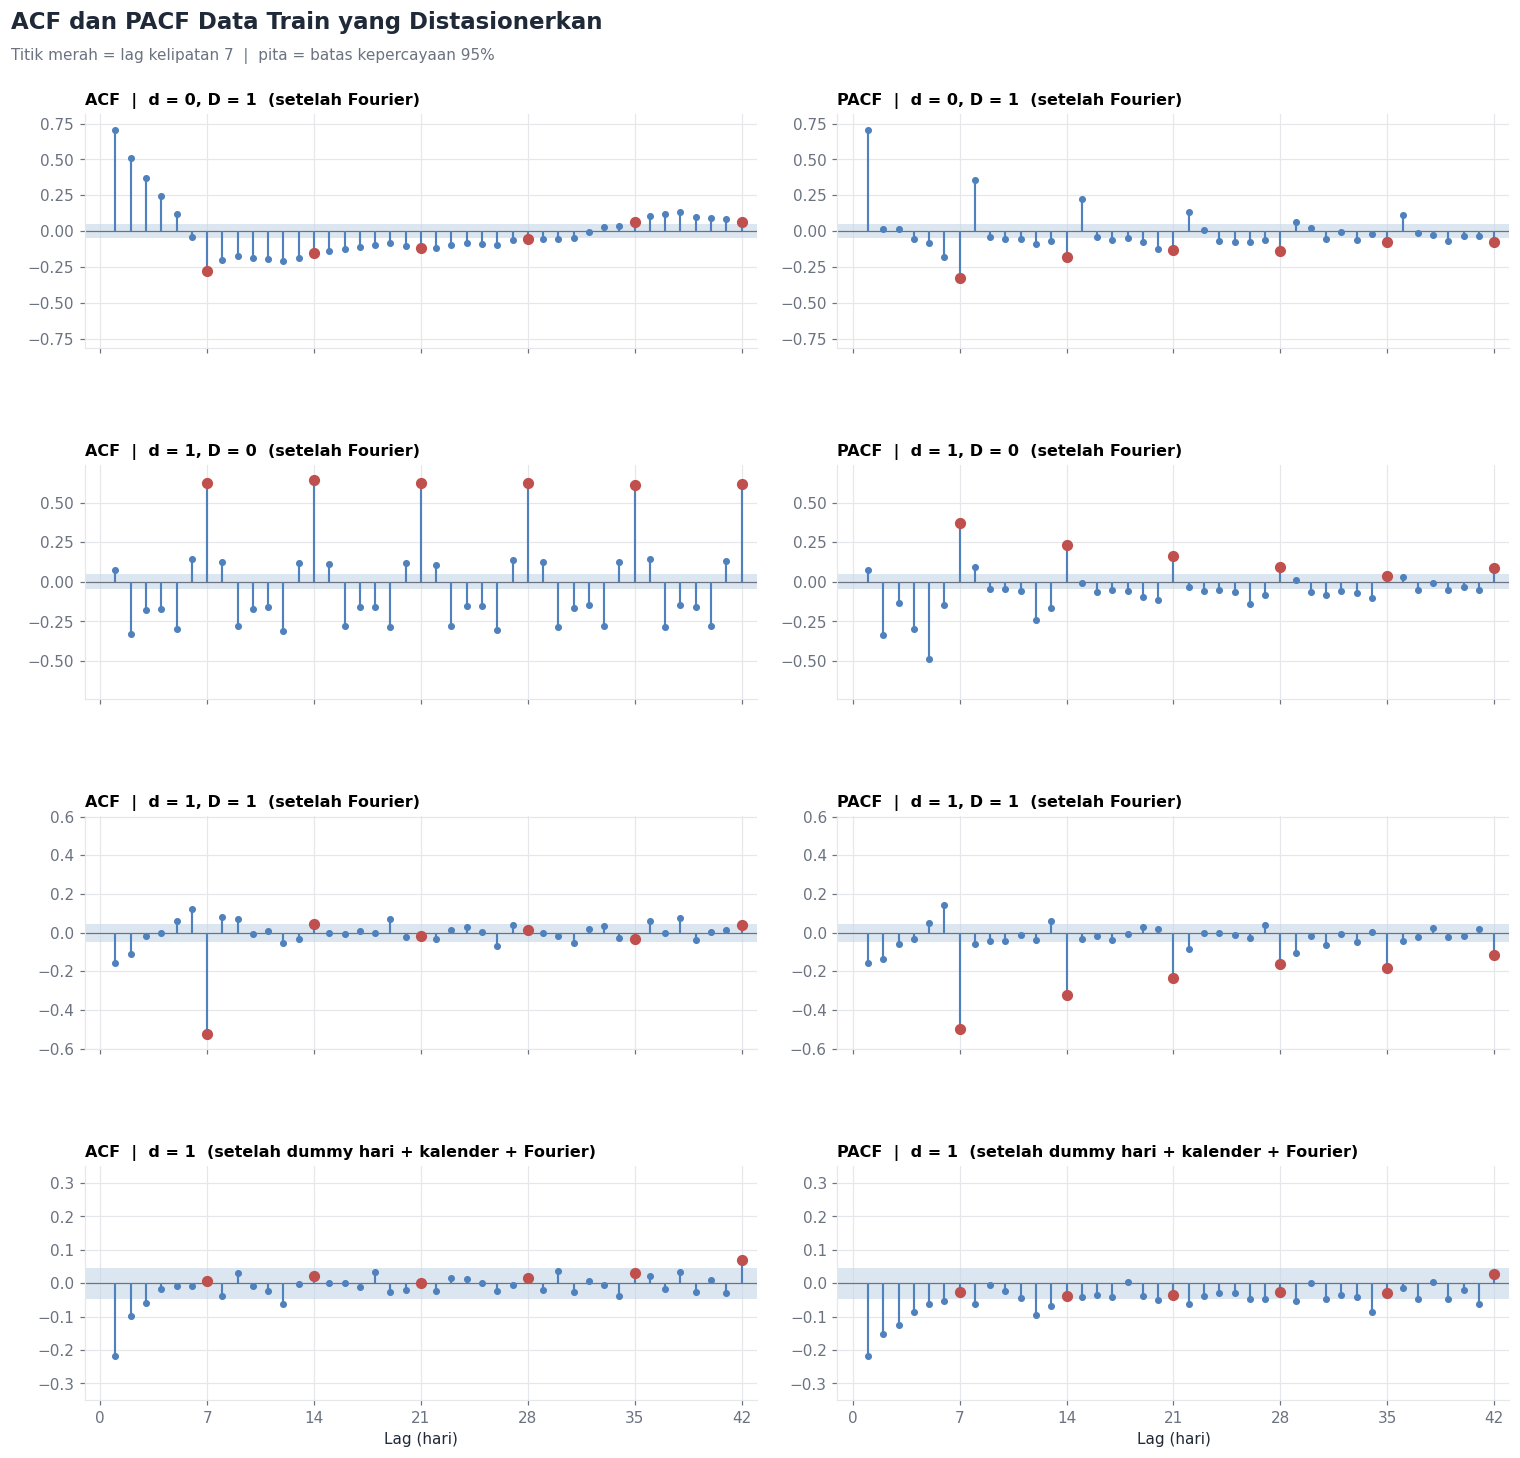

In [68]:
def stem_acf(ax, nilai, judul, ci, batas_y):
    lags = np.arange(len(nilai))
    musiman = (lags % M == 0) & (lags > 0)
    ax.axhspan(-ci, ci, color=PALETTE["light"], alpha=0.55, lw=0)
    ax.axhline(0, color=PALETTE["neutral"], lw=0.8)
    ax.vlines(lags[1:], 0, nilai[1:], color=PALETTE["secondary"], lw=1.4)
    ax.scatter(lags[1:][~musiman[1:]], nilai[1:][~musiman[1:]], s=13, color=PALETTE["secondary"], zorder=3)
    ax.scatter(lags[musiman], nilai[musiman], s=40, color=PALETTE["accent"], zorder=4)
    ax.set_xticks(np.arange(0, len(nilai), M))
    ax.set_xlim(-1, len(nilai))
    ax.set_ylim(-batas_y, batas_y)
    ax.set_title(judul, fontsize=10.5)


KANDIDAT_DD = sorted(set(KANDIDAT_DIFF) | {(1, 0), (0, 1), (1, 1)})
seri_acf = [(f"d = {d_k}, D = {D_k}  (setelah Fourier)", bedakan(y_train_adj, d_k, D_k)) for d_k, D_k in KANDIDAT_DD]
resid_penuh = sm.OLS(y_train, sm.add_constant(regresor(y_train.index, CFG.fourier_k, dow=True, kal=True))).fit().resid
seri_acf.append(("d = 1  (setelah dummy hari + kalender + Fourier)", resid_penuh.diff().dropna()))

NLAG_ID = 42
n_kand = len(seri_acf)
fig, axes = plt.subplots(n_kand, 2, figsize=(14, 3.1 * n_kand + 1.1), sharex=True, squeeze=False)
judul_figur(fig, "ACF dan PACF Data Train yang Distasionerkan",
            "Titik merah = lag kelipatan 7  |  pita = batas kepercayaan 95%")
fig.subplots_adjust(left=0.06, right=0.985, top=1 - 1.0 / fig.get_figheight(), bottom=0.06, hspace=0.5, wspace=0.12)
for baris, (nama_k, z_k) in enumerate(seri_acf):
    ci_k = 1.96 / np.sqrt(len(z_k))
    ac_k = acf(z_k, nlags=NLAG_ID, fft=True)
    pc_k = pacf(z_k, nlags=NLAG_ID, method="ywm")
    batas_y = min(1.05, max(0.35, 1.15 * max(np.abs(ac_k[1:]).max(), np.abs(pc_k[1:]).max())))
    stem_acf(axes[baris, 0], ac_k, f"ACF  |  {nama_k}", ci_k, batas_y)
    stem_acf(axes[baris, 1], pc_k, f"PACF  |  {nama_k}", ci_k, batas_y)
for ax in axes[-1]:
    ax.set_xlabel("Lag (hari)")
simpan_figur(fig, "11_acf_pacf_kandidat")
plt.show()

## 5.2 Memilih Struktur Model: Pola Mingguan, (d, D), Kalender, dan Transformasi

Setiap kandidat diuji dengan **orde dasar yang sama** dan Fourier K awal. Model dilatih pada train, lalu dinilai pada validasi dengan **forecast 30 hari bergulir** (asal bergeser tiap 30 hari, satuan ND asli).

| Singkatan | Arti |
|:--|:--|
| d, D | differencing biasa dan musiman (lag 7) |
| **+H** | memakai dummy hari (pola mingguan sebagai regresor, bukan differencing musiman) |
| **−K** | tanpa regresor kalender (hanya sebagai **pembanding** untuk membuktikan manfaat kalender; tidak ikut dipilih) |

Aturan pemilihan:

1. Keluarkan model dengan **akar AR/MA ≤ 1,01** (hampir tidak stasioner/invertibel).
2. Dari sisanya, pilih **RMSE forecast 30 hari** terkecil (hanya model yang memakai kalender).

In [69]:
modes = ["asli"] + (["log"] if TRANSFORMASI == "log" else [])
KANDIDAT_MODEL = [dict(d=d_k, D=D_k, dow=False, kal=True) for d_k, D_k in KANDIDAT_DD]
KANDIDAT_MODEL += [dict(d=1, D=0, dow=True, kal=True),       # d=1 + dummy hari
                   dict(d=1, D=0, dow=True, kal=False),      # pembanding: tanpa kalender
                   dict(d=0, D=1, dow=False, kal=False)]     # pembanding: SARIMA murni (tanpa kalender)


def label_kandidat(k):
    return f"d={k['d']}, D={k['D']}" + (" +H" if k["dow"] else "") + ("" if k["kal"] else " −K")


def spek_dasar(k, mode, K):
    sorder = (0, 0, 0, M) if k["dow"] else (1, k["D"], 1, M)    # dengan dummy hari, musiman ARMA tidak diperlukan
    return dict(mode=mode, K=K, order=(1, k["d"], 1), sorder=sorder, dow=k["dow"], kal=k["kal"])


hasil_A = []
total = len(KANDIDAT_MODEL) * len(modes)
no = 0
for k in KANDIDAT_MODEL:
    for mode_k in modes:
        no += 1
        sp = spek_dasar(k, mode_k, CFG.fourier_k)
        t0 = time.time()
        res_k = fit_sarimax(sp)
        u1 = skor_validasi(res_k, sp)
        u30, _ = forecast_bergulir(res_k, sp)
        am = akar_minimum(res_k)
        hasil_A.append({"Model": label_kandidat(k), "d": k["d"], "D": k["D"], "Dummy hari": k["dow"], "Kalender": k["kal"],
                        "Transformasi": mode_k, "AIC": res_k.aic, "BIC": res_k.bic,
                        "RMSE 1 langkah": u1["RMSE"], "RMSE 30 hari": u30["RMSE"], "MAPE 30 hari (%)": u30["MAPE"],
                        "Akar minimum": am, "Akar aman": am > 1.01})
        print(f"[{no}/{total}] {label_kandidat(k):22s} {mode_k:5s} -> RMSE 1 langkah = {u1['RMSE']:,.0f} | "
              f"RMSE 30 hari = {u30['RMSE']:,.0f}  ({time.time() - t0:.1f} dtk)".replace(",", "."))

tabel_A = pd.DataFrame(hasil_A).sort_values("RMSE 30 hari").reset_index(drop=True)
display(tabel_A.drop(columns=["d", "D", "Dummy hari", "Kalender"]).round(
    {"AIC": 1, "BIC": 1, "RMSE 1 langkah": 1, "RMSE 30 hari": 1, "MAPE 30 hari (%)": 3, "Akar minimum": 4}).set_index("Model"))
tabel_A.to_csv(Path(CFG.table_dir) / "13_seleksi_struktur_model.csv", index=False)

pilihan = tabel_A[tabel_A["Kalender"]]                   # model pembanding (tanpa kalender) tidak ikut dipilih
kandidat_A = pilihan[pilihan["Akar aman"]] if pilihan["Akar aman"].any() else pilihan
if not pilihan["Akar aman"].any():
    print("PERINGATAN: semua model berakar tidak aman; seleksi memakai seluruh model. Tinjau ulang kandidat.")
elif len(kandidat_A) < len(pilihan):
    print(f"{len(pilihan) - len(kandidat_A)} model dikeluarkan karena akar AR/MA <= 1,01 (hampir tidak stasioner/invertibel).")

terbaik_A = kandidat_A.sort_values("RMSE 30 hari").iloc[0]
d_PILIH, D_PILIH = int(terbaik_A["d"]), int(terbaik_A["D"])
DOW_PILIH, KAL_PILIH, MODE_PILIH = bool(terbaik_A["Dummy hari"]), bool(terbaik_A["Kalender"]), terbaik_A["Transformasi"]
print(f"\n>>> Terpilih: {terbaik_A['Model']}, transformasi = {MODE_PILIH} "
      f"(RMSE 30 hari = {terbaik_A['RMSE 30 hari']:,.0f})".replace(",", "."))

# bukti manfaat kalender (ablasi) pada struktur yang sama
pembanding = tabel_A[(tabel_A["d"] == d_PILIH) & (tabel_A["D"] == D_PILIH) & (tabel_A["Dummy hari"] == DOW_PILIH)
                     & (~tabel_A["Kalender"]) & (tabel_A["Transformasi"] == MODE_PILIH)]
if len(pembanding):
    r0, r1 = float(pembanding.iloc[0]["RMSE 30 hari"]), float(terbaik_A["RMSE 30 hari"])
    print(f"Ablasi kalender: RMSE 30 hari tanpa kalender = {r0:,.0f} -> dengan kalender = {r1:,.0f} "
          f"({100 * (r0 - r1) / r0:+.1f}% perbaikan)".replace(",", "."))
print("Catatan: AIC/BIC pada tabel hanya informasi dan tidak sebanding antar baris.")

[1/12] d=0. D=1               asli  -> RMSE 1 langkah = 1.236 | RMSE 30 hari = 1.749  (11.5 dtk)
[2/12] d=0. D=1               log   -> RMSE 1 langkah = 1.204 | RMSE 30 hari = 1.801  (17.7 dtk)
[3/12] d=1. D=0               asli  -> RMSE 1 langkah = 1.203 | RMSE 30 hari = 1.868  (18.5 dtk)
[4/12] d=1. D=0               log   -> RMSE 1 langkah = 1.200 | RMSE 30 hari = 1.805  (28.0 dtk)
[5/12] d=1. D=1               asli  -> RMSE 1 langkah = 1.195 | RMSE 30 hari = 1.938  (20.4 dtk)
[6/12] d=1. D=1               log   -> RMSE 1 langkah = 1.194 | RMSE 30 hari = 1.794  (23.0 dtk)
[7/12] d=1. D=0 +H            asli  -> RMSE 1 langkah = 1.187 | RMSE 30 hari = 1.797  (2.9 dtk)
[8/12] d=1. D=0 +H            log   -> RMSE 1 langkah = 1.199 | RMSE 30 hari = 1.795  (9.8 dtk)
[9/12] d=1. D=0 +H −K         asli  -> RMSE 1 langkah = 1.245 | RMSE 30 hari = 1.931  (2.7 dtk)
[10/12] d=1. D=0 +H −K         log   -> RMSE 1 langkah = 1.251 | RMSE 30 hari = 1.893  (6.5 dtk)
[11/12] d=0. D=1 −K            as

,Transformasi,AIC,BIC,RMSE 1 langkah,RMSE 30 hari,MAPE 30 hari (%),Akar minimum,Akar aman
Model,,,,,,,,
"d=0, D=1",asli,29282.7,29359.1,1236.3,1749.5,5.375,0.9941,False
"d=1, D=1",log,-6110.6,-6034.2,1193.9,1793.6,5.361,0.9899,False
"d=1, D=0 +H",log,-6201.1,-6102.8,1199.1,1795.2,5.368,1.0108,True
"d=1, D=0 +H",asli,29331.2,29429.6,1186.8,1796.7,5.290,0.9899,False
"d=0, D=1",log,-6117.8,-6041.4,1203.9,1800.8,5.420,1.0060,False
"d=1, D=0",log,-6134.9,-6058.5,1200.0,1804.6,5.387,0.9897,False
"d=1, D=0",asli,29398.8,29475.2,1202.9,1868.1,5.240,0.9972,False
"d=0, D=1 −K",log,-5852.7,-5792.7,1262.0,1886.7,5.435,1.0047,False
"d=1, D=0 +H −K",log,-5932.9,-5851.0,1250.5,1893.2,5.348,1.0145,True


7 model dikeluarkan karena akar AR/MA <= 1,01 (hampir tidak stasioner/invertibel).

>>> Terpilih: d=1. D=0 +H. transformasi = log (RMSE 30 hari = 1.795)
Ablasi kalender: RMSE 30 hari tanpa kalender = 1.893 -> dengan kalender = 1.795 (+5.2% perbaikan)
Catatan: AIC/BIC pada tabel hanya informasi dan tidak sebanding antar baris.


## 5.3 Memilih Jumlah Harmonik Fourier (K)

Dengan struktur model sudah tetap, K menentukan seberapa rinci kurva tahunan yang dibawa ke masa depan. Dipilih **K terkecil** yang RMSE forecast 30 harinya berada dalam **1%** dari nilai terbaik (parsimoni). AIC/BIC dilaporkan sebagai pembanding.

In [39]:
hasil_B = []
dasar = dict(d=d_PILIH, D=D_PILIH, dow=DOW_PILIH, kal=KAL_PILIH)
for K_k in range(2, 7):
    sp = spek_dasar(dasar, MODE_PILIH, K_k)
    t0 = time.time()
    res_k = fit_sarimax(sp)
    u1 = skor_validasi(res_k, sp)
    u30, _ = forecast_bergulir(res_k, sp)
    hasil_B.append({"K": K_k, "Variabel Fourier": 2 * K_k, "AIC": res_k.aic, "BIC": res_k.bic,
                    "RMSE 1 langkah": u1["RMSE"], "RMSE 30 hari": u30["RMSE"], "MAPE 30 hari (%)": u30["MAPE"]})
    print(f"K = {K_k}: RMSE 30 hari = {u30['RMSE']:,.0f} | BIC = {res_k.bic:,.1f}  ({time.time() - t0:.1f} dtk)".replace(",", "."))

tabel_B = pd.DataFrame(hasil_B)
display(tabel_B.round({"AIC": 1, "BIC": 1, "RMSE 1 langkah": 1, "RMSE 30 hari": 1, "MAPE 30 hari (%)": 3}).set_index("K"))
tabel_B.to_csv(Path(CFG.table_dir) / "14_seleksi_fourier_K.csv", index=False)

ambang = tabel_B["RMSE 30 hari"].min() * 1.01
K_PILIH = int(tabel_B[tabel_B["RMSE 30 hari"] <= ambang]["K"].min())
K_bic = int(tabel_B.loc[tabel_B["BIC"].idxmin(), "K"])
print(f"\n>>> K terpilih = {K_PILIH} (K terkecil dengan RMSE 30 hari dalam 1% dari yang terbaik)")
if K_bic != K_PILIH:
    print(f"Catatan: BIC terkecil ada pada K = {K_bic}. BIC hanya menilai kecocokan dalam sampel; "
          "untuk forecast ke depan dipakai RMSE 30 hari.")

K = 2: RMSE 30 hari = 1.815 | BIC = -6.115.0  (9.2 dtk)
K = 3: RMSE 30 hari = 1.795 | BIC = -6.102.8  (9.7 dtk)
K = 4: RMSE 30 hari = 1.794 | BIC = -6.089.1  (8.7 dtk)
K = 5: RMSE 30 hari = 1.772 | BIC = -6.079.6  (9.2 dtk)
K = 6: RMSE 30 hari = 1.749 | BIC = -6.066.3  (14.0 dtk)


,Variabel Fourier,AIC,BIC,RMSE 1 langkah,RMSE 30 hari,MAPE 30 hari (%)
K,,,,,,
2,4,-6202.5,-6115.0,1200.8,1815.5,5.468
3,6,-6201.1,-6102.8,1199.1,1795.2,5.368
4,8,-6198.4,-6089.1,1199.9,1794.2,5.390
5,10,-6199.8,-6079.6,1200.0,1771.9,5.301
6,12,-6197.5,-6066.3,1198.5,1749.0,5.268



>>> K terpilih = 6 (K terkecil dengan RMSE 30 hari dalam 1% dari yang terbaik)
Catatan: BIC terkecil ada pada K = 2. BIC hanya menilai kecocokan dalam sampel; untuk forecast ke depan dipakai RMSE 30 hari.


## 5.4 Memilih Orde p, q, P, Q

Pencarian grid: p, q ∈ {0, 1, 2} dan P, Q ∈ {0, 1}, 36 model, dengan struktur, K, dan transformasi sudah tetap. Aturan seleksi:

1. **Saring model bermasalah**: akar AR/MA ≤ 1,01 dikeluarkan.
2. **Kriteria AIC** (sebanding antar model karena data dan struktur sama).
3. **Parsimoni**: di antara model yang AIC-nya berbeda ≤ 2 dari yang terbaik, dipilih yang parameter ARMA-nya paling sedikit.

> Tahap ini paling lama (±36 kali fit). Biarkan berjalan sampai selesai.

In [38]:
hasil_C = []
grid = list(itertools.product(range(3), range(3), range(2), range(2)))
for no, (p_k, q_k, P_k, Q_k) in enumerate(grid, 1):
    t0 = time.time()
    sp = dict(mode=MODE_PILIH, K=K_PILIH, order=(p_k, d_PILIH, q_k), sorder=(P_k, D_PILIH, Q_k, M),
              dow=DOW_PILIH, kal=KAL_PILIH)
    try:
        res_k = fit_sarimax(sp)
        u = skor_validasi(res_k, sp)
        am = akar_minimum(res_k)
        hasil_C.append({"p": p_k, "q": q_k, "P": P_k, "Q": Q_k, "Parameter ARMA": p_k + q_k + P_k + Q_k,
                        "AIC": res_k.aic, "BIC": res_k.bic, "RMSE 1 langkah": u["RMSE"], "MAPE 1 langkah (%)": u["MAPE"],
                        "Akar minimum": am, "Akar aman": am > 1.01})
    except Exception as err:
        print(f"  model ({p_k},{d_PILIH},{q_k})({P_k},{D_PILIH},{Q_k},{M}) gagal: {type(err).__name__}")
    if no % 6 == 0 or no == len(grid):
        print(f"[{no}/{len(grid)}] selesai ({time.time() - t0:.1f} dtk/model terakhir)")

tabel_C = pd.DataFrame(hasil_C).sort_values("AIC").reset_index(drop=True)
n_tak_aman = int((~tabel_C["Akar aman"]).sum())
tabel_ok = tabel_C[tabel_C["Akar aman"]].copy() if tabel_C["Akar aman"].any() else tabel_C.copy()
tabel_ok["Delta AIC"] = tabel_ok["AIC"] - tabel_ok["AIC"].min()
print(f"{n_tak_aman} dari {len(tabel_C)} model dikeluarkan dari seleksi karena akar AR/MA <= 1,01 "
      "(hampir tidak stasioner/invertibel atau tidak konvergen).")
print("\n10 model dengan AIC terkecil (di antara model yang akarnya aman):")
display(tabel_ok.head(10).round({"AIC": 1, "BIC": 1, "Delta AIC": 2, "RMSE 1 langkah": 1,
                                 "MAPE 1 langkah (%)": 3, "Akar minimum": 3}))
tabel_C.to_csv(Path(CFG.table_dir) / "15_seleksi_orde_sarima.csv", index=False)

dekat = tabel_ok[tabel_ok["Delta AIC"] <= 2]
pilih_C = dekat.sort_values(["Parameter ARMA", "AIC"]).iloc[0]
p_PILIH, q_PILIH, P_PILIH, Q_PILIH = (int(pilih_C[k]) for k in ("p", "q", "P", "Q"))
ORDER = (p_PILIH, d_PILIH, q_PILIH)
SORDER = (P_PILIH, D_PILIH, Q_PILIH, M)
SPEK_FINAL = dict(mode=MODE_PILIH, K=K_PILIH, order=ORDER, sorder=SORDER, dow=DOW_PILIH, kal=KAL_PILIH)
print(f"\n{len(dekat)} model berada dalam selisih AIC <= 2 dari yang terbaik (AIC = {tabel_ok['AIC'].min():,.1f}).".replace(",", "."))
print(f">>> Model terpilih: {deskripsi(SPEK_FINAL)}")

[6/36] selesai (17.4 dtk/model terakhir)
[12/36] selesai (56.6 dtk/model terakhir)
[18/36] selesai (20.7 dtk/model terakhir)
[24/36] selesai (68.1 dtk/model terakhir)
[30/36] selesai (21.9 dtk/model terakhir)
[36/36] selesai (23.2 dtk/model terakhir)
5 dari 36 model dikeluarkan dari seleksi karena akar AR/MA <= 1,01 (hampir tidak stasioner/invertibel atau tidak konvergen).

10 model dengan AIC terkecil (di antara model yang akarnya aman):


,p,q,P,Q,Parameter ARMA,AIC,BIC,RMSE 1 langkah,MAPE 1 langkah (%),Akar minimum,Akar aman,Delta AIC
0,1,1,0,0,2,-6197.5,-6066.3,1198.5,3.622,1.011,True,0.00
1,2,1,0,0,3,-6195.4,-6058.8,1199.4,3.623,1.011,True,2.10
2,1,2,0,0,3,-6191.7,-6055.1,1199.5,3.623,1.011,True,5.74
3,2,2,0,0,4,-6189.6,-6047.5,1199.5,3.625,1.011,True,7.89
4,1,1,1,0,3,-6174.3,-6037.7,1192.5,3.606,1.011,True,23.21
6,1,1,0,1,3,-6169.9,-6033.4,1193.1,3.607,1.011,True,27.56
10,2,1,1,1,5,-6167.4,-6020.0,1191.8,3.603,1.010,True,30.07
11,2,2,1,0,5,-6166.4,-6018.9,1193.2,3.609,1.011,True,31.12
13,1,2,0,1,4,-6165.4,-6023.5,1193.8,3.608,1.010,True,32.07
14,2,2,1,1,6,-6163.6,-6010.8,1191.7,3.603,1.010,True,33.83



1 model berada dalam selisih AIC <= 2 dari yang terbaik (AIC = -6.197.5).
>>> Model terpilih: SARIMAX(1, 1, 1)x(0, 0, 0, 7) + Fourier K=6 + kalender + dummy hari, transformasi log


Figur disimpan: results_2020/figures/12_ringkasan_seleksi_model.png


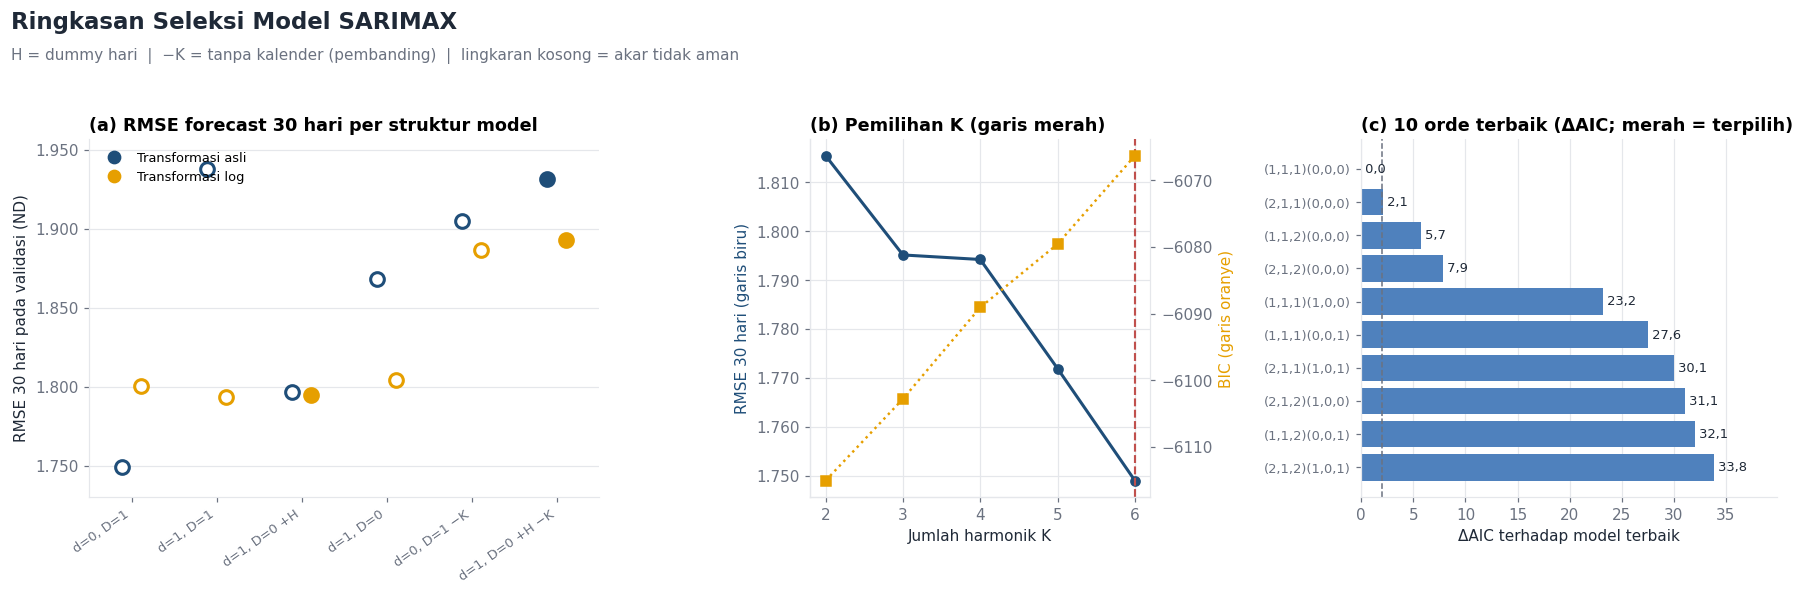

In [70]:
fig = plt.figure(figsize=(16.5, 5.6))
gs = GridSpec(1, 3, figure=fig, width_ratios=[1.35, 0.9, 1.1], wspace=0.5, left=0.055, right=0.985, top=0.78, bottom=0.2)
judul_figur(fig, "Ringkasan Seleksi Model SARIMAX", "H = dummy hari  |  −K = tanpa kalender (pembanding)  |  lingkaran kosong = akar tidak aman")
axes = [fig.add_subplot(gs[0, k]) for k in range(3)]

# (a) struktur model x transformasi
from matplotlib.lines import Line2D
ta = tabel_A.copy()
urut = list(dict.fromkeys(sorted(ta["Model"], key=lambda t: (ta[ta["Model"] == t]["RMSE 30 hari"].min()))))
warna_mode = {"asli": PALETTE["primary"], "log": PALETTE["warning"]}
geser = {nm: (j - (len(modes) - 1) / 2) * 0.22 for j, nm in enumerate(modes)}
for _, r in ta.iterrows():
    x = urut.index(r["Model"]) + geser[r["Transformasi"]]
    w = warna_mode[r["Transformasi"]]
    axes[0].scatter(x, r["RMSE 30 hari"], s=80, zorder=3, color=w if r["Akar aman"] else "white", edgecolor=w, linewidth=2)
rng = ta["RMSE 30 hari"].max() - ta["RMSE 30 hari"].min() + 1
axes[0].set_ylim(ta["RMSE 30 hari"].min() - 0.1 * rng, ta["RMSE 30 hari"].max() + 0.1 * rng)
axes[0].set_xlim(-0.5, len(urut) - 0.5)
axes[0].set_xticks(range(len(urut)))
axes[0].set_xticklabels(urut, rotation=35, ha="right", fontsize=8.5)
axes[0].set_title("(a) RMSE forecast 30 hari per struktur model")
axes[0].set_ylabel("RMSE 30 hari pada validasi (ND)")
axes[0].yaxis.set_major_formatter(ribuan)
axes[0].grid(axis="x", visible=False)
handles = [Line2D([], [], marker="o", ls="", color=warna_mode[m], markersize=8, label=f"Transformasi {m}") for m in modes]
axes[0].legend(handles=handles, loc="upper left", fontsize=8.5)

# (b) pemilihan K
ax_b = axes[1]
ax_b.plot(tabel_B["K"], tabel_B["RMSE 30 hari"], marker="o", color=PALETTE["primary"], lw=2)
ax_b.axvline(K_PILIH, color=PALETTE["accent"], ls="--", lw=1.4)
ax_b.set_xlabel("Jumlah harmonik K")
ax_b.set_ylabel("RMSE 30 hari (garis biru)", color=PALETTE["primary"])
ax_b.yaxis.set_major_formatter(ribuan)
ax_b.set_xticks(tabel_B["K"])
ax_b.set_title("(b) Pemilihan K (garis merah)")
ax_b2 = ax_b.twinx()
ax_b2.plot(tabel_B["K"], tabel_B["BIC"], marker="s", color=PALETTE["warning"], lw=1.6, ls=":")
ax_b2.set_ylabel("BIC (garis oranye)", color=PALETTE["warning"])
ax_b2.grid(False)
ax_b2.spines["right"].set_visible(True)
ax_b2.spines["right"].set_color(PALETTE["grid"])

# (c) delta AIC top 10
top = tabel_ok.head(10).iloc[::-1]
etiket = [f"({r.p},{d_PILIH},{r.q})({r.P},{D_PILIH},{r.Q})" for r in top.itertuples()]
warna_c = [PALETTE["accent"] if (r.p, r.q, r.P, r.Q) == (p_PILIH, q_PILIH, P_PILIH, Q_PILIH) else PALETTE["secondary"]
           for r in top.itertuples()]
axes[2].barh(etiket, top["Delta AIC"], color=warna_c)
for yy, v in enumerate(top["Delta AIC"]):
    axes[2].text(v, yy, f" {angka(v, 1)}", va="center", fontsize=8.5, color=PALETTE["text"])
axes[2].axvline(2, color=PALETTE["neutral"], ls="--", lw=1)
axes[2].set_xlim(0, max(top["Delta AIC"].max() * 1.18, 4))
axes[2].set_title("(c) 10 orde terbaik (ΔAIC; merah = terpilih)")
axes[2].set_xlabel("ΔAIC terhadap model terbaik")
axes[2].grid(axis="y", visible=False)
axes[2].tick_params(axis="y", labelsize=8.5)

simpan_figur(fig, "12_ringkasan_seleksi_model")
plt.show()

## 5.5 Diagnostik Residual dan Uji Nonlinearitas

Model terpilih di-fit pada train, lalu residualnya diuji:

| Uji | H0 | Hasil yang diharapkan |
|:--|:--|:--|
| Ljung–Box (lag 7, 14, 21, 28) | Residual white noise (tanpa autokorelasi) | p > 0,05 |
| Jarque–Bera | Residual berdistribusi normal | p > 0,05 (sering gagal pada data panjang, tidak fatal) |
| ARCH-LM | Varians residual konstan | p > 0,05 |
| **BDS** (dimensi 2 dan 3) | Residual i.i.d. (tanpa struktur nonlinear) | **p < 0,05 mendukung penggunaan GRU** |

**Penting:** BDS baru bermakna sebagai bukti nonlinearitas bila **Ljung–Box lolos**. Jika residual masih berautokorelasi linear, BDS ikut menolak karena struktur linear yang belum tertangkap, bukan karena nonlinearitas.

In [71]:
res_sarimax = fit_sarimax(SPEK_FINAL)
e = res_sarimax.resid.iloc[BURN:]
model_df = p_PILIH + q_PILIH + P_PILIH + Q_PILIH

lb = acorr_ljungbox(e, lags=[7, 14, 21, 28], model_df=model_df, return_df=True)
jb_stat, jb_p = stats.jarque_bera(e)
arch_p = het_arch(e, nlags=7)[1]
bds_stat, bds_p = bds(e.values, max_dim=3)

baris = [(f"Ljung-Box lag {k}", "Residual white noise", float(lb.loc[k, "lb_pvalue"]),
          "Lolos" if lb.loc[k, "lb_pvalue"] > 0.05 else "Tidak lolos (masih ada autokorelasi)") for k in lb.index]
baris += [
    ("Jarque-Bera", "Residual normal", float(jb_p), "Lolos" if jb_p > 0.05 else "Tidak normal"),
    ("ARCH-LM (7 lag)", "Varians konstan", float(arch_p), "Lolos" if arch_p > 0.05 else "Varians tidak konstan"),
    ("BDS dimensi 2", "Residual i.i.d.", float(bds_p[0]), "Ada struktur (linear/nonlinear)" if bds_p[0] < 0.05 else "Tidak ada bukti struktur"),
    ("BDS dimensi 3", "Residual i.i.d.", float(bds_p[1]), "Ada struktur (linear/nonlinear)" if bds_p[1] < 0.05 else "Tidak ada bukti struktur"),
]
tabel_diag = pd.DataFrame(baris, columns=["Uji", "H0", "p-value", "Kesimpulan"]).set_index("Uji")
tabel_diag["p-value"] = tabel_diag["p-value"].round(4)
display(tabel_diag)
tabel_diag.to_csv(Path(CFG.table_dir) / "16_diagnostik_residual_sarimax.csv")

print(f"Skewness residual = {stats.skew(e):.3f} | kurtosis (excess) = {stats.kurtosis(e):.3f}")
if akar_minimum(res_sarimax) <= 1.0:
    print("PERINGATAN: ada akar AR/MA pada atau di dalam lingkaran satuan. Model hampir tidak stasioner/invertibel.")
else:
    print(f"Semua akar AR dan MA berada di luar lingkaran satuan (akar terkecil = {akar_minimum(res_sarimax):.3f}).")

# --- pemeriksaan kewajaran ---
lb_gagal = bool((lb["lb_pvalue"] <= 0.05).any())
if lb_gagal:
    print("\nCATATAN: Ljung-Box menolak. Struktur linear belum sepenuhnya tertangkap, sehingga hasil BDS "
          "BELUM dapat ditafsirkan sebagai bukti nonlinearitas. Periksa ACF residual (panel d di bawah).")
nama_param = list(res_sarimax.params.index)
kelompok = {"Fourier": [n for n in nama_param if n.startswith(("sin", "cos"))],
            "Kalender": [n for n in nama_param if n in ("libur", "natal", "covid")],
            "Dummy hari": [n for n in nama_param if n.startswith("hari")]}
for nama_g, daftar in kelompok.items():
    if daftar:
        sig = int((res_sarimax.pvalues[daftar] < 0.05).sum())
        print(f"Koefisien {nama_g} yang signifikan (p < 0,05): {sig} dari {len(daftar)}")
if kelompok["Fourier"] and int((res_sarimax.pvalues[kelompok["Fourier"]] < 0.05).sum()) == 0:
    print("PERINGATAN: tidak ada koefisien Fourier yang signifikan. Pola tahunan TIDAK ikut terbawa ke forecast.")

,H0,p-value,Kesimpulan
Uji,,,
Ljung-Box lag 7,Residual white noise,0.0031,Tidak lolos (masih ada autokorelasi)
Ljung-Box lag 14,Residual white noise,0.0003,Tidak lolos (masih ada autokorelasi)
Ljung-Box lag 21,Residual white noise,0.0001,Tidak lolos (masih ada autokorelasi)
Ljung-Box lag 28,Residual white noise,0.0001,Tidak lolos (masih ada autokorelasi)
Jarque-Bera,Residual normal,0.0000,Tidak normal
ARCH-LM (7 lag),Varians konstan,0.0003,Varians tidak konstan
BDS dimensi 2,Residual i.i.d.,0.0007,Ada struktur (linear/nonlinear)
BDS dimensi 3,Residual i.i.d.,0.0000,Ada struktur (linear/nonlinear)


Skewness residual = -0.331 | kurtosis (excess) = 0.507
Semua akar AR dan MA berada di luar lingkaran satuan (akar terkecil = 1.011).

CATATAN: Ljung-Box menolak. Struktur linear belum sepenuhnya tertangkap, sehingga hasil BDS BELUM dapat ditafsirkan sebagai bukti nonlinearitas. Periksa ACF residual (panel d di bawah).
Koefisien Fourier yang signifikan (p < 0,05): 4 dari 12
Koefisien Kalender yang signifikan (p < 0,05): 3 dari 3
Koefisien Dummy hari yang signifikan (p < 0,05): 6 dari 6


Figur disimpan: results_2020/figures/13_diagnostik_residual_sarimax.png


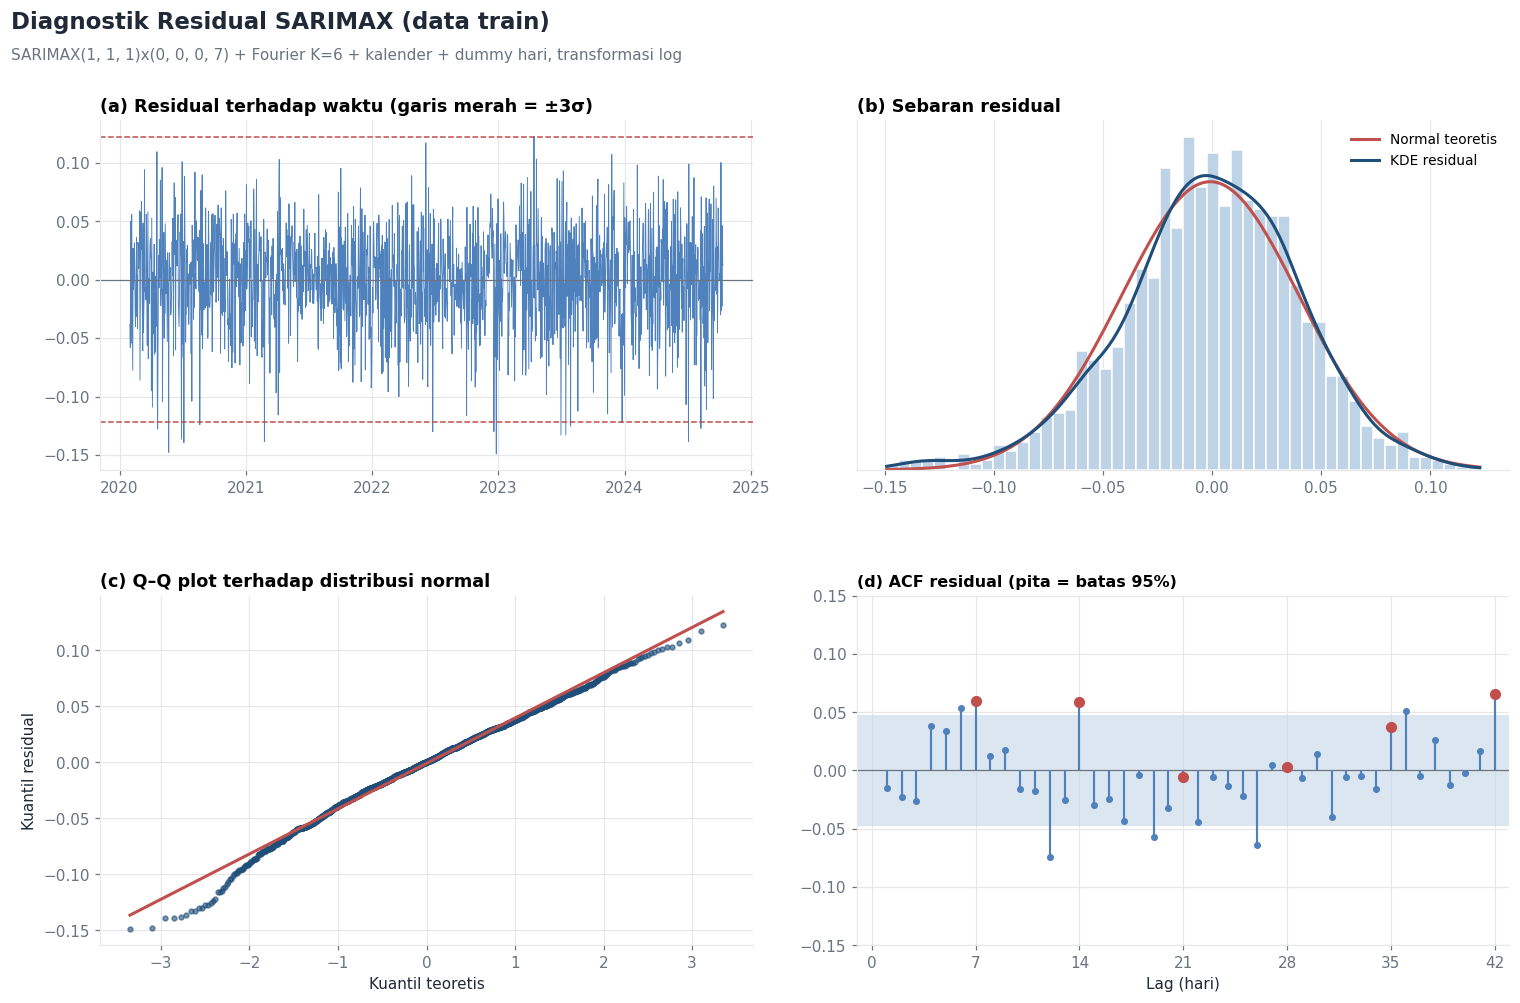

In [72]:
fig = plt.figure(figsize=(14, 9.2))
gs = GridSpec(2, 2, figure=fig, hspace=0.36, wspace=0.16, left=0.07, right=0.985, top=0.885, bottom=0.07)
judul_figur(fig, "Diagnostik Residual SARIMAX (data train)", deskripsi(SPEK_FINAL))

sd_e = e.std()
ax = fig.add_subplot(gs[0, 0])
ax.plot(e.index, e, color=PALETTE["secondary"], lw=0.6)
for k in (-3, 3):
    ax.axhline(k * sd_e, color=PALETTE["accent"], ls="--", lw=1)
ax.axhline(0, color=PALETTE["neutral"], lw=0.8)
ax.set_title("(a) Residual terhadap waktu (garis merah = ±3σ)")
if MODE_PILIH == "asli":
    ax.yaxis.set_major_formatter(ribuan)

ax = fig.add_subplot(gs[0, 1])
ax.hist(e, bins=50, density=True, color=PALETTE["light"], edgecolor="white")
xs_e = np.linspace(e.min(), e.max(), 300)
ax.plot(xs_e, stats.norm.pdf(xs_e, e.mean(), sd_e), color=PALETTE["accent"], lw=2, label="Normal teoretis")
ax.plot(xs_e, stats.gaussian_kde(e)(xs_e), color=PALETTE["primary"], lw=2, label="KDE residual")
ax.set_title("(b) Sebaran residual")
ax.set_yticks([])
ax.legend()

ax = fig.add_subplot(gs[1, 0])
(osm, osr), (kemiringan, titik_potong, _) = stats.probplot(e, dist="norm")
ax.scatter(osm, osr, s=10, color=PALETTE["primary"], alpha=0.6)
ax.plot(osm, kemiringan * osm + titik_potong, color=PALETTE["accent"], lw=2)
ax.set_title("(c) Q–Q plot terhadap distribusi normal")
ax.set_xlabel("Kuantil teoretis")
ax.set_ylabel("Kuantil residual")

ax = fig.add_subplot(gs[1, 1])
ac_e = acf(e, nlags=42, fft=True)
stem_acf(ax, ac_e, "(d) ACF residual (pita = batas 95%)", 1.96 / np.sqrt(len(e)), max(0.15, 1.3 * np.abs(ac_e[1:]).max()))
ax.set_xlabel("Lag (hari)")

simpan_figur(fig, "13_diagnostik_residual_sarimax")
plt.show()

## 5.6 Koefisien Model dan Kinerja pada Train dan Validasi

Kinerja utama dihitung **one-step-ahead** dalam satuan ND asli (format pelaporan penelitian). Untuk validasi, parameter dikunci dari train. Sebagai pelengkap ditampilkan juga kinerja **forecast 30 hari bergulir** pada validasi, supaya terlihat selisih antara akurasi satu langkah dan akurasi peramalan 30 hari. Data test baru dipakai pada tahap evaluasi akhir.

In [73]:
ci = res_sarimax.conf_int()
koef = pd.DataFrame({"Koefisien": res_sarimax.params, "Galat baku": res_sarimax.bse,
                     "z": res_sarimax.tvalues, "p-value": res_sarimax.pvalues,
                     "CI 95% bawah": ci.iloc[:, 0], "CI 95% atas": ci.iloc[:, 1]})
koef.index.name = "Parameter"
display(koef.round(4))
koef.round(6).to_csv(Path(CFG.table_dir) / "17_koefisien_sarimax.csv")

_, pred_all = prediksi_satu_langkah(res_sarimax, SPEK_FINAL, n_val_end)
pred_train = ke_asli(res_sarimax.fittedvalues, MODE_PILIH).iloc[BURN:]
pred_val = pred_all.iloc[n_train:n_val_end]
u30_final, jendela_final = forecast_bergulir(res_sarimax, SPEK_FINAL)

kinerja = pd.DataFrame(
    {"Train (1 langkah)": ukuran(y_train.iloc[BURN:], pred_train),
     "Validasi (1 langkah)": ukuran(y_val, pred_val),
     "Validasi (30 hari bergulir)": {k: u30_final[k] for k in ("RMSE", "MAE", "MAPE", "sMAPE")}}
).T.round(3)
display(kinerja)
kinerja.to_csv(Path(CFG.table_dir) / "18_kinerja_sarimax_train_validasi.csv")

# --- spesifikasi disimpan untuk tahap berikutnya ---
SPEK = {**{k: (list(v) if isinstance(v, tuple) else v) for k, v in SPEK_FINAL.items()},
        "burn": BURN, "AIC": float(res_sarimax.aic), "BIC": float(res_sarimax.bic)}
with open(Path(CFG.table_dir) / "19_spesifikasi_sarimax.json", "w", encoding="utf-8") as f:
    json.dump(SPEK, f, indent=2)
print("Spesifikasi tersimpan:", json.dumps(SPEK))

,Koefisien,Galat baku,z,p-value,CI 95% bawah,CI 95% atas
Parameter,,,,,,
sin1,0.0264,0.0064,4.1371,0.0000,0.0139,0.0389
cos1,0.1682,0.0062,27.2449,0.0000,0.1561,0.1803
sin2,0.0050,0.0057,0.8740,0.3821,-0.0062,0.0161
cos2,0.0174,0.0053,3.2898,0.0010,0.0070,0.0277
sin3,-0.0062,0.0052,-1.1891,0.2344,-0.0165,0.0040
cos3,-0.0067,0.0052,-1.2809,0.2002,-0.0169,0.0035
sin4,-0.0049,0.0053,-0.9340,0.3503,-0.0152,0.0054
cos4,-0.0039,0.0049,-0.7986,0.4245,-0.0136,0.0057
sin5,-0.0053,0.0051,-1.0422,0.2973,-0.0153,0.0047


,RMSE,MAE,MAPE,sMAPE
Train (1 langkah),1070.937,838.020,3.178,3.166
Validasi (1 langkah),1198.494,932.968,3.622,3.606
Validasi (30 hari bergulir),1748.975,1371.346,5.268,5.205


Spesifikasi tersimpan: {"mode": "log", "K": 6, "order": [1, 1, 1], "sorder": [0, 0, 0, 7], "dow": true, "kal": true, "burn": 30, "AIC": -6197.470148427776, "BIC": -6066.3356699205215}


Figur disimpan: results_2020/figures/14_sarimax_validasi.png


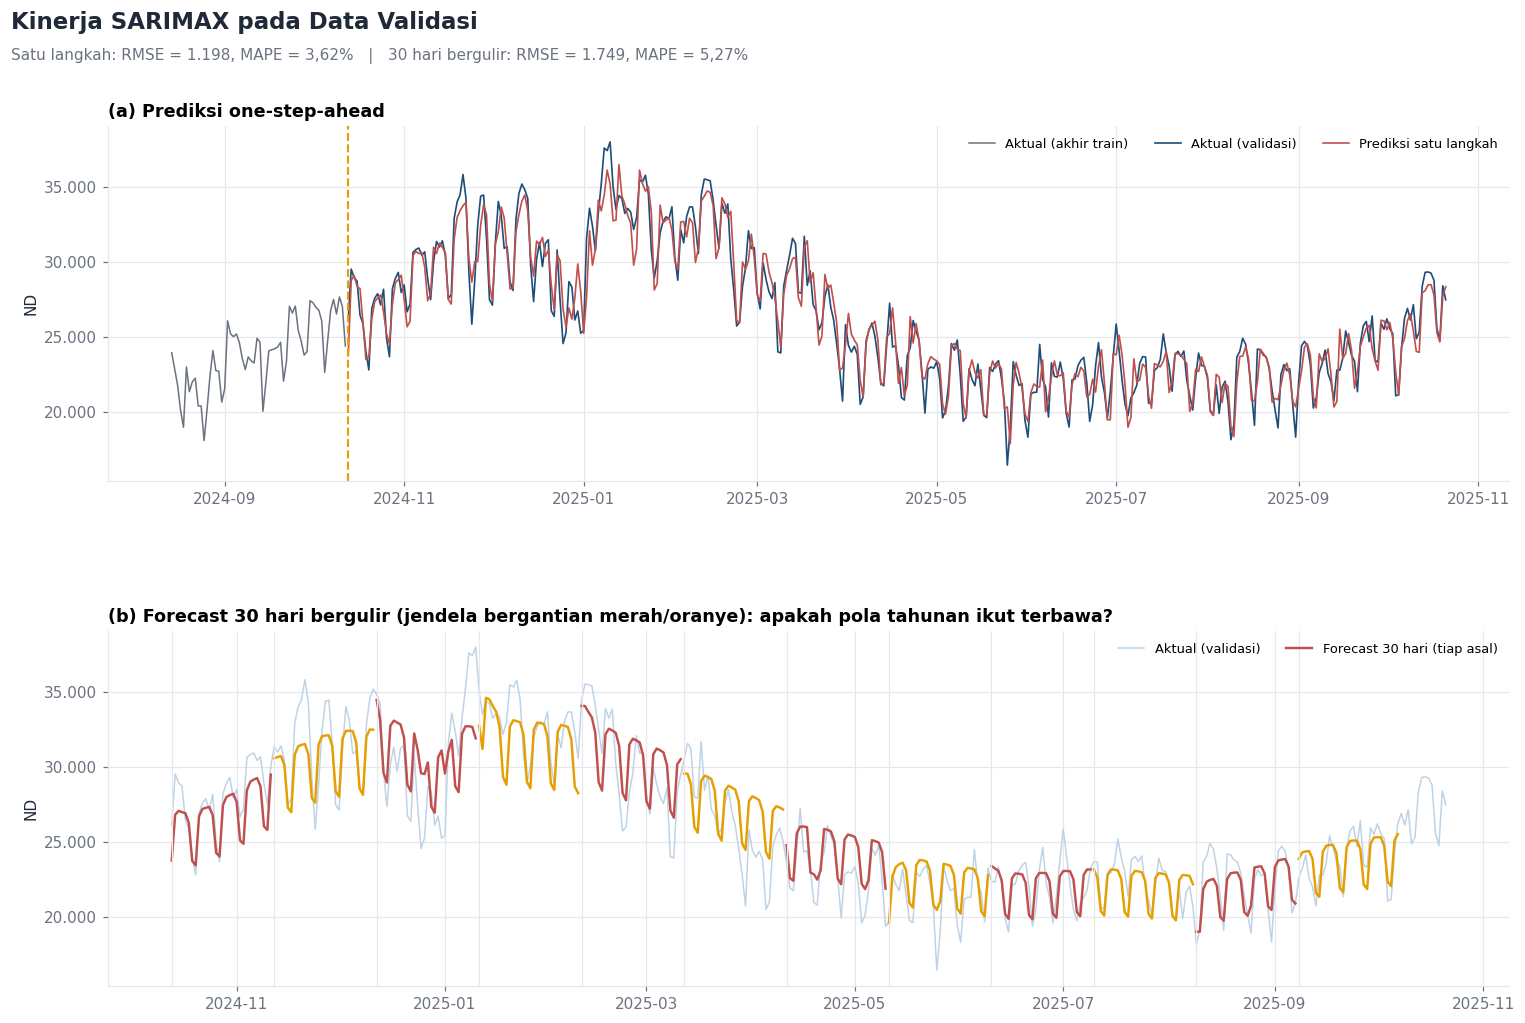

RINGKASAN TAHAP 5 -> SARIMAX(1, 1, 1)x(0, 0, 0, 7) + Fourier K=6 + kalender + dummy hari, transformasi log
Tahap 5 selesai. Lanjut ke Tahap 6: GRU pada residual SARIMAX (tuning memakai data validasi).


In [74]:
fig = plt.figure(figsize=(14, 9.6))
gs = GridSpec(2, 1, figure=fig, height_ratios=[1, 1], hspace=0.42, left=0.075, right=0.985, top=0.885, bottom=0.07)
judul_figur(fig, "Kinerja SARIMAX pada Data Validasi",
            f"Satu langkah: RMSE = {angka(kinerja.iloc[1]['RMSE'])}, MAPE = {angka(kinerja.iloc[1]['MAPE'], 2)}%   |   "
            f"30 hari bergulir: RMSE = {angka(kinerja.iloc[2]['RMSE'])}, MAPE = {angka(kinerja.iloc[2]['MAPE'], 2)}%")

ax = fig.add_subplot(gs[0])
ekor = y_train.iloc[-60:]
ax.plot(ekor.index, ekor, color=PALETTE["neutral"], lw=1, label="Aktual (akhir train)")
ax.plot(y_val.index, y_val, color=PALETTE["primary"], lw=1.1, label="Aktual (validasi)")
ax.plot(pred_val.index, pred_val, color=PALETTE["accent"], lw=1.1, label="Prediksi satu langkah")
ax.axvline(y_val.index[0], color=PALETTE["warning"], ls="--", lw=1.4)
ax.yaxis.set_major_formatter(ribuan)
ax.set_ylabel("ND")
ax.set_title("(a) Prediksi one-step-ahead")
ax.legend(loc="upper right", ncol=3, fontsize=8.5)

ax = fig.add_subplot(gs[1])
ax.plot(y_val.index, y_val, color=PALETTE["light"], lw=1, label="Aktual (validasi)")
for k, (akt, fc) in enumerate(jendela_final):
    ax.plot(fc.index, fc.values, color=PALETTE["accent"] if k % 2 == 0 else PALETTE["warning"], lw=1.6,
            label="Forecast 30 hari (tiap asal)" if k == 0 else None)
    ax.axvline(akt.index[0], color=PALETTE["grid"], lw=0.8)
ax.yaxis.set_major_formatter(ribuan)
ax.set_ylabel("ND")
ax.set_title("(b) Forecast 30 hari bergulir (jendela bergantian merah/oranye): apakah pola tahunan ikut terbawa?")
ax.legend(loc="upper right", ncol=2, fontsize=8.5)

simpan_figur(fig, "14_sarimax_validasi")
plt.show()

print("=" * 78)
print(f"RINGKASAN TAHAP 5 -> {deskripsi(SPEK_FINAL)}")
print("=" * 78)
print("Tahap 5 selesai. Lanjut ke Tahap 6: GRU pada residual SARIMAX (tuning memakai data validasi).")

# TAHAP 6 — GRU: Hybrid SARIMAX–GRU, Hybrid + Kalender, dan GRU Murni

**Tujuan:** melatih GRU dan membandingkannya dengan SARIMAX **hanya pada train dan validasi**. Data test belum disentuh.

| Model | Input GRU | Target GRU | Prediksi akhir |
|:--|:--|:--|:--|
| **Hybrid SARIMAX–GRU** (Zhang, 2003) | L residual SARIMAX sebelumnya | residual hari ini | prediksi SARIMAX + prediksi residual |
| **Hybrid + kalender** | L residual sebelumnya + fitur kalender hari target | residual hari ini | prediksi SARIMAX + prediksi residual |
| **GRU murni** (pembanding) | L nilai ND sebelumnya + fitur kalender hari target | ND hari ini | prediksi GRU |

**Aturan anti-leakage:** scaler hanya di-fit pada train; validasi dipakai untuk memilih (L, unit) dan early stopping; parameter SARIMAX terkunci dari train. Semua prediksi adalah **one-step-ahead**.

## 6.1 Residual One-Step SARIMAX

In [75]:
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import tensorflow as tf
from tensorflow.keras import layers, callbacks, Model
from sklearn.preprocessing import StandardScaler

tf.keras.utils.set_random_seed(CFG.seed)

# Prediksi one-step SARIMAX (parameter dari train) sampai akhir validasi, satuan ND asli
_, pred_sar_all = prediksi_satu_langkah(res_sarimax, SPEK_FINAL, n_val_end)
N_G = n_val_end                                           # panjang data yang boleh dipakai (train + validasi)
y_g = y.iloc[:N_G].to_numpy(float)
sar_g = pred_sar_all.to_numpy(float)
resid_g = y_g - sar_g                                     # residual dalam satuan ND asli
resid_g[:BURN] = np.nan                                   # residual awal (inisialisasi state-space) dibuang

r_tr = resid_g[BURN:n_train]
r_va = resid_g[n_train:N_G]
print(f"Residual train: rata-rata {r_tr.mean():.1f}, simpangan baku {r_tr.std():.1f}")
print(f"Residual validasi: rata-rata {r_va.mean():.1f}, simpangan baku {r_va.std():.1f}")

lb_v = acorr_ljungbox(pd.Series(r_va), lags=[7, 14, 21, 28], return_df=True)
print("\nLjung-Box residual SARIMAX pada VALIDASI (p-value):", lb_v["lb_pvalue"].round(3).to_dict())
if (lb_v["lb_pvalue"] > 0.05).all():
    print("-> Residual validasi sudah mendekati white noise. Ruang perbaikan oleh GRU pada residual kecil; "
          "hasil hybrid yang hanya sedikit lebih baik adalah temuan yang wajar dan perlu dilaporkan apa adanya.")

Residual train: rata-rata -3.3, simpangan baku 1070.9
Residual validasi: rata-rata 22.7, simpangan baku 1198.3

Ljung-Box residual SARIMAX pada VALIDASI (p-value): {7: 0.068, 14: 0.278, 21: 0.338, 28: 0.483}
-> Residual validasi sudah mendekati white noise. Ruang perbaikan oleh GRU pada residual kecil; hasil hybrid yang hanya sedikit lebih baik adalah temuan yang wajar dan perlu dilaporkan apa adanya.


## 6.2 Scaler, Jendela (Window), dan Fitur Kalender

Setiap sampel = `L` nilai sebelumnya → 1 nilai target. Scaler (`StandardScaler`) di-fit **hanya pada train**.
Fitur kalender hari target (Fourier, libur, Natal, COVID, dummy hari) tersedia di muka karena merupakan fakta kalender, bukan informasi bocoran.

In [76]:
SC_R = StandardScaler().fit(r_tr.reshape(-1, 1))                       # untuk residual
SC_Y = StandardScaler().fit(y_g[:n_train].reshape(-1, 1))              # untuk ND (GRU murni)

FIT_E = regresor(y.index[:N_G], SPEK_FINAL["K"], dow=True, kal=True)   # fitur kalender seluruh periode train+val
SC_E = StandardScaler().fit(FIT_E.iloc[:n_train].to_numpy())
E_g = SC_E.transform(FIT_E.to_numpy())
N_E = E_g.shape[1]
print(f"Fitur kalender hari target: {N_E} kolom -> {list(FIT_E.columns)}")

JENIS = {   # nama model: (deret_masukan, pakai_kalender)
    "Hybrid SARIMAX-GRU": ("resid", False),
    "Hybrid + kalender": ("resid", True),
    "GRU murni": ("nd", True),
}


def seri_skala(jenis):
    if jenis == "resid":
        return SC_R.transform(np.nan_to_num(resid_g, nan=0.0).reshape(-1, 1)).ravel()
    return SC_Y.transform(y_g.reshape(-1, 1)).ravel()


def bentuk_data(nama, L):
    """Susun jendela. Target pada posisi j memakai input posisi j-L .. j-1 (hanya masa lalu)."""
    jenis, pakai_e = JENIS[nama]
    s = seri_skala(jenis)
    awal = (BURN + L) if jenis == "resid" else L
    def ambil(a, b):
        pos = np.arange(max(a, awal), b)
        X = np.stack([s[j - L:j] for j in pos])[:, :, None].astype("float32")
        E = E_g[pos].astype("float32") if pakai_e else None
        return pos, X, E, s[pos].astype("float32")
    return {"tr": ambil(0, n_train), "va": ambil(n_train, N_G)}


def ke_prediksi(nama, yhat_skala, pos):
    """Skala GRU -> prediksi akhir dalam satuan ND asli."""
    jenis, _ = JENIS[nama]
    if jenis == "resid":
        return sar_g[pos] + SC_R.inverse_transform(np.asarray(yhat_skala).reshape(-1, 1)).ravel()
    return SC_Y.inverse_transform(np.asarray(yhat_skala).reshape(-1, 1)).ravel()


def bangun_gru(L, unit, pakai_e):
    masuk = layers.Input((L, 1))
    h = layers.GRU(unit)(masuk)
    h = layers.Dropout(0.1)(h)
    inputs = [masuk]
    if pakai_e:
        e_in = layers.Input((N_E,))
        h = layers.Concatenate()([h, e_in])
        inputs.append(e_in)
    h = layers.Dense(16, activation="relu")(h)
    model = Model(inputs, layers.Dense(1)(h))
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")
    return model


def latih_gru(nama, L, unit, seed, data=None):
    data = data or bentuk_data(nama, L)
    _, Xtr, Etr, Ytr = data["tr"]
    _, Xva, Eva, Yva = data["va"]
    pakai_e = JENIS[nama][1]
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    model = bangun_gru(L, unit, pakai_e)
    xt = [Xtr, Etr] if pakai_e else [Xtr]
    xv = [Xva, Eva] if pakai_e else [Xva]
    es = callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)
    hist = model.fit(xt, Ytr, validation_data=(xv, Yva), epochs=200, batch_size=32, callbacks=[es], verbose=0)
    return model, int(np.argmin(hist.history["val_loss"])) + 1, hist.history


def prediksi_gru(model, nama, data, bagian):
    pos, X, E, _ = data[bagian]
    x = [X, E] if JENIS[nama][1] else [X]
    return pos, model.predict(x, verbose=0).ravel()


d_contoh = bentuk_data("Hybrid SARIMAX-GRU", 14)
print("Contoh bentuk data (hybrid, L=14): train", d_contoh["tr"][1].shape, "| validasi", d_contoh["va"][1].shape)

Fitur kalender hari target: 21 kolom -> ['sin1', 'cos1', 'sin2', 'cos2', 'sin3', 'cos3', 'sin4', 'cos4', 'sin5', 'cos5', 'sin6', 'cos6', 'libur', 'natal', 'covid', 'hari1', 'hari2', 'hari3', 'hari4', 'hari5', 'hari6']
Contoh bentuk data (hybrid, L=14): train (1703, 14, 1) | validasi (374, 14, 1)


## 6.3 Tuning Hyperparameter (Grid pada Validasi)

Grid: panjang jendela **L ∈ {7, 14, 30}** × unit GRU **{16, 32, 64}** (dropout 0,1; Adam 1e-3; batch 32; early stopping sabar 15 epoch pada loss validasi). Konfigurasi dipilih berdasarkan **RMSE validasi dalam satuan ND asli** (set validasi sama untuk semua L, sehingga adil).

In [77]:
GRID_L = (7, 14, 30)
GRID_U = (16, 32, 64)
tabel_grid = {}
BEST = {}
t_mulai = time.time()
for nama in JENIS:
    baris = []
    for L in GRID_L:
        data = bentuk_data(nama, L)
        for unit in GRID_U:
            model, ep, _ = latih_gru(nama, L, unit, CFG.seed, data=data)
            pos, yh = prediksi_gru(model, nama, data, "va")
            rm = ukuran(y_g[pos], ke_prediksi(nama, yh, pos))["RMSE"]
            baris.append({"L": L, "Unit": unit, "Epoch terbaik": ep, "RMSE validasi": rm})
    tg = pd.DataFrame(baris)
    tabel_grid[nama] = tg
    b = tg.loc[tg["RMSE validasi"].idxmin()]
    BEST[nama] = {"L": int(b["L"]), "unit": int(b["Unit"])}
    print(f"{nama:<20} -> L={BEST[nama]['L']}, unit={BEST[nama]['unit']}, RMSE validasi={b['RMSE validasi']:.1f}  "
          f"[{(time.time() - t_mulai) / 60:.1f} menit]")
    tg.to_csv(Path(CFG.table_dir) / f"20_grid_gru_{nama.replace(' ', '_').replace('+', 'plus')}.csv", index=False)

Hybrid SARIMAX-GRU   -> L=7, unit=64, RMSE validasi=1170.9  [4.8 menit]
Hybrid + kalender    -> L=7, unit=32, RMSE validasi=1172.6  [8.4 menit]
GRU murni            -> L=30, unit=32, RMSE validasi=1214.9  [14.9 menit]


## 6.4 Ensemble 5 Seed

GRU bersifat stokastik (inisialisasi bobot, urutan batch). Konfigurasi terpilih dilatih ulang dengan **5 seed** (42–46) dan prediksinya **dirata-ratakan**. Jumlah epoch terbaik (median) disimpan untuk refit pada Tahap 8.

In [78]:
SEEDS = [CFG.seed + k for k in range(5)]
HASIL = {}
for nama in JENIS:
    L, unit = BEST[nama]["L"], BEST[nama]["unit"]
    data = bentuk_data(nama, L)
    p_tr, p_va, eps, rm_seed, models = [], [], [], [], []
    for sd in SEEDS:
        model, ep, _ = latih_gru(nama, L, unit, sd, data=data)
        pos_tr, yh_tr = prediksi_gru(model, nama, data, "tr")
        pos_va, yh_va = prediksi_gru(model, nama, data, "va")
        p_tr.append(ke_prediksi(nama, yh_tr, pos_tr))
        p_va.append(ke_prediksi(nama, yh_va, pos_va))
        eps.append(ep); models.append(model)
        rm_seed.append(ukuran(y_g[pos_va], p_va[-1])["RMSE"])
    HASIL[nama] = {
        "L": L, "unit": unit, "epoch": int(np.median(eps)), "epoch_per_seed": eps,
        "pos_tr": pos_tr, "pos_va": pos_va,
        "pred_tr": pd.Series(np.mean(p_tr, axis=0), index=y.index[pos_tr]),
        "pred_va": pd.Series(np.mean(p_va, axis=0), index=y.index[pos_va]),
        "rmse_seed": rm_seed, "models": models,
    }
    print(f"{nama:<20} L={L:<2} unit={unit:<2} | epoch per seed {eps} | RMSE validasi per seed: "
          f"min {min(rm_seed):.0f}, maks {max(rm_seed):.0f} | ensemble: {ukuran(y_g[pos_va], HASIL[nama]['pred_va'])['RMSE']:.1f}")

pd.DataFrame({n: {"L": h["L"], "Unit": h["unit"], "Epoch (median)": h["epoch"]} for n, h in HASIL.items()}).T.to_csv(
    Path(CFG.table_dir) / "21_konfigurasi_gru_terpilih.csv")

Hybrid SARIMAX-GRU   L=7  unit=64 | epoch per seed [30, 20, 21, 24, 24] | RMSE validasi per seed: min 1170, maks 1178 | ensemble: 1173.0
Hybrid + kalender    L=7  unit=32 | epoch per seed [14, 32, 9, 35, 24] | RMSE validasi per seed: min 1173, maks 1206 | ensemble: 1174.4
GRU murni            L=30 unit=32 | epoch per seed [56, 32, 51, 54, 61] | RMSE validasi per seed: min 1215, maks 1280 | ensemble: 1205.6


## 6.5 Perbandingan pada Train dan Validasi

Pembanding: **seasonal naive** (nilai 7 hari lalu) dan **SARIMAX**. Uji **Diebold–Mariano** (loss kuadrat, Newey–West lag 7) membandingkan galat setiap model terhadap SARIMAX pada validasi; p < 0,05 berarti perbedaan akurasi signifikan.
Pembandingan ini hanya untuk **pemilihan model**; klaim akhir dibuat pada data **test** (Tahap 7).

In [79]:
def dm_test(g_pembanding, g_usulan, lag=7):
    d = np.asarray(g_pembanding) ** 2 - np.asarray(g_usulan) ** 2
    n = len(d); dm = d - d.mean()
    v = np.sum(dm ** 2) / n
    for k in range(1, lag + 1):
        v += 2 * (1 - k / (lag + 1)) * np.sum(dm[k:] * dm[:-k]) / n
    stat = d.mean() / np.sqrt(v / n)
    return stat, 2 * (1 - stats.norm.cdf(abs(stat)))


# Dasar pembanding pada indeks validasi penuh
pos_va_all = np.arange(n_train, N_G)
y_va_arr = y_g[pos_va_all]
pred_va_model = {
    "Seasonal naive (t-7)": y.shift(7).iloc[pos_va_all].to_numpy(),
    "SARIMAX": sar_g[pos_va_all],
}
for nama in JENIS:
    pred_va_model[nama] = HASIL[nama]["pred_va"].to_numpy()

# Train: pada posisi yang sama dengan model GRU terpendek jendelanya agar adil, cukup laporkan per model
baris_val, baris_tr = {}, {}
for nama, pr in pred_va_model.items():
    baris_val[nama] = ukuran(y_va_arr, pr)
tr_pos = np.arange(BURN, n_train)
baris_tr["Seasonal naive (t-7)"] = ukuran(y_g[tr_pos], y.shift(7).iloc[tr_pos].to_numpy())
baris_tr["SARIMAX"] = ukuran(y_g[tr_pos], sar_g[tr_pos])
for nama in JENIS:
    baris_tr[nama] = ukuran(y_g[HASIL[nama]["pos_tr"]], HASIL[nama]["pred_tr"].to_numpy())

tab_val = pd.DataFrame(baris_val).T
tab_tr = pd.DataFrame(baris_tr).T
ref_gal = y_va_arr - pred_va_model["SARIMAX"]
dm_rows = {}
for nama in pred_va_model:
    if nama == "SARIMAX":
        continue
    g = y_va_arr - pred_va_model[nama]
    s, p = dm_test(ref_gal, g)
    dm_rows[nama] = {"Selisih RMSE vs SARIMAX (%)": 100 * (tab_val.loc[nama, "RMSE"] / tab_val.loc["SARIMAX", "RMSE"] - 1),
                     "DM stat": s, "DM p-value": p,
                     "Ljung-Box p (lag 7)": float(acorr_ljungbox(pd.Series(g), lags=[7], return_df=True)["lb_pvalue"].iloc[0])}
tab_dm = pd.DataFrame(dm_rows).T

print("TRAIN (one-step-ahead, satuan ND asli)")
display(tab_tr.round(3))
print("VALIDASI (one-step-ahead, satuan ND asli)")
display(tab_val.round(3))
print("Uji Diebold-Mariano terhadap SARIMAX pada VALIDASI (nilai negatif pada selisih RMSE = lebih baik dari SARIMAX)")
display(tab_dm.round(4))
tab_tr.round(4).to_csv(Path(CFG.table_dir) / "22_kinerja_train_tahap6.csv")
tab_val.round(4).to_csv(Path(CFG.table_dir) / "23_kinerja_validasi_tahap6.csv")
tab_dm.round(4).to_csv(Path(CFG.table_dir) / "24_uji_dm_validasi_tahap6.csv")

TRAIN (one-step-ahead, satuan ND asli)


,RMSE,MAE,MAPE,sMAPE
Seasonal naive (t-7),2265.574,1719.050,6.400,6.359
SARIMAX,1070.937,838.020,3.178,3.166
Hybrid SARIMAX-GRU,1049.003,817.712,3.106,3.097
Hybrid + kalender,975.936,762.079,2.897,2.889
GRU murni,957.007,749.247,2.849,2.841


VALIDASI (one-step-ahead, satuan ND asli)


,RMSE,MAE,MAPE,sMAPE
Seasonal naive (t-7),2398.749,1853.385,6.991,6.971
SARIMAX,1198.494,932.968,3.622,3.606
Hybrid SARIMAX-GRU,1173.021,909.914,3.537,3.525
Hybrid + kalender,1174.354,921.917,3.579,3.565
GRU murni,1205.554,927.428,3.624,3.589


Uji Diebold-Mariano terhadap SARIMAX pada VALIDASI (nilai negatif pada selisih RMSE = lebih baik dari SARIMAX)


,Selisih RMSE vs SARIMAX (%),DM stat,DM p-value,Ljung-Box p (lag 7)
Seasonal naive (t-7),100.1469,-4.4566,0.0000,0.0000
Hybrid SARIMAX-GRU,-2.1254,1.8703,0.0614,0.4733
Hybrid + kalender,-2.0142,1.3841,0.1663,0.1131
GRU murni,0.5890,-0.2080,0.8352,0.0163


Figur disimpan: results_2020/figures/15_perbandingan_model_validasi.png


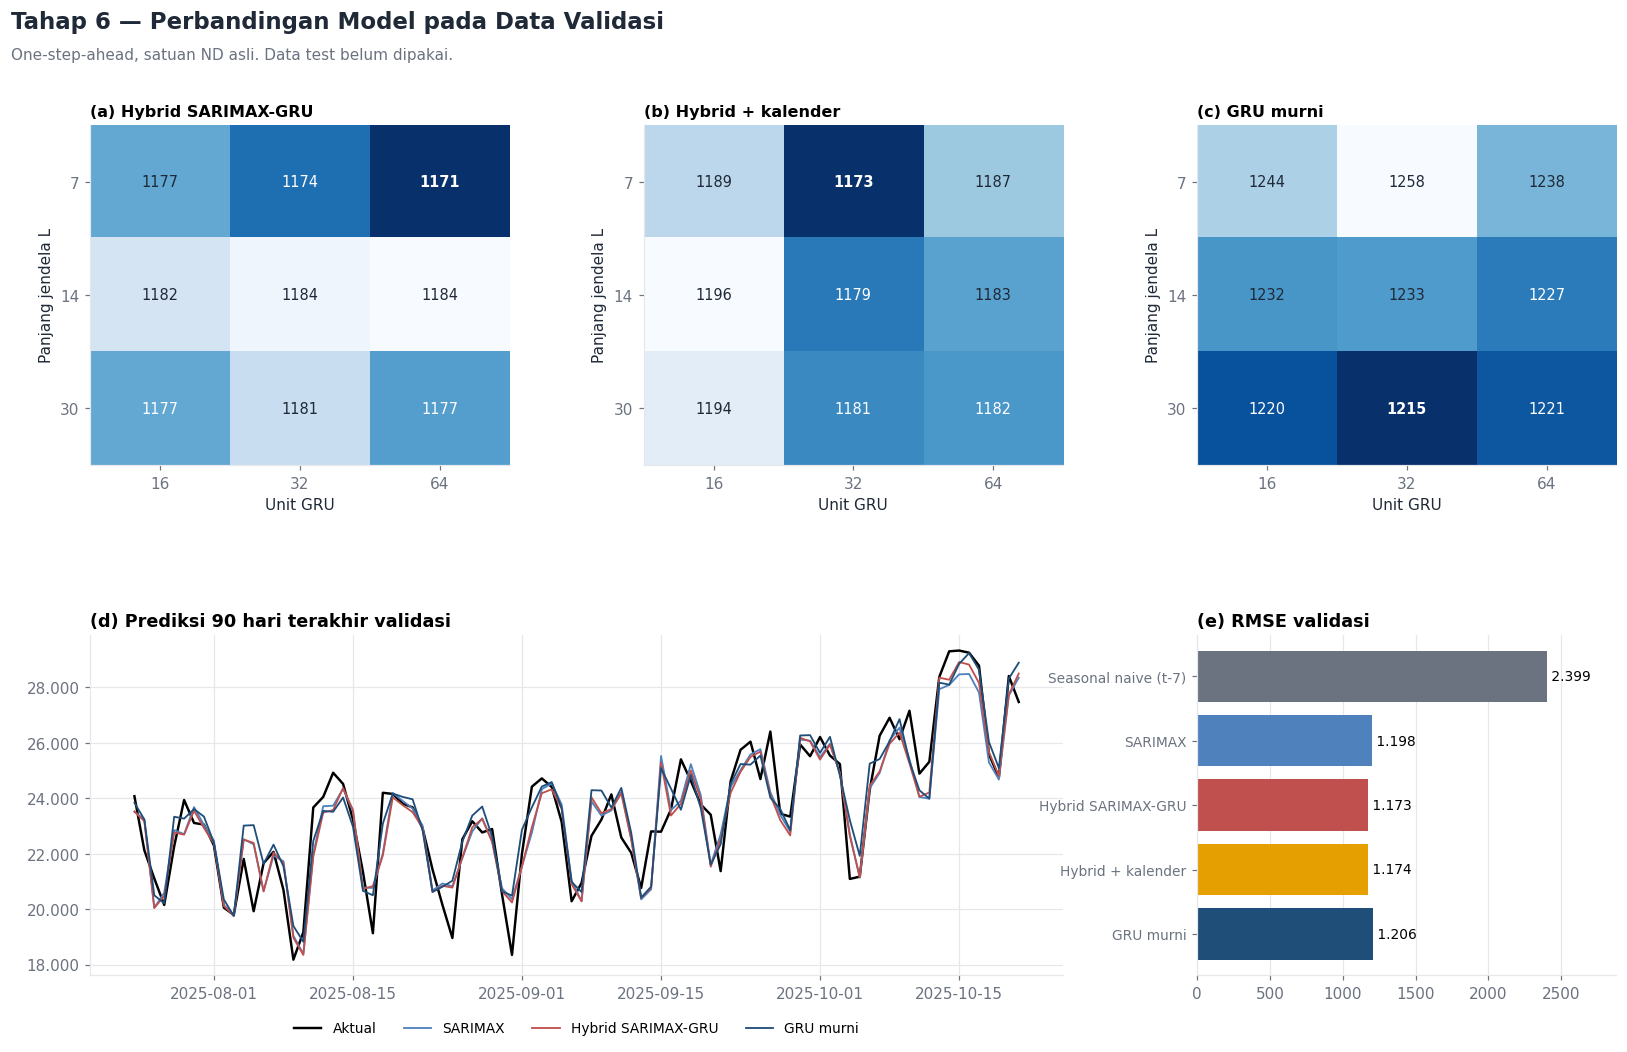

In [80]:
nama_model = list(pred_va_model)
warna_m = {"Seasonal naive (t-7)": PALETTE["neutral"], "SARIMAX": PALETTE["secondary"],
           "Hybrid SARIMAX-GRU": PALETTE["accent"], "Hybrid + kalender": PALETTE["warning"], "GRU murni": PALETTE["primary"]}

fig = plt.figure(figsize=(15, 9.6))
gs = GridSpec(2, 3, figure=fig, hspace=0.5, wspace=0.32, left=0.06, right=0.985, top=0.885, bottom=0.08)
judul_figur(fig, "Tahap 6 — Perbandingan Model pada Data Validasi",
            "One-step-ahead, satuan ND asli. Data test belum dipakai.")

# (a-c) heatmap grid
for k, nama in enumerate(JENIS):
    ax = fig.add_subplot(gs[0, k])
    pv = tabel_grid[nama].pivot(index="L", columns="Unit", values="RMSE validasi")
    im = ax.imshow(pv.values, cmap="Blues_r", aspect="auto")
    ax.set_xticks(range(len(pv.columns))); ax.set_xticklabels(pv.columns)
    ax.set_yticks(range(len(pv.index))); ax.set_yticklabels(pv.index)
    ax.grid(False)
    for (i, j), v in np.ndenumerate(pv.values):
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=9.5,
                color="white" if v < np.nanmedian(pv.values) else PALETTE["text"],
                fontweight="bold" if (pv.index[i], pv.columns[j]) == (BEST[nama]["L"], BEST[nama]["unit"]) else None)
    ax.set_title(f"({'abc'[k]}) {nama}", fontsize=10.5)
    ax.set_xlabel("Unit GRU"); ax.set_ylabel("Panjang jendela L")

# (d) prediksi 90 hari terakhir validasi
ax = fig.add_subplot(gs[1, 0:2])
sl = slice(len(pos_va_all) - 90, None)
idx_v = y.index[pos_va_all][sl]
ax.plot(idx_v, y_va_arr[sl], color="black", lw=1.6, label="Aktual")
for nama in ("SARIMAX", "Hybrid SARIMAX-GRU", "GRU murni"):
    ax.plot(idx_v, pred_va_model[nama][sl], color=warna_m[nama], lw=1.2, label=nama)
ax.yaxis.set_major_formatter(ribuan)
ax.set_title("(d) Prediksi 90 hari terakhir validasi")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1))

# (e) RMSE validasi
ax = fig.add_subplot(gs[1, 2])
vals = [tab_val.loc[n, "RMSE"] for n in nama_model]
ax.barh(range(len(nama_model)), vals, color=[warna_m[n] for n in nama_model])
for i, v in enumerate(vals):
    ax.text(v, i, f" {angka(v)}", va="center", fontsize=9)
ax.set_yticks(range(len(nama_model))); ax.set_yticklabels(nama_model, fontsize=9)
ax.invert_yaxis(); ax.set_xlim(0, max(vals) * 1.2)
ax.grid(axis="y", visible=False)
ax.set_title("(e) RMSE validasi")

simpan_figur(fig, "15_perbandingan_model_validasi")
plt.show()

Figur disimpan: results_2020/figures/16_acf_galat_validasi.png


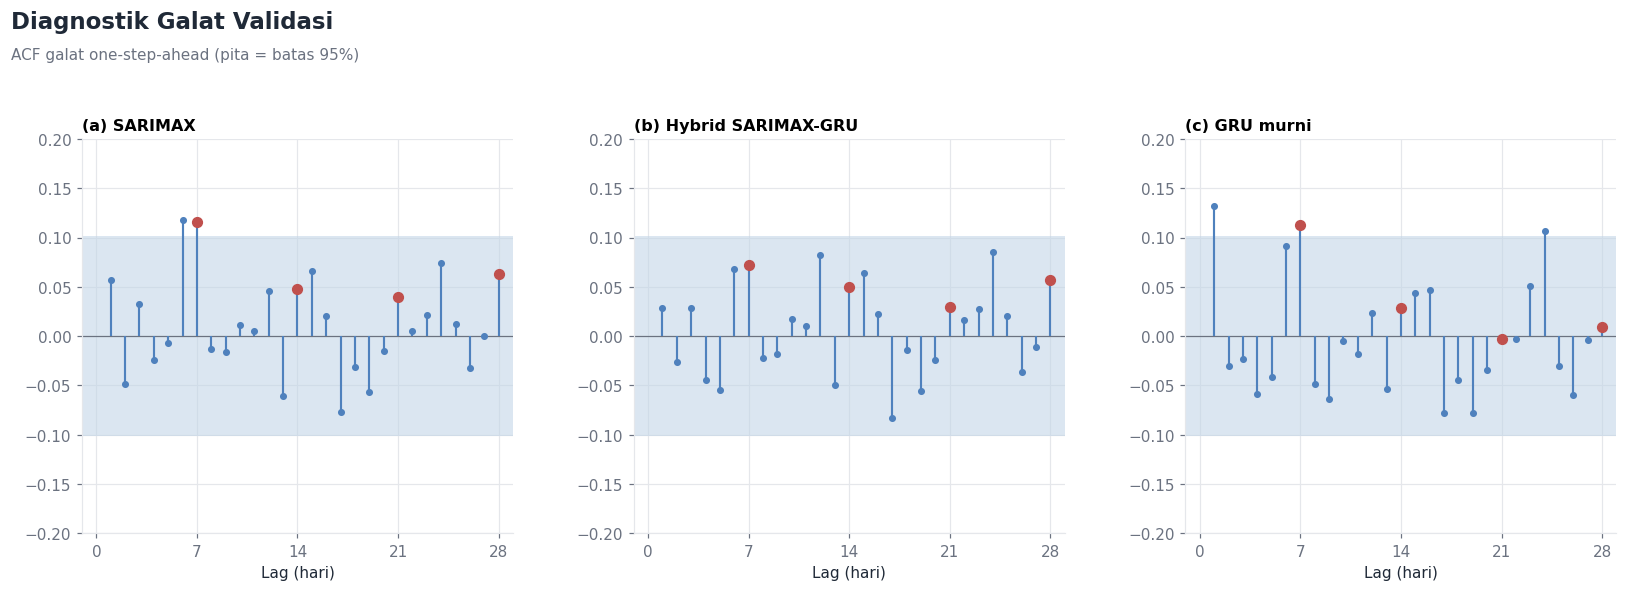

Figur disimpan: results_2020/figures/17_kurva_belajar_gru.png


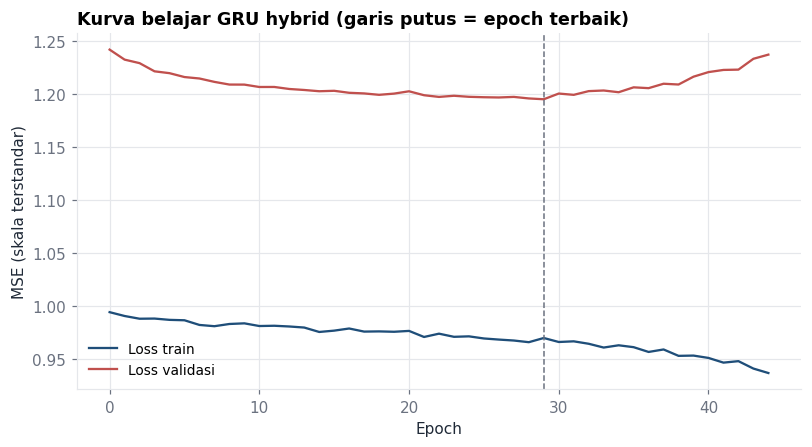

In [81]:
fig = plt.figure(figsize=(15, 5.6))
gs = GridSpec(1, 3, figure=fig, wspace=0.28, left=0.055, right=0.985, top=0.78, bottom=0.14)
judul_figur(fig, "Diagnostik Galat Validasi", "ACF galat one-step-ahead (pita = batas 95%)")
for k, nama in enumerate(["SARIMAX", "Hybrid SARIMAX-GRU", "GRU murni"]):
    ax = fig.add_subplot(gs[k])
    g = y_va_arr - pred_va_model[nama]
    a = acf(g, nlags=28, fft=True)
    stem_acf(ax, a, f"({'abc'[k]}) {nama}", 1.96 / np.sqrt(len(g)), max(0.2, 1.3 * np.abs(a[1:]).max()))
    ax.set_xlabel("Lag (hari)")
simpan_figur(fig, "16_acf_galat_validasi")
plt.show()

# kurva belajar contoh (konfigurasi hybrid terpilih, satu seed)
_, _, rwy = latih_gru("Hybrid SARIMAX-GRU", BEST["Hybrid SARIMAX-GRU"]["L"], BEST["Hybrid SARIMAX-GRU"]["unit"], CFG.seed)
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.plot(rwy["loss"], color=PALETTE["primary"], label="Loss train")
ax.plot(rwy["val_loss"], color=PALETTE["accent"], label="Loss validasi")
ax.axvline(int(np.argmin(rwy["val_loss"])), color=PALETTE["neutral"], ls="--", lw=1)
ax.set_xlabel("Epoch"); ax.set_ylabel("MSE (skala terstandar)")
ax.set_title("Kurva belajar GRU hybrid (garis putus = epoch terbaik)")
ax.legend()
simpan_figur(fig, "17_kurva_belajar_gru")
plt.show()

In [82]:
rek = tab_val["RMSE"].drop("Seasonal naive (t-7)").idxmin()
print("=" * 78)
print("RINGKASAN TAHAP 6 (validasi, one-step-ahead)")
print("=" * 78)
display(tab_val[["RMSE", "MAE", "MAPE", "sMAPE"]].round(3))
print(f"Model dengan RMSE validasi terkecil: {rek}")
sig = tab_dm[tab_dm["DM p-value"] < 0.05]
print("Model yang berbeda signifikan dari SARIMAX (DM p<0,05):", list(sig.index) if len(sig) else "tidak ada")
print("\nCatatan: pilihan model final dan klaim keunggulan dibuat dari hasil TEST pada Tahap 7, bukan dari validasi.")
print("Tahap 6 selesai. Lanjut ke Tahap 7: evaluasi akhir pada data test.")

RINGKASAN TAHAP 6 (validasi, one-step-ahead)


,RMSE,MAE,MAPE,sMAPE
Seasonal naive (t-7),2398.749,1853.385,6.991,6.971
SARIMAX,1198.494,932.968,3.622,3.606
Hybrid SARIMAX-GRU,1173.021,909.914,3.537,3.525
Hybrid + kalender,1174.354,921.917,3.579,3.565
GRU murni,1205.554,927.428,3.624,3.589


Model dengan RMSE validasi terkecil: Hybrid SARIMAX-GRU
Model yang berbeda signifikan dari SARIMAX (DM p<0,05): ['Seasonal naive (t-7)']

Catatan: pilihan model final dan klaim keunggulan dibuat dari hasil TEST pada Tahap 7, bukan dari validasi.
Tahap 6 selesai. Lanjut ke Tahap 7: evaluasi akhir pada data test.


# TAHAP 7 — Evaluasi Akhir pada Data Test

Inilah **satu-satunya** tahap yang memakai data test. Tidak ada pemilihan model atau tuning ulang sebelum angka di bawah ini keluar.
Parameter SARIMAX terkunci dari train; GRU dilatih pada train dengan early stopping pada validasi; scaler dari train.

Dua jenis evaluasi:
1. **One-step-ahead** (format pelaporan penelitian acuan): prediksi hari *t* memakai data sampai *t−1*.
2. **Forecast 30 hari bergulir (rekursif)**: gambaran yang jujur untuk tujuan forecast November. Dari setiap titik asal, model meramal 30 hari tanpa melihat data aktual setelah asal; residual GRU masa depan diramal secara rekursif.

## 7.1 Evaluasi One-Step-Ahead: Train, Validasi, Test

In [83]:
# Perpanjang semua deret sampai akhir data (test). Scaler tetap hasil fit pada train.
N_G = len(y)
y_g = y.to_numpy(float)
_, pred_full = prediksi_satu_langkah(res_sarimax, SPEK_FINAL, N_G)      # parameter terkunci dari train
sar_g = pred_full.to_numpy(float)
resid_g = y_g - sar_g
resid_g[:BURN] = np.nan
E_g = SC_E.transform(regresor(y.index, SPEK_FINAL["K"], dow=True, kal=True).to_numpy())

pos_te_all = np.arange(n_val_end, N_G)
y_te_arr = y_g[pos_te_all]
pred_te_model = {"Seasonal naive (t-7)": y.shift(7).iloc[pos_te_all].to_numpy(),
                 "SARIMAX": sar_g[pos_te_all]}
for nama in JENIS:
    jenis, pakai_e = JENIS[nama]
    L = HASIL[nama]["L"]
    s = seri_skala(jenis)
    X = np.stack([s[j - L:j] for j in pos_te_all])[:, :, None].astype("float32")
    xin = [X, E_g[pos_te_all].astype("float32")] if pakai_e else [X]
    yh = np.mean([m.predict(xin, verbose=0).ravel() for m in HASIL[nama]["models"]], axis=0)
    pred_te_model[nama] = ke_prediksi(nama, yh, pos_te_all)

tab_te = pd.DataFrame({n: ukuran(y_te_arr, p) for n, p in pred_te_model.items()}).T
gabung = pd.concat({"Train": tab_tr, "Validasi": tab_val, "Test": tab_te}, names=["Bagian", "Model"])
laporan = gabung[["RMSE", "MAE", "MAPE", "sMAPE"]].unstack(0).swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)
laporan = laporan.reindex(columns=pd.MultiIndex.from_product([["Train", "Validasi", "Test"], ["RMSE", "MAE", "MAPE", "sMAPE"]]))
display(laporan.round(3))
laporan.round(4).to_csv(Path(CFG.table_dir) / "25_kinerja_train_validasi_test.csv")
print("Satuan RMSE/MAE = MW (ND asli); MAPE/sMAPE = %. Train dihitung dari posisi pertama yang tersedia untuk tiap model "
      "(setelah burn-in SARIMAX dan jendela GRU), selisihnya hanya beberapa hari.")

Train                          Validasi            \
                          RMSE       MAE   MAPE  sMAPE      RMSE       MAE   
Model                                                                        
Seasonal naive (t-7)  2265.574  1719.050  6.400  6.359  2398.749  1853.385   
SARIMAX               1070.937   838.020  3.178  3.166  1198.494   932.968   
Hybrid SARIMAX-GRU    1049.003   817.712  3.106  3.097  1173.021   909.914   
Hybrid + kalender      975.936   762.079  2.897  2.889  1174.354   921.917   
GRU murni              957.007   749.247  2.849  2.841  1205.554   927.428   

                                        Test                          
                       MAPE  sMAPE      RMSE       MAE   MAPE  sMAPE  
Model                                                                 
Seasonal naive (t-7)  6.991  6.971  2273.781  1729.695  6.590  6.569  
SARIMAX               3.622  3.606  1225.457   974.004  3.779  3.763  
Hybrid SARIMAX-GRU    3.537  3.525  1220.220   968.708  3.751  3.740  
Hybrid + kalender     3.579  3.565  1200.929   951.540  3.680  3.670  
GRU murni             3.624  3.589  1215.770   957.503  3.730  3.695

Satuan RMSE/MAE = MW (ND asli); MAPE/sMAPE = %. Train dihitung dari posisi pertama yang tersedia untuk tiap model (setelah burn-in SARIMAX dan jendela GRU), selisihnya hanya beberapa hari.


## 7.2 Uji Diebold–Mariano pada Data Test

H0: akurasi dua model sama (loss kuadrat, Newey–West lag 7). Statistik **positif** berarti model usulan lebih akurat daripada SARIMAX. Karena ada beberapa perbandingan, tafsirkan p-value di sekitar 0,05 dengan hati-hati.

In [84]:
g_sar = y_te_arr - pred_te_model["SARIMAX"]
baris = {}
for nama in pred_te_model:
    if nama == "SARIMAX":
        continue
    g = y_te_arr - pred_te_model[nama]
    s_dm, p_dm = dm_test(g_sar, g)
    baris[nama] = {"Selisih RMSE vs SARIMAX (%)": 100 * (tab_te.loc[nama, "RMSE"] / tab_te.loc["SARIMAX", "RMSE"] - 1),
                   "DM stat": s_dm, "DM p-value": p_dm,
                   "Ljung-Box p (lag 7)": float(acorr_ljungbox(pd.Series(g), lags=[7], return_df=True)["lb_pvalue"].iloc[0])}
# pasangan hybrid vs GRU murni
for a, b in [("Hybrid + kalender", "GRU murni"), ("Hybrid SARIMAX-GRU", "GRU murni")]:
    s_dm, p_dm = dm_test(y_te_arr - pred_te_model[b], y_te_arr - pred_te_model[a])
    baris[f"{a} vs {b}"] = {"Selisih RMSE vs SARIMAX (%)": np.nan, "DM stat": s_dm, "DM p-value": p_dm, "Ljung-Box p (lag 7)": np.nan}
tab_dm_te = pd.DataFrame(baris).T
display(tab_dm_te.round(4))
tab_dm_te.round(4).to_csv(Path(CFG.table_dir) / "26_uji_dm_test.csv")

,Selisih RMSE vs SARIMAX (%),DM stat,DM p-value,Ljung-Box p (lag 7)
Seasonal naive (t-7),85.5455,-4.8805,0.0000,0.0000
Hybrid SARIMAX-GRU,-0.4274,0.6263,0.5311,0.4209
Hybrid + kalender,-2.0016,1.7547,0.0793,0.6042
GRU murni,-0.7906,0.4672,0.6404,0.9839
Hybrid + kalender vs GRU murni,NaN,0.9410,0.3467,NaN
Hybrid SARIMAX-GRU vs GRU murni,NaN,-0.2182,0.8272,NaN


## 7.3 Forecast 30 Hari Bergulir (Rekursif) pada Data Test

Titik asal digeser tiap 30 hari di dalam data test. Pada setiap asal:
- SARIMAX meramal 30 hari ke depan (parameter terkunci dari train, state diperbarui sampai asal);
- GRU meramal residual 30 hari secara **rekursif** (prediksi sendiri dipakai sebagai input langkah berikutnya), dengan fitur kalender hari target;
- hybrid = prediksi SARIMAX + residual GRU.

Ini meniru situasi forecast 1–30 November 2026, sehingga angkanya lebih realistis daripada one-step-ahead.

In [85]:
HOR = H
ASAL = list(range(n_val_end, N_G - HOR + 1, HOR))
X_semua = regresor(y.index, SPEK_FINAL["K"], SPEK_FINAL["dow"], SPEK_FINAL["kal"])
SC_JENIS = {"resid": SC_R, "nd": SC_Y}


def sarimax_ramal(t):
    y_t = ke_skala(y.iloc[:t], SPEK_FINAL["mode"])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        r = res_sarimax.apply(y_t, exog=X_semua.iloc[:t], refit=False)
        fc = r.forecast(HOR, exog=X_semua.iloc[t:t + HOR])
    return np.asarray(ke_asli(np.asarray(fc), SPEK_FINAL["mode"]), float)


def ramal_rekursif(nama, models, s_hist, E_masa_depan, sar_fc, scaler):
    """Forecast rekursif HOR langkah. s_hist: deret terskala (hanya masa lalu); keluaran dalam satuan ND asli."""
    jenis, pakai_e = JENIS[nama]
    L = int(models[0].input_shape[0][1]) if isinstance(models[0].input_shape, list) else int(models[0].input_shape[1])
    buf = list(np.asarray(s_hist, float)[-L:])
    keluar = []
    for h in range(HOR):
        x = np.asarray(buf[-L:], dtype="float32")[None, :, None]
        inp = [x, np.asarray(E_masa_depan[h], dtype="float32")[None]] if pakai_e else [x]
        p = float(np.mean([float(np.asarray(m(inp, training=False)).ravel()[0]) for m in models]))
        buf.append(p)
        keluar.append(p)
    inv = scaler.inverse_transform(np.array(keluar).reshape(-1, 1)).ravel()
    return sar_fc + inv if jenis == "resid" else inv


ROLL = {n: [] for n in ["Seasonal naive (t-7)", "SARIMAX", *JENIS]}
AKT = []
t0 = time.time()
for t in ASAL:
    sar_fc = sarimax_ramal(t)
    ROLL["SARIMAX"].append(sar_fc)
    ROLL["Seasonal naive (t-7)"].append(np.tile(y_g[t - 7:t], 6)[:HOR])
    AKT.append(y_g[t:t + HOR])
    for nama, (jenis, _) in JENIS.items():
        s = seri_skala(jenis)
        ROLL[nama].append(ramal_rekursif(nama, HASIL[nama]["models"], s[:t], E_g[t:t + HOR], sar_fc, SC_JENIS[jenis]))
    print(f"asal {tgl(y.index[t])}: selesai [{(time.time() - t0) / 60:.1f} menit]")
ROLL = {k: np.array(v) for k, v in ROLL.items()}
AKT = np.array(AKT)

baris = {}
sel = np.concatenate([np.arange(t, t + HOR) for t in ASAL])
for nama, mat in ROLL.items():
    u = ukuran(AKT.ravel(), mat.ravel())
    u["RMSE 1 langkah (hari yang sama)"] = ukuran(y_g[sel], pred_te_model[nama][sel - n_val_end])["RMSE"]
    baris[nama] = u
tab_roll = pd.DataFrame(baris).T
tab_roll["Rasio 30 hari / 1 langkah"] = tab_roll["RMSE"] / tab_roll["RMSE 1 langkah (hari yang sama)"]
print(f"{len(ASAL)} jendela x {HOR} hari pada data test ({tgl(y.index[ASAL[0]])} s.d. {tgl(y.index[ASAL[-1] + HOR - 1])})")
display(tab_roll.round(3))
tab_roll.round(4).to_csv(Path(CFG.table_dir) / "27_kinerja_30hari_bergulir_test.csv")
rmse_h = pd.DataFrame({n: np.sqrt(((AKT - m) ** 2).mean(axis=0)) for n, m in ROLL.items()}, index=range(1, HOR + 1))
rmse_h.round(2).to_csv(Path(CFG.table_dir) / "28_rmse_per_horizon_test.csv")

asal 22 Okt 2025: selesai [0.7 menit]
asal 21 Nov 2025: selesai [1.3 menit]
asal 21 Des 2025: selesai [2.0 menit]
asal 20 Jan 2026: selesai [2.7 menit]
asal 19 Feb 2026: selesai [3.3 menit]
asal 21 Mar 2026: selesai [4.0 menit]
asal 20 Apr 2026: selesai [4.7 menit]
asal 20 Mei 2026: selesai [5.3 menit]
asal 19 Jun 2026: selesai [6.0 menit]
asal 19 Jul 2026: selesai [6.7 menit]
asal 18 Agu 2026: selesai [7.3 menit]
asal 17 Sep 2026: selesai [8.0 menit]
12 jendela x 30 hari pada data test (22 Okt 2025 s.d. 16 Okt 2026)


,RMSE,MAE,MAPE,sMAPE,RMSE 1 langkah (hari yang sama),Rasio 30 hari / 1 langkah
Seasonal naive (t-7),2459.559,1909.991,7.402,7.221,2263.641,1.087
SARIMAX,1617.113,1252.115,4.816,4.774,1213.831,1.332
Hybrid SARIMAX-GRU,1610.389,1243.103,4.777,4.740,1202.894,1.339
Hybrid + kalender,1601.829,1235.555,4.740,4.699,1187.410,1.349
GRU murni,1759.709,1370.870,5.283,5.145,1205.010,1.460


## 7.4 Visualisasi Evaluasi Test

Figur disimpan: results_2020/figures/18_evaluasi_test_satu_langkah.png


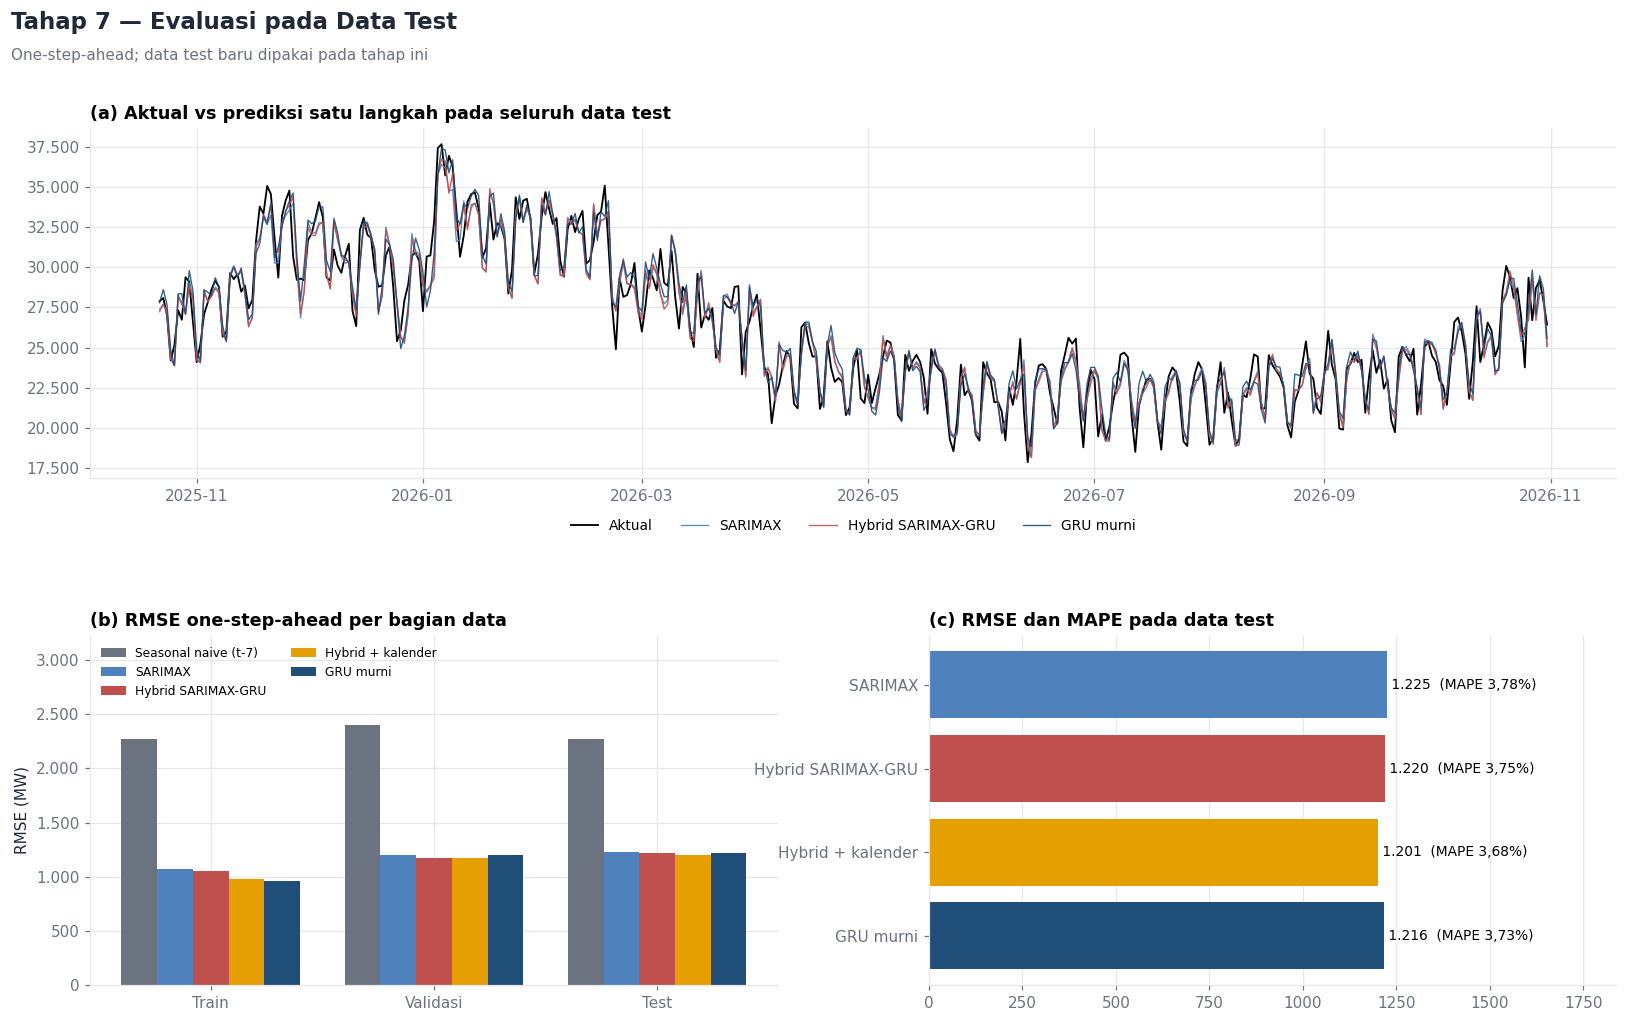

In [86]:
warna_m = {"Seasonal naive (t-7)": PALETTE["neutral"], "SARIMAX": PALETTE["secondary"],
           "Hybrid SARIMAX-GRU": PALETTE["accent"], "Hybrid + kalender": PALETTE["warning"], "GRU murni": PALETTE["primary"]}
nama_model = list(pred_te_model)

fig = plt.figure(figsize=(15, 9.8))
gs = GridSpec(2, 2, figure=fig, hspace=0.45, wspace=0.22, left=0.06, right=0.985, top=0.885, bottom=0.09)
judul_figur(fig, "Tahap 7 — Evaluasi pada Data Test", "One-step-ahead; data test baru dipakai pada tahap ini")

ax = fig.add_subplot(gs[0, :])
idx_t = y.index[pos_te_all]
ax.plot(idx_t, y_te_arr, color="black", lw=1.2, label="Aktual")
for nama in ("SARIMAX", "Hybrid SARIMAX-GRU", "GRU murni"):
    ax.plot(idx_t, pred_te_model[nama], color=warna_m[nama], lw=0.9, alpha=0.9, label=nama)
ax.yaxis.set_major_formatter(ribuan)
ax.set_title("(a) Aktual vs prediksi satu langkah pada seluruh data test")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.08))

ax = fig.add_subplot(gs[1, 0])
bagian = ["Train", "Validasi", "Test"]
lebar = 0.16
for k, nama in enumerate(nama_model):
    ax.bar(np.arange(3) + (k - 2) * lebar, [gabung.loc[(b, nama), "RMSE"] for b in bagian], lebar, color=warna_m[nama], label=nama)
ax.set_xticks(range(3)); ax.set_xticklabels(bagian)
ax.yaxis.set_major_formatter(ribuan)
ax.set_ylabel("RMSE (MW)")
ax.set_title("(b) RMSE one-step-ahead per bagian data")
ax.set_ylim(0, ax.get_ylim()[1] * 1.28)
ax.legend(fontsize=8, ncol=2, loc="upper left")

ax = fig.add_subplot(gs[1, 1])
urut = [n for n in nama_model if n != "Seasonal naive (t-7)"]
vals = [tab_te.loc[n, "RMSE"] for n in urut]
ax.barh(range(len(urut)), vals, color=[warna_m[n] for n in urut])
for i, n in enumerate(urut):
    ax.text(vals[i], i, f" {angka(vals[i])}  (MAPE {angka(tab_te.loc[n, 'MAPE'], 2)}%)", va="center", fontsize=9)
ax.set_yticks(range(len(urut))); ax.set_yticklabels(urut)
ax.invert_yaxis(); ax.set_xlim(0, max(vals) * 1.5)
ax.grid(axis="y", visible=False)
ax.set_title("(c) RMSE dan MAPE pada data test")
simpan_figur(fig, "18_evaluasi_test_satu_langkah")
plt.show()

Figur disimpan: results_2020/figures/19_forecast_30hari_bergulir_test.png


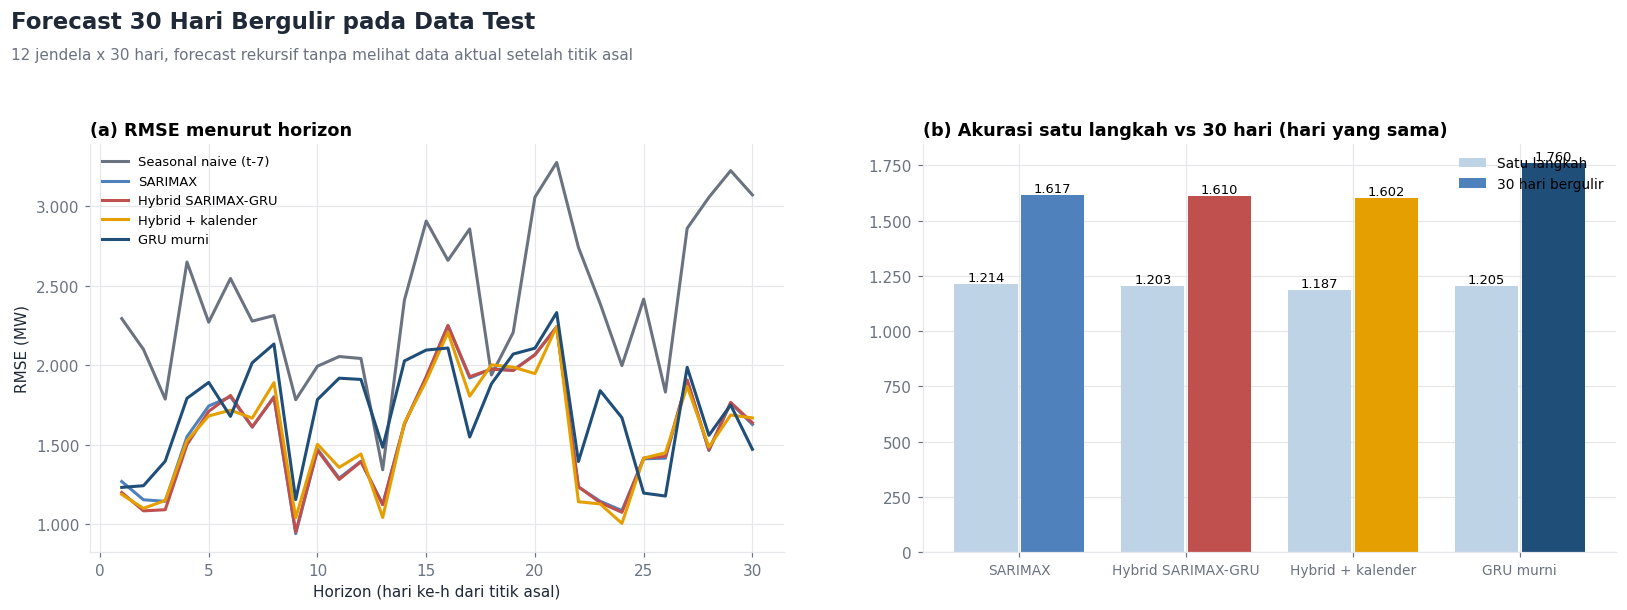

Figur disimpan: results_2020/figures/20_acf_galat_test.png


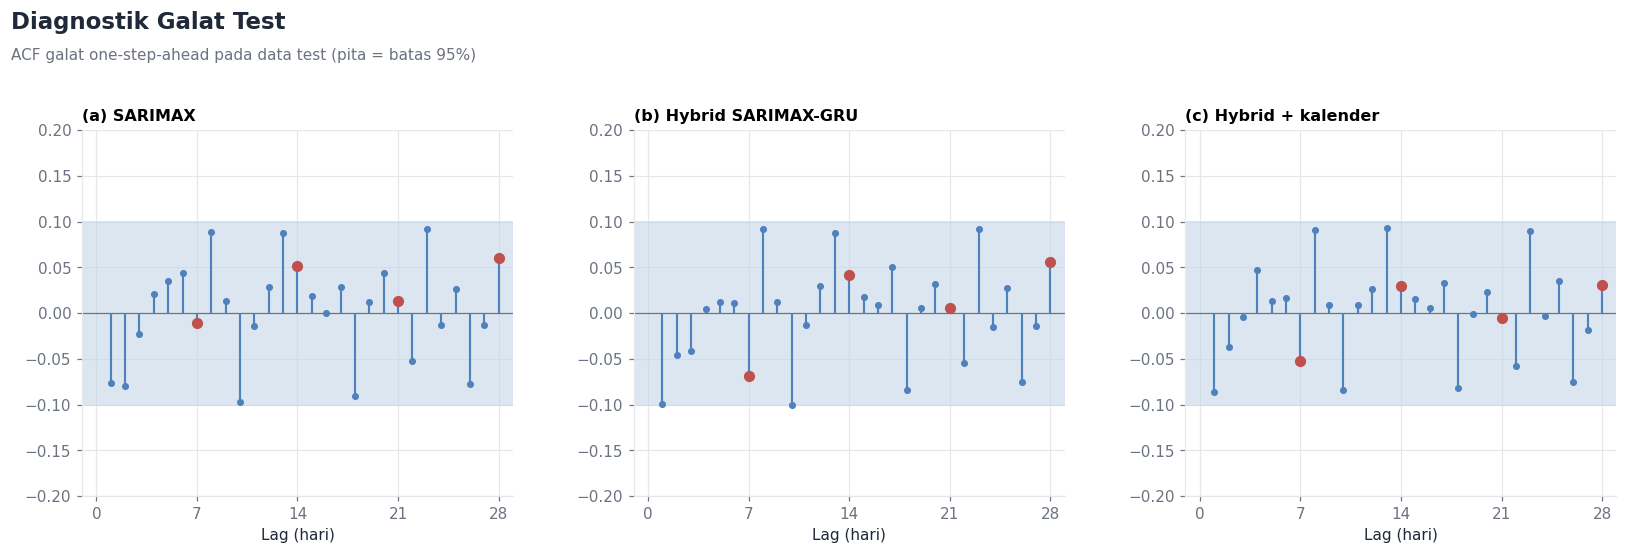

In [87]:
fig = plt.figure(figsize=(15, 5.8))
gs = GridSpec(1, 2, figure=fig, wspace=0.2, left=0.06, right=0.985, top=0.78, bottom=0.14)
judul_figur(fig, "Forecast 30 Hari Bergulir pada Data Test", f"{len(ASAL)} jendela x {HOR} hari, forecast rekursif tanpa melihat data aktual setelah titik asal")
ax = fig.add_subplot(gs[0])
for nama in ROLL:
    ax.plot(rmse_h.index, rmse_h[nama], color=warna_m[nama], lw=2, label=nama)
ax.yaxis.set_major_formatter(ribuan)
ax.set_xlabel("Horizon (hari ke-h dari titik asal)"); ax.set_ylabel("RMSE (MW)")
ax.set_title("(a) RMSE menurut horizon")
ax.legend(fontsize=8.5)
ax = fig.add_subplot(gs[1])
urut = [n for n in ROLL if n != "Seasonal naive (t-7)"]
xx = np.arange(len(urut))
ax.bar(xx - 0.2, [tab_roll.loc[n, "RMSE 1 langkah (hari yang sama)"] for n in urut], 0.38, color=PALETTE["light"], label="Satu langkah")
ax.bar(xx + 0.2, [tab_roll.loc[n, "RMSE"] for n in urut], 0.38, color=[warna_m[n] for n in urut], label="30 hari bergulir")
for i, n in enumerate(urut):
    ax.text(i + 0.2, tab_roll.loc[n, "RMSE"], angka(tab_roll.loc[n, "RMSE"]), ha="center", va="bottom", fontsize=8.5)
    ax.text(i - 0.2, tab_roll.loc[n, "RMSE 1 langkah (hari yang sama)"], angka(tab_roll.loc[n, "RMSE 1 langkah (hari yang sama)"]), ha="center", va="bottom", fontsize=8.5)
ax.set_xticks(xx); ax.set_xticklabels(urut, fontsize=9)
ax.yaxis.set_major_formatter(ribuan)
ax.set_title("(b) Akurasi satu langkah vs 30 hari (hari yang sama)")
ax.legend()
simpan_figur(fig, "19_forecast_30hari_bergulir_test")
plt.show()

fig = plt.figure(figsize=(15, 5.2))
gs = GridSpec(1, 3, figure=fig, wspace=0.28, left=0.055, right=0.985, top=0.78, bottom=0.14)
judul_figur(fig, "Diagnostik Galat Test", "ACF galat one-step-ahead pada data test (pita = batas 95%)")
for k, nama in enumerate(["SARIMAX", "Hybrid SARIMAX-GRU", "Hybrid + kalender"]):
    ax = fig.add_subplot(gs[k])
    g = y_te_arr - pred_te_model[nama]
    a = acf(g, nlags=28, fft=True)
    stem_acf(ax, a, f"({'abc'[k]}) {nama}", 1.96 / np.sqrt(len(g)), max(0.2, 1.3 * np.abs(a[1:]).max()))
    ax.set_xlabel("Lag (hari)")
simpan_figur(fig, "20_acf_galat_test")
plt.show()

In [88]:
print("=" * 78)
print("RINGKASAN TAHAP 7")
print("=" * 78)
print("One-step-ahead pada TEST:")
display(tab_te[["RMSE", "MAE", "MAPE", "sMAPE"]].round(3))
sig = tab_dm_te.loc[[n for n in pred_te_model if n not in ("SARIMAX",)]]
for n, r in sig.iterrows():
    arah = "lebih baik" if r["DM stat"] > 0 else "lebih buruk"
    tanda = "signifikan" if r["DM p-value"] < 0.05 else "tidak signifikan"
    print(f"  {n:<22} vs SARIMAX: {arah} {abs(r['Selisih RMSE vs SARIMAX (%)']):.1f}% RMSE, DM p = {r['DM p-value']:.3f} ({tanda})")
print("\nForecast 30 hari bergulir pada TEST:")
display(tab_roll[["RMSE", "MAE", "MAPE", "sMAPE"]].round(3))
print("Tahap 7 selesai. Lanjut ke Tahap 8: refit pada seluruh data dan forecast 1-30 November 2026.")

RINGKASAN TAHAP 7
One-step-ahead pada TEST:


,RMSE,MAE,MAPE,sMAPE
Seasonal naive (t-7),2273.781,1729.695,6.590,6.569
SARIMAX,1225.457,974.004,3.779,3.763
Hybrid SARIMAX-GRU,1220.220,968.708,3.751,3.740
Hybrid + kalender,1200.929,951.540,3.680,3.670
GRU murni,1215.770,957.503,3.730,3.695


  Seasonal naive (t-7)   vs SARIMAX: lebih buruk 85.5% RMSE, DM p = 0.000 (signifikan)
  Hybrid SARIMAX-GRU     vs SARIMAX: lebih baik 0.4% RMSE, DM p = 0.531 (tidak signifikan)
  Hybrid + kalender      vs SARIMAX: lebih baik 2.0% RMSE, DM p = 0.079 (tidak signifikan)
  GRU murni              vs SARIMAX: lebih baik 0.8% RMSE, DM p = 0.640 (tidak signifikan)

Forecast 30 hari bergulir pada TEST:


,RMSE,MAE,MAPE,sMAPE
Seasonal naive (t-7),2459.559,1909.991,7.402,7.221
SARIMAX,1617.113,1252.115,4.816,4.774
Hybrid SARIMAX-GRU,1610.389,1243.103,4.777,4.740
Hybrid + kalender,1601.829,1235.555,4.740,4.699
GRU murni,1759.709,1370.870,5.283,5.145


Tahap 7 selesai. Lanjut ke Tahap 8: refit pada seluruh data dan forecast 1-30 November 2026.


# TAHAP 8 — Refit pada Seluruh Data dan Forecast 1–30 November 2026

Setelah evaluasi selesai, semua model di-**refit pada train + validasi + test** supaya forecast memakai informasi terbaru (sampai 31 Oktober 2026).
- Struktur dan hyperparameter dikunci dari tahap sebelumnya; scaler di-fit ulang pada seluruh data.
- Karena tidak ada lagi data validasi, GRU dilatih dengan **jumlah epoch tetap** (median epoch terbaik dari Tahap 6).
- Forecast GRU bersifat rekursif; interval 95% diambil dari **distribusi empiris galat forecast 30 hari pada data test** (Tahap 7.3), per horizon (jendela ±3 hari).

## 8.1 Pemilihan Model Final

In [89]:
MODEL_FINAL = None      # None = otomatis (RMSE forecast 30 hari bergulir terkecil pada test); atau isi nama model secara manual
kandidat = tab_roll["RMSE"].drop("Seasonal naive (t-7)")
MODEL_FINAL = MODEL_FINAL or kandidat.idxmin()
urut_k = kandidat.sort_values()
print("RMSE forecast 30 hari bergulir pada test:")
for n, v in urut_k.items():
    print(f"  {n:<22} {v:9.1f}" + ("   <- model final" if n == MODEL_FINAL else ""))
selisih = 100 * (urut_k.iloc[1] / urut_k.iloc[0] - 1)
if selisih < 2:
    print(f"\nCATATAN: selisih model terbaik dan kedua hanya {selisih:.1f}%, yaitu di dalam kebisingan. Pemilihan ini lemah; "
          "pertimbangkan mengisi MODEL_FINAL secara manual berdasarkan argumen teoretis dan laporkan semua forecast.")

RMSE forecast 30 hari bergulir pada test:
  Hybrid + kalender         1601.8   <- model final
  Hybrid SARIMAX-GRU        1610.4
  SARIMAX                   1617.1
  GRU murni                 1759.7

CATATAN: selisih model terbaik dan kedua hanya 0.5%, yaitu di dalam kebisingan. Pemilihan ini lemah; pertimbangkan mengisi MODEL_FINAL secara manual berdasarkan argumen teoretis dan laporkan semua forecast.


## 8.2 Refit SARIMAX pada Seluruh Data

In [90]:
def fit_sarimax_semua(spek):
    trend = "c" if (spek["order"][1] == 0 and spek["sorder"][1] == 0) else None
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        model = SARIMAX(ke_skala(y, spek["mode"]), exog=regresor(y.index, spek["K"], spek["dow"], spek["kal"]),
                        order=spek["order"], seasonal_order=spek["sorder"], trend=trend,
                        enforce_stationarity=False, enforce_invertibility=False)
        return model.fit(disp=False, maxiter=300)


res_all = fit_sarimax_semua(SPEK_FINAL)
IDX_F = pd.date_range(y.index[-1] + pd.Timedelta(days=1), periods=H, freq="D")
assert IDX_F[0] == pd.Timestamp("2026-11-01") and IDX_F[-1] == pd.Timestamp("2026-11-30"), "Forecast harus 1-30 November 2026"
X_f = regresor(IDX_F, SPEK_FINAL["K"], SPEK_FINAL["dow"], SPEK_FINAL["kal"])
fc_obj = res_all.get_forecast(H, exog=X_f)
sar_fc_f = np.asarray(ke_asli(np.asarray(fc_obj.predicted_mean), SPEK_FINAL["mode"]), float)
print(f"SARIMAX refit pada {len(y)} hari ({tgl(y.index[0])} s.d. {tgl(y.index[-1])}); AIC = {res_all.aic:,.1f}".replace(",", "."))
print(f"Akar AR/MA terkecil = {akar_minimum(res_all):.3f}")
display(pd.DataFrame({"Koefisien lama (train)": res_sarimax.params, "Koefisien baru (semua data)": res_all.params}).round(4))

SARIMAX refit pada 2496 hari (01 Jan 2020 s.d. 31 Okt 2026); AIC = -8.639.5
Akar AR/MA terkecil = 1.014


,Koefisien lama (train),Koefisien baru (semua data)
sin1,0.0264,0.0218
cos1,0.1682,0.1798
sin2,0.0050,0.0073
cos2,0.0174,0.0212
sin3,-0.0062,-0.0027
cos3,-0.0067,-0.0118
sin4,-0.0049,-0.0005
cos4,-0.0039,-0.0062
sin5,-0.0053,-0.0017
cos5,-0.0105,-0.0104


## 8.3 Refit GRU pada Seluruh Data dan Forecast Rekursif

In [91]:
N_ALL = len(y)
y_all = y.to_numpy(float)
sar_all = np.asarray(ke_asli(res_all.fittedvalues, SPEK_FINAL["mode"]), float)
resid_all = y_all - sar_all
resid_all[:BURN] = np.nan

SCR2 = StandardScaler().fit(resid_all[BURN:].reshape(-1, 1))
SCY2 = StandardScaler().fit(y_all.reshape(-1, 1))
E_df = regresor(y.index, SPEK_FINAL["K"], dow=True, kal=True)
SCE2 = StandardScaler().fit(E_df.to_numpy())
E_all = SCE2.transform(E_df.to_numpy())
E_f = SCE2.transform(regresor(IDX_F, SPEK_FINAL["K"], dow=True, kal=True).to_numpy())
S_ALL = {"resid": SCR2.transform(np.nan_to_num(resid_all).reshape(-1, 1)).ravel(),
         "nd": SCY2.transform(y_all.reshape(-1, 1)).ravel()}
SC2 = {"resid": SCR2, "nd": SCY2}

FC = {"SARIMAX": sar_fc_f}
t0 = time.time()
for nama, (jenis, pakai_e) in JENIS.items():
    L, unit, ep = HASIL[nama]["L"], HASIL[nama]["unit"], max(HASIL[nama]["epoch"], 5)
    s = S_ALL[jenis]
    awal = (BURN + L) if jenis == "resid" else L
    pos = np.arange(awal, N_ALL)
    X = np.stack([s[j - L:j] for j in pos])[:, :, None].astype("float32")
    Y = s[pos].astype("float32")
    xin = [X, E_all[pos].astype("float32")] if pakai_e else [X]
    modelku = []
    for sd in SEEDS:
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(sd)
        m = bangun_gru(L, unit, pakai_e)
        m.fit(xin, Y, epochs=ep, batch_size=32, verbose=0)
        modelku.append(m)
    FC[nama] = ramal_rekursif(nama, modelku, s, E_f, sar_fc_f, SC2[jenis])
    print(f"{nama:<20} L={L}, unit={unit}, epoch tetap={ep}, 5 seed  [{(time.time() - t0) / 60:.1f} menit]")

Hybrid SARIMAX-GRU   L=7, unit=64, epoch tetap=24, 5 seed  [1.6 menit]
Hybrid + kalender    L=7, unit=32, epoch tetap=24, 5 seed  [3.1 menit]
GRU murni            L=30, unit=32, epoch tetap=54, 5 seed  [9.5 menit]


## 8.4 Hasil Forecast 1–30 November 2026

Interval 95% memakai galat forecast 30 hari pada data test untuk model final (per horizon, jendela ±3 hari). Dengan hanya beberapa belas jendela, interval ini perkiraan kasar, bukan jaminan cakupan 95%.

In [92]:
err = AKT - ROLL[MODEL_FINAL]                       # (jendela, horizon)
lo, hi = np.zeros(HOR), np.zeros(HOR)
for h in range(HOR):
    a, b = max(0, h - 3), min(HOR, h + 4)
    q = np.quantile(err[:, a:b].ravel(), [0.025, 0.975])
    lo[h], hi[h] = q
fc_final = FC[MODEL_FINAL]

HARI = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]
hasil = pd.DataFrame({"Tanggal": IDX_F.date, "Hari": [HARI[d.dayofweek] for d in IDX_F],
                      f"Forecast ({MODEL_FINAL})": fc_final,
                      "Batas bawah 95%": fc_final + lo, "Batas atas 95%": fc_final + hi})
for n in FC:
    if n != MODEL_FINAL:
        hasil[f"Forecast {n}"] = FC[n]
hasil.insert(0, "Hari ke", range(1, HOR + 1))
display(hasil.set_index("Tanggal").round(0))
hasil.round(2).to_csv(Path(CFG.table_dir) / "forecast_november_2026.csv", index=False)
print("Disimpan:", Path(CFG.table_dir) / "forecast_november_2026.csv")

# --- pemeriksaan kewajaran ---
nov = y[y.index.month == 11]
rata_nov = nov.groupby(nov.index.year).mean()
print("\nRata-rata ND bulan November per tahun (data historis):", {int(k): round(v) for k, v in rata_nov.items()})
print(f"Rata-rata forecast November 2026 ({MODEL_FINAL}): {fc_final.mean():,.0f} | rentang {fc_final.min():,.0f} - {fc_final.max():,.0f}".replace(",", "."))
rata_hari = y[y.index.year >= 2024].groupby(y[y.index.year >= 2024].index.dayofweek).mean()
print("Pola hari: forecast rata-rata Sabtu/Minggu =", f"{np.mean([f for f, d in zip(fc_final, IDX_F) if d.dayofweek >= 5]):,.0f}".replace(",", "."),
      "| hari kerja =", f"{np.mean([f for f, d in zip(fc_final, IDX_F) if d.dayofweek < 5]):,.0f}".replace(",", "."))
if not (rata_nov.min() * 0.85 <= fc_final.mean() <= rata_nov.max() * 1.15):
    print("PERINGATAN: rata-rata forecast di luar rentang historis November +-15%. Periksa kembali.")

,Hari ke,Hari,Forecast (Hybrid + kalender),Batas bawah 95%,Batas atas 95%,Forecast SARIMAX,Forecast Hybrid SARIMAX-GRU,Forecast GRU murni
Tanggal,,,,,,,,
2026-11-01,1,Minggu,25383.0,22480.0,27291.0,25762.0,25685.0,25729.0
2026-11-02,2,Senin,28925.0,25816.0,30831.0,29108.0,29068.0,29103.0
2026-11-03,3,Selasa,29204.0,25977.0,31403.0,29439.0,29414.0,29666.0
2026-11-04,4,Rabu,29212.0,25969.0,31354.0,29495.0,29497.0,29909.0
2026-11-05,5,Kamis,29303.0,26060.0,31717.0,29461.0,29463.0,30103.0
2026-11-06,6,Jumat,28674.0,25431.0,31088.0,28859.0,28853.0,29668.0
2026-11-07,7,Sabtu,26247.0,22549.0,28661.0,26192.0,26229.0,27027.0
2026-11-08,8,Minggu,25682.0,21902.0,28096.0,25874.0,25837.0,26614.0
2026-11-09,9,Senin,29189.0,25409.0,31603.0,29503.0,29475.0,30024.0


Disimpan: results_2020/tables/forecast_november_2026.csv

Rata-rata ND bulan November per tahun (data historis): {2020: 30096, 2021: 31180, 2022: 27987, 2023: 29685, 2024: 30581, 2025: 29786}
Rata-rata forecast November 2026 (Hybrid + kalender): 29.234 | rentang 25.383 - 31.735
Pola hari: forecast rata-rata Sabtu/Minggu = 26.904 | hari kerja = 30.232


Figur disimpan: results_2020/figures/21_forecast_november_2026.png


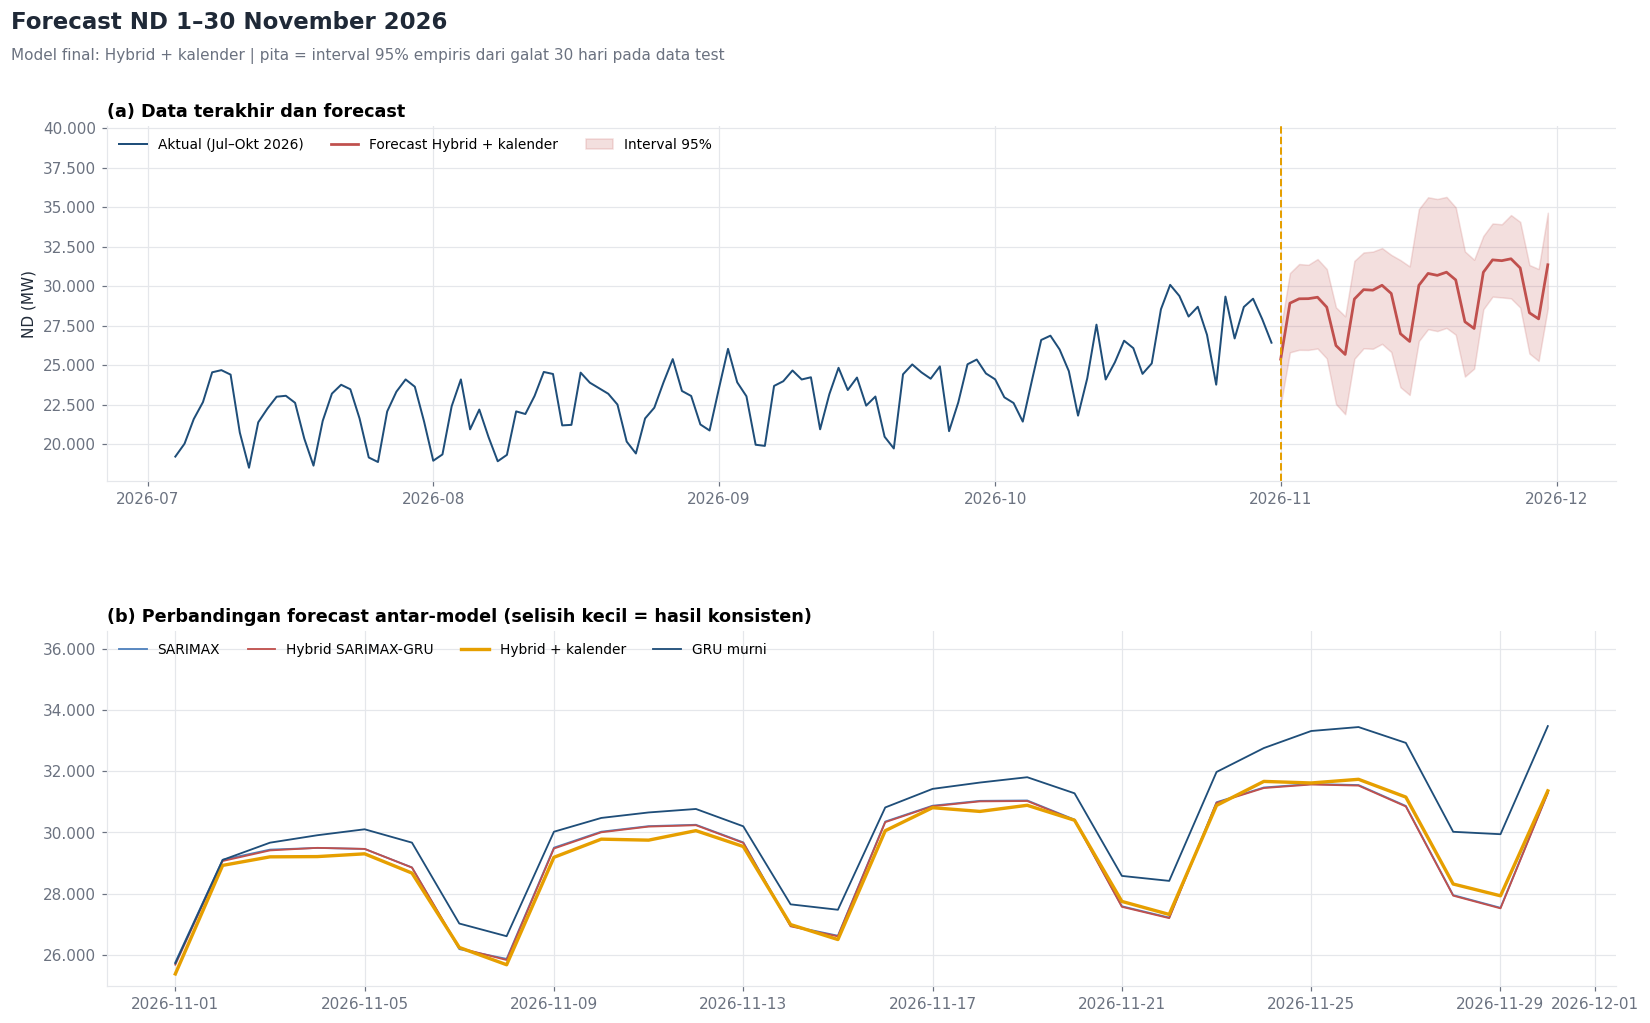

RINGKASAN TAHAP 8
Model final       : Hybrid + kalender
Periode forecast  : 01 Nov 2026 s.d. 30 Nov 2026 (30 hari)
Rata-rata forecast: 29.234 MW
File hasil        : results/tables/forecast_november_2026.csv


In [93]:
fig = plt.figure(figsize=(15, 9.6))
gs = GridSpec(2, 1, figure=fig, hspace=0.42, left=0.07, right=0.985, top=0.885, bottom=0.07)
judul_figur(fig, "Forecast ND 1–30 November 2026", f"Model final: {MODEL_FINAL} | pita = interval 95% empiris dari galat 30 hari pada data test")

ax = fig.add_subplot(gs[0])
riw = y.iloc[-120:]
ax.plot(riw.index, riw, color=PALETTE["primary"], lw=1.3, label="Aktual (Jul–Okt 2026)")
ax.plot(IDX_F, fc_final, color=PALETTE["accent"], lw=1.8, label=f"Forecast {MODEL_FINAL}")
ax.fill_between(IDX_F, fc_final + lo, fc_final + hi, color=PALETTE["accent"], alpha=0.18, label="Interval 95%")
ax.axvline(IDX_F[0], color=PALETTE["warning"], ls="--", lw=1.3)
ax.yaxis.set_major_formatter(ribuan)
ax.set_ylabel("ND (MW)")
ax.set_title("(a) Data terakhir dan forecast")
ax.set_ylim(top=ax.get_ylim()[1] * 1.1)
ax.legend(loc="upper left", ncol=3)

ax = fig.add_subplot(gs[1])
for n, f in FC.items():
    ax.plot(IDX_F, f, color=warna_m[n], lw=2.2 if n == MODEL_FINAL else 1.2, label=n)
ax.yaxis.set_major_formatter(ribuan)
ax.set_title("(b) Perbandingan forecast antar-model (selisih kecil = hasil konsisten)")
ax.set_ylim(top=ax.get_ylim()[1] * 1.08)
ax.legend(ncol=4, loc="upper left", fontsize=9)
simpan_figur(fig, "21_forecast_november_2026")
plt.show()

print("=" * 78)
print("RINGKASAN TAHAP 8")
print("=" * 78)
print(f"Model final       : {MODEL_FINAL}")
print(f"Periode forecast  : {tgl(IDX_F[0])} s.d. {tgl(IDX_F[-1])} ({HOR} hari)")
print(f"Rata-rata forecast: {fc_final.mean():,.0f} MW".replace(",", "."))
print("File hasil        : results/tables/forecast_november_2026.csv")

## Catatan untuk Bab Pembahasan dan Keterbatasan

1. **One-step-ahead lebih optimistis** daripada forecast 30 hari: lihat rasio pada tabel 7.3. Laporkan keduanya.
2. **Klaim keunggulan hybrid** hanya sah jika uji DM pada data test mendukungnya; selisih kecil yang tidak signifikan dilaporkan apa adanya.
3. **Asumsi:** data adalah ND NESO Inggris (kalender libur England & Wales). Pola kalender di luar itu tidak ditangkap.
4. **Galat tidak normal dan varians tidak konstan** (JB dan ARCH-LM menolak): interval berbasis distribusi normal tidak dipakai; interval di sini empiris.
5. **Interval 95%** berasal dari beberapa belas jendela test, sehingga kasar.
6. Efek **COVID-19 2020** dimodelkan dengan dummy; hari raya yang jatuh pada akhir pekan dan cuaca ekstrem tidak dimodelkan.
7. Pemilihan model final memakai data test; ini membuat estimasi kinerja forecast agak optimistis. Sebut ini dalam skripsi.